In [1]:
import json, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import seaborn as sns

sys.path.insert(0, str(Path('../..').resolve()))
from analysis.metrics_summary import (
    strict_accuracy, conservative_accuracy, resolution_rate,
    false_shared_claim_rate, false_confidence_rate,
    confusion_matrix, confusion_counts, scenario_rate, power_curve, summary_table,
    clopper_pearson, mixed_scenario_resolution_accuracy, indeterminate_sensitivity,
)

import glob
import string
from matplotlib.patches import Patch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import beta as beta_dist
from simulator.simulator import SimulatorConfig, simulate_run
from evaluation.prototypes import compute_prototypes
from metrics.anorm import compute_anorm_null
from metrics.bnorm import compute_bnorm_null
from metrics.delta_shared import compute_delta_shared, compute_delta_shared_null
from evaluation.probes import make_cv_splits

plt.rcParams.update({
    'figure.dpi': 150,
    'font.family': 'serif',
    'font.size': 9,
    'axes.titlesize': 9,
    'axes.labelsize': 9,
    'legend.fontsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
})

# DATA_DIR: root of the extracted data.tar.xz archive.
DATA_DIR    = Path('../../data')

FIGURES_DIR = Path('../../figures/manuscript')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = DATA_DIR / 'main_experiment/results'
D_QUANTILE_DIR = DATA_DIR / 'd_quantile_sweeps'

def save_fig(fig, name, df_csv=None):
    fig.savefig(FIGURES_DIR / f'{name}.pdf', bbox_inches='tight')
    if df_csv is not None:
        df_csv.to_csv(FIGURES_DIR / f'{name}.csv', index=False)
    print(f'Saved {name}')

In [2]:
MODEL_LABELS = {
    'cca_K50':              'CCA',
    'clip_K50':             'CLIP',
    'jive_K50':             'JIVE',
    'dssl_l0.01_b0.01_K50': 'DSSL(0.01)',
    'dssl_l0.1_b0.1_K50':   'DSSL(0.1)',
    'dssl_l1.0_b1.0_K50':   'DSSL(1.0)',
    'dssl_l10.0_b10.0_K50': 'DSSL(10.0)',
}
MODEL_ORDER = list(MODEL_LABELS.values())
COLORS = {
    'CCA': '#1f77b4', 'CLIP': '#ff7f0e', 'JIVE': '#d62728',
    'DSSL(0.01)': '#d4e6c3', 'DSSL(0.1)': '#74c476',
    'DSSL(1.0)': '#31a354', 'DSSL(10.0)': '#006d2c',
} 
REGIME_ORDER = ['baseline', 'shared_dominant', 'batch_dominant', 'modality_dominant']
REGIME_COLORS = {
    'baseline': '#17becf', 'shared_dominant': '#bcbd22',
    'batch_dominant': '#3b1f5e', 'modality_dominant': '#8c564b',
}
REGIME_LABELS = {
    'baseline': 'Baseline (beta_s=beta_h=beta_r=1, beta_b=0.75)',
    'shared_dominant': 'Shared-dominant (beta_s=2)',
    'batch_dominant': 'Batch-dominant (beta_b=1.5)',
    'modality_dominant': 'Modality-dominant (beta_h=beta_r=2)',
}

ALPHA_VALS = [0.25, 0.5, 0.8, 1.1]
N_EVAL_VALS = [50, 100, 200, 500, 1000]
ALPHA_SCENARIOS = [
    ('scenario_1', 'alpha_s', 's1',  None),
    ('scenario_2', 'alpha_b', 's2b', None),
    ('scenario_4', 'alpha_h', 's4h', 'h'),
]
SCENARIO_LABELS = {'scenario_1': 'S1', 'scenario_2': 'S2B', 'scenario_4': 'S4h'}

GT_LABELS  = {'scenario_2':'S2B','scenario_3':'S3','scenario_4':'S4'}
GT_ORDER   = ['scenario_2','scenario_3','scenario_4']

# Scenario color palette — consistent across all figures
# S2 subtypes use a red family (S2B=strong, S2A/C/D=progressively lighter)
SC_COLORS = {
    'scenario_1':    '#bcbd22',  # olive  (shared signal)
    'scenario_2':    '#3b1f5e',  # dark purple            (confounding, generic)
    'scenario_2b':   '#6a3d9a',  # purple            (S2B direct confounding)
    'scenario_2a':   '#3b1f5e',  # dark purple      (S2A proxy single-modal H&E)
    'scenario_2c':   '#9467bd',  # lighter purple       (S2C aligned proxy)
    'scenario_2d':   '#e0d0ee',  # pale purple      (S2D dual-modal proxy)
    'scenario_3':    '#17becf',  # cyan          (noise null)
    'scenario_4':    '#8c564b',  # brown         (modality-specific)
    'indeterminate': '#7f7f7f',  # grey
}


GT_COLORS = SC_COLORS  # alias — use SC_COLORS directly in new code

DSSL_MODELS = ['DSSL(0.01)', 'DSSL(0.1)', 'DSSL(1.0)', 'DSSL(10.0)']
PLOT_MODELS = ['CCA', 'CLIP', 'JIVE', 'DSSL-median']
SCEN_COLORS_M = SC_COLORS  # alias — use SC_COLORS directly in new code
SCEN_ORDER_M = ['scenario_1','scenario_2','scenario_3','scenario_4','indeterminate']
SCEN_LABELS_M = {'scenario_1':'S1','scenario_2':'S2','scenario_3':'S3',
                 'scenario_4':'S4','indeterminate':'indet.'}
COL_TITLES_M = {
    'mixed_a': 'Mixed A\n(GT: RNA=S1, H&E=S4)',
    'mixed_b': 'Mixed B\n(GT: H&E=S4, RNA=S4)',
    'mixed_c': 'Mixed C\n(shared + proxy, eta=0.3)',
    'mixed_d': 'Mixed D\n(shared + confounding)',
}
PROXY_CONDS_DEF = [
    ('Weak\n(gamma=0.3,eta=0.3)',     'g0.3_r0_e0.3_',  r's2a_.*_g0.3_e0.3'),
    ('Moderate\n(gamma=0.5,eta=0.3)', 'g0.5_r0_e0.3_',  r's2a_.*_g0.5_e0.3'),
    ('Strong\n(gamma=1.0,eta=0.3)',   'g1.0_r0_e0.3_',  r's2a_.*_g1.0_e0.3'),
    ('Aligned\n(gamma=0.5,eta=0)',    'g0.5_r0_e0_',    r's2a_.*_g0\.5_e0\.0'),
    ('Dual-modal\n(gamma=0.5/0.5)',   'g0.5_r0.5_e0_',  r's2a_.*_g0\.5_e0\.0'),
]
ALPHA_VALS_P = [0.25, 0.5, 0.8, 1.1]
_ALPHA_COL_LATEX = {
    'alpha_s': r'$\alpha_s$', 'alpha_b': r'$\alpha_b$',
    'alpha_h': r'$\alpha_h$', 'alpha_r': r'$\alpha_r$',
}


def make_regime_alpha_fig(regime, fname_stem):
    plt.rcParams.update({
        'font.family': 'DejaVu Sans', 'font.size': 16,
        'axes.titlesize': 16, 'axes.labelsize': 16,
        'xtick.labelsize': 16, 'ytick.labelsize': 16, 'legend.fontsize': 16,
    })
    _PLS = 18  # panel label size

    _TITLES = {
        'scenario_1': 'S1\n(Shared signal)\n',
        'scenario_2': 'S2B\n(Confounder)\n',
        'scenario_4': 'S4h\n(Modality-specific signal)\n',
    }
    _XLABELS = {'alpha_s': '$\\alpha_s$', 'alpha_b': '$\\alpha_b$', 'alpha_h': '$\\alpha_h$'}
    _YLABELS = {False: 'Strict accuracy\n', True: 'Conservative accuracy\n'}

    df_r = df_pure[
        (df_pure['measurement_regime'] == regime) & (~df_pure['is_proxy_run']) & (df_pure['n_eval'] == 1000)
    ]
    fig = plt.figure(figsize=(20, 11))
    gs_r = GridSpec(2, 4, figure=fig, width_ratios=[4,4,4,1.5], hspace=0.8, wspace=0.35)
    axes_r = [[fig.add_subplot(gs_r[r,c]) for c in range(4)] for r in range(2)]

    rows = []
    for row_i, (is_consv, _) in enumerate([(False, 'Strict'), (True, 'Conservative')]):
        for col_i, (gt, alpha_col, prefix, mod_filter) in enumerate(ALPHA_SCENARIOS):
            ax = axes_r[row_i][col_i]
            base = df_r[df_r['alpha_config_id'].str.startswith(prefix) & (df_r['ground_truth'] == gt)]
            if mod_filter: base = base[base['modality'] == mod_filter]
            for model in MODEL_ORDER:
                sub = base[base['model_label'] == model]
                rates, ci_lo, ci_hi = [], [], []
                for a in ALPHA_VALS:
                    s = sub[sub[alpha_col] == a]; n = len(s)
                    k = int(((s['predicted_scenario']==gt)|(s['predicted_scenario']=='indeterminate')).sum()) if is_consv else int((s['predicted_scenario']==gt).sum())
                    lo, hi = clopper_pearson(k, n) if n > 0 else (float('nan'), float('nan'))
                    rates.append(k/n if n > 0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
                    rows.append({'scenario': gt, 'alpha_col': alpha_col, 'alpha_val': a, 'model': model,
                                 'row_type': 'conservative' if is_consv else 'strict',
                                 'rate': k/n if n > 0 else float('nan'), 'ci_lower': lo, 'ci_upper': hi})
                rates = np.array(rates)
                ax.errorbar(ALPHA_VALS, rates,
                            yerr=[np.maximum(0,rates-np.array(ci_lo)), np.maximum(0,np.array(ci_hi)-rates)],
                            fmt='o-', color=COLORS[model], lw=2, markersize=6,
                            capsize=4, capthick=1.2, elinewidth=1.2, label=model)
            ax.set_xticks(ALPHA_VALS); ax.set_ylim(-0.05, 1.05); ax.grid(False)
            ax.set_title(_TITLES[gt])
            if col_i == 0: ax.set_ylabel(_YLABELS[is_consv])
            ax.set_xlabel(_XLABELS[alpha_col])

        ax = axes_r[row_i][3]
        base_s3 = df_r[df_r['alpha_config_id'].str.startswith('s3') & (df_r['ground_truth'] == 'scenario_3')]
        for m_i, model in enumerate(MODEL_ORDER):
            sub = base_s3[base_s3['model_label'] == model]; n = len(sub)
            if n == 0: continue
            k = int(((sub['predicted_scenario']=='scenario_3')|(sub['predicted_scenario']=='indeterminate')).sum()) if is_consv else int((sub['predicted_scenario']=='scenario_3').sum())
            rate = k/n; lo, hi = clopper_pearson(k, n)
            ax.errorbar((m_i-(len(MODEL_ORDER)-1)/2)*0.04, rate,
                        yerr=[[np.maximum(0,rate-lo)],[np.maximum(0,hi-rate)]],
                        fmt='o', color=COLORS[model], markersize=7, capsize=4, capthick=1.2, elinewidth=1.2)
            rows.append({'scenario':'scenario_3','alpha_col':'none','alpha_val':0.0,'model':model,
                         'row_type':'conservative' if is_consv else 'strict',
                         'rate':rate,'ci_lower':lo,'ci_upper':hi})
        ax.set_xlim(-0.35,0.35); ax.set_xticks([0.0]); ax.set_xticklabels(['0'])
        ax.set_ylim(-0.05,1.05); ax.grid(False)
        ax.set_xlabel('all $\\alpha$'); ax.set_title('S3\n(noise)\n')

    for idx, ax in enumerate([axes_r[r][c] for r in range(2) for c in range(4)]):
        ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.', transform=ax.transAxes,
                fontweight='bold', fontsize=_PLS, va='bottom', ha='right', clip_on=False)

    fig.subplots_adjust(left=0.12, right=0.82, top=0.95, bottom=0.12, hspace=0.8, wspace=0.35)

    x0 = axes_r[0][0].get_position().x0; x1 = axes_r[0][3].get_position().x1
    x_c = (x0+x1)/2
    fig.text(x_c, axes_r[0][0].get_position().y0-0.07, 'Predictive task signal', ha='center', va='top', fontsize=16)
    fig.text(x_c, axes_r[1][0].get_position().y0-0.07, 'Predictive task signal', ha='center', va='top', fontsize=16)

    handles, labels = axes_r[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', ncol=1, bbox_to_anchor=(0.83, 0.5), frameon=False)

    plt.show()
    save_fig(fig, fname_stem, pd.DataFrame(rows))
    plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,
                         'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})

def make_regime_fscr_fig(regime, fname_stem):
    plt.rcParams.update({
        'font.family': 'DejaVu Sans', 'font.size': 18,
        'axes.titlesize': 18, 'axes.labelsize': 18,
        'xtick.labelsize': 18, 'ytick.labelsize': 18, 'legend.fontsize': 18,
    })
    _PLS = 20

    df_r = df_pure[
        (df_pure['measurement_regime'] == regime) & (~df_pure['is_proxy_run']) & (df_pure['ground_truth'] != 'scenario_1')
    ]
    fig = plt.figure(figsize=(20, 5.5))
    gs_f = GridSpec(1, 4, figure=fig, width_ratios=[4, 4, 3, 4], wspace=0.4)
    ax_a   = fig.add_subplot(gs_f[0, 0])
    ax_b   = fig.add_subplot(gs_f[0, 1])
    ax_leg = fig.add_subplot(gs_f[0, 2]); ax_leg.axis('off')
    ax_c   = fig.add_subplot(gs_f[0, 3])

    rows = []
    for model in MODEL_ORDER:
        rates, ci_lo, ci_hi = [], [], []
        for a in [0.25, 0.5, 0.8, 1.1]:
            sub = pd.concat([
                df_r[(df_r['model_label']==model)&(df_r['n_eval']==1000)&df_r['alpha_config_id'].str.startswith('s2b')&(df_r['alpha_b']==a)],
                df_r[(df_r['model_label']==model)&(df_r['n_eval']==1000)&df_r['alpha_config_id'].str.startswith('s3')],
                df_r[(df_r['model_label']==model)&(df_r['n_eval']==1000)&df_r['alpha_config_id'].str.startswith('s4h')&(df_r['alpha_h']==a)],
                df_r[(df_r['model_label']==model)&(df_r['n_eval']==1000)&df_r['alpha_config_id'].str.startswith('s4r')&(df_r['alpha_r']==a)],
            ])
            n=len(sub); k=int((sub['predicted_scenario']=='scenario_1').sum())
            lo,hi=clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
            rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
            rows.append({'panel':'alpha','model':model,'alpha_val':a,'n_eval':1000,'scenario':'pooled',
                         'fscr':k/n if n>0 else float('nan'),'ci_lower':lo,'ci_upper':hi})
        rates=np.array(rates)
        ax_a.errorbar([0.25,0.5,0.8,1.1], rates,
                      yerr=[np.maximum(0,rates-np.array(ci_lo)),np.maximum(0,np.array(ci_hi)-rates)],
                      fmt='o-', color=COLORS[model], lw=2, markersize=6,
                      capsize=4, capthick=1.2, elinewidth=1.2, label=model)
    ax_a.set_xticks([0.25,0.5,0.8,1.1])
    ax_a.set_xlabel('\nPredictive task signal ($\\alpha$)'); ax_a.set_ylabel('FSCR\n')
    ax_a.set_ylim(-0.02, 0.55); ax_a.set_title('FSCR vs signal strength\n'); ax_a.grid(False)

    for model in MODEL_ORDER:
        rates, ci_lo, ci_hi = [], [], []
        for ne in [50,100,200,500,1000]:
            sub=df_r[(df_r['model_label']==model)&(df_r['n_eval']==ne)]
            n=len(sub); k=int((sub['predicted_scenario']=='scenario_1').sum())
            lo,hi=clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
            rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
            rows.append({'panel':'n_eval','model':model,'alpha_val':float('nan'),'n_eval':ne,
                         'scenario':'pooled','fscr':k/n if n>0 else float('nan'),'ci_lower':lo,'ci_upper':hi})
        _r=np.array(rates)
        ax_b.errorbar([50,100,200,500,1000], rates,
                      yerr=[np.maximum(0,_r-np.array(ci_lo)),np.maximum(0,np.array(ci_hi)-_r)],
                      fmt='o-', color=COLORS[model], lw=2, markersize=6,
                      capsize=4, capthick=1.2, elinewidth=1.2, label=model)
    ax_b.set_xscale('log'); ax_b.set_xticks([50, 100, 200, 500, 1000]); ax_b.set_xticklabels([50, 100, 200, 500, 1000]); ax_b.set_xlabel('\nEvaluation cohort size ($N_{eval}$)'); ax_b.set_ylabel('FSCR\n')
    ax_b.set_title('FSCR vs evaluation cohort size\n'); ax_b.grid(False)

    handles, labels = ax_a.get_legend_handles_labels()
    ax_leg.legend(handles, labels, loc='center left', frameon=False, ncol=1, bbox_to_anchor=(0.0,0.5))

    GT_ORDER_F=['scenario_2','scenario_3','scenario_4']; GT_LBL_F={'scenario_2':'S2B','scenario_3':'S3','scenario_4':'S4'}
    n_m=len(MODEL_ORDER); n_g=len(GT_ORDER_F); bw=0.25; gg=0.30; xtp,xtl=[],[]
    for m_i, model in enumerate(MODEL_ORDER):
        gc=m_i*(n_g*bw+gg)
        for g_i, gt in enumerate(GT_ORDER_F):
            sub=df_r[(df_r['model_label']==model)&(df_r['n_eval']==1000)&(df_r['ground_truth']==gt)]
            n=len(sub); k=int((sub['predicted_scenario']=='scenario_1').sum())
            rate=k/n if n>0 else float('nan'); lo,hi=clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
            x=gc+g_i*bw
            ax_c.bar(x,rate,bw,color=SC_COLORS[gt],alpha=0.85,label=GT_LBL_F[gt] if m_i==0 else '')
            ax_c.errorbar(x,rate,yerr=[[np.maximum(0,rate-lo)],[np.maximum(0,hi-rate)]],fmt='none',color='black',capsize=3,lw=1)
            rows.append({'panel':'by_scenario','model':model,'alpha_val':float('nan'),'n_eval':1000,
                         'scenario':gt,'fscr':rate,'ci_lower':lo,'ci_upper':hi})
        xtp.append(gc+(n_g-1)*bw/2); xtl.append(model)
    ax_c.set_xlim(-bw,(n_m-1)*(n_g*bw+gg)+n_g*bw); ax_c.set_xticks(xtp)
    ax_c.set_xticklabels(xtl, rotation=30, ha='center'); ax_c.set_ylabel('FSCR\n')
    ax_c.set_title('FSCR by true scenario\n'); ax_c.grid(False)
    ax_c.legend(title='True scenario', loc='center left', bbox_to_anchor=(1.01,0.5), frameon=False)

    for idx, ax in enumerate([ax_a, ax_b, ax_c]):
        ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.', transform=ax.transAxes,
                fontweight='bold', fontsize=_PLS, va='bottom', ha='right', clip_on=False)

    fig.subplots_adjust(left=0.07, right=0.97, top=0.90, bottom=0.25)
    pos_b=ax_b.get_position(); pos_leg=ax_leg.get_position()
    ax_leg.set_position([pos_b.x1+0.01, pos_leg.y0, pos_leg.width, pos_leg.height])
    pos_c=ax_c.get_position(); ax_c.set_position([pos_c.x0-0.08, pos_c.y0, pos_c.width, pos_c.height])

    plt.show()
    save_fig(fig, fname_stem, pd.DataFrame(rows))
    plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,
                         'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})

def make_proxy_alpha_fig(detect_gt, alpha_col, alpha_prefix, s2a_mode, suptitle, fname):
    plt.rcParams.update({
        'font.family':      'DejaVu Sans',
        'font.size':        16,
        'axes.titlesize':   16,
        'axes.labelsize':   16,
        'xtick.labelsize':  16,
        'ytick.labelsize':  16,
        'legend.fontsize':  16,
    })
    _PANEL_LABEL_SIZE = 18

    N_C = len(PROXY_CONDS_DEF)
    fig = plt.figure(figsize=(22, 9))
    gs3 = GridSpec(2, N_C, figure=fig, hspace=0.55, wspace=0.25)
    axes3 = [[fig.add_subplot(gs3[r, c]) for c in range(N_C)] for r in range(2)]

    _xlabel = '\n' + _ALPHA_COL_LATEX.get(alpha_col, alpha_col)
    df_proxy_1000 = df[(df['is_proxy_run']) & (df['n_eval'] == 1000)]
    rows = []
    for col_i, (cond_label, run_frag, s2a_pat) in enumerate(PROXY_CONDS_DEF):
        sub_cond = df_proxy_1000[df_proxy_1000['run_id'].str.contains(run_frag, regex=False)]
        if s2a_mode:
            sub_cond = sub_cond[sub_cond['alpha_config_id'].str.startswith(alpha_prefix) &
                                sub_cond['alpha_config_id'].str.match(s2a_pat)]
        else:
            sub_cond = sub_cond[sub_cond['alpha_config_id'].str.startswith(alpha_prefix)]
        for row_i, is_consv in enumerate([False, True]):
            ax = axes3[row_i][col_i]
            row_type = 'conservative' if is_consv else 'strict'
            for model in MODEL_ORDER:
                sub_m = sub_cond[sub_cond['model_label'] == model]
                rates, ci_lo, ci_hi = [], [], []
                for a in ALPHA_VALS_P:
                    s = sub_m[sub_m[alpha_col] == a]; n = len(s)
                    k = int(((s['predicted_scenario']==detect_gt)|
                              (s['predicted_scenario']=='indeterminate')).sum()) if is_consv \
                        else int((s['predicted_scenario']==detect_gt).sum())
                    lo, hi = clopper_pearson(k, n) if n > 0 else (float('nan'), float('nan'))
                    rates.append(k/n if n > 0 else float('nan'))
                    ci_lo.append(lo); ci_hi.append(hi)
                    rows.append({'cond_label': cond_label, 'alpha_col': alpha_col, 'alpha_val': a,
                                 'detect_gt': detect_gt, 'model': model, 'row_type': row_type,
                                 'rate': k/n if n > 0 else float('nan'), 'ci_lower': lo, 'ci_upper': hi})
                rates = np.array(rates)
                ax.errorbar(ALPHA_VALS_P, rates,
                            yerr=[np.maximum(0, rates-np.array(ci_lo)),
                                  np.maximum(0, np.array(ci_hi)-rates)],
                            fmt='o-', color=COLORS[model], lw=2, markersize=6,
                            capsize=4, capthick=1.2, elinewidth=1.2, label=model)
            ax.set_xticks(ALPHA_VALS_P); ax.set_ylim(-0.05, 1.05); ax.grid(False)
            if row_i == 0:
                ax.set_title(cond_label + '\n')
            if col_i == 0:
                ax.set_ylabel(('Conservative accuracy' if is_consv else 'Strict accuracy') + '\n')
            ax.set_xlabel(_xlabel)

    # Panel labels
    for idx, ax in enumerate([axes3[r][c] for r in range(2) for c in range(N_C)]):
        ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
                transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
                va='bottom', ha='right', clip_on=False)

    fig.subplots_adjust(left=0.07, right=0.83, top=0.92, bottom=0.12, hspace=0.55, wspace=0.25)

    handles, labels = axes3[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', ncol=1, bbox_to_anchor=(0.84, 0.5), frameon=False)

    plt.show()
    save_fig(fig, fname, pd.DataFrame(rows))
    plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,
                         'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})



def make_mixed_per_modality_fig(regime, fname_stem):
    regime_lbl = regime.replace('_', ' ').title()
    fig, axes_mm = plt.subplots(2, 4, figsize=(20, 9), sharey=True)
    fig.suptitle(
        f'Per-modality scenario classification on mixed-signal tasks\n'
        f'{regime_lbl} regime, N_eval=1000',
        fontsize=13
    )
    for col_i, mtype in enumerate(['mixed_a', 'mixed_b', 'mixed_c', 'mixed_d']):
        is_proxy_type = mtype == 'mixed_c'
        sub_type = df[
            (df['alpha_config_id'].str.startswith(mtype)) &
            (df['is_proxy_run'] == is_proxy_type) &
            (df['measurement_regime'] == regime) &
            (df['n_eval'] == 1000)
        ]
        for row_i, (mod, mod_label) in enumerate([('h', 'H&E'), ('r', 'RNA')]):
            ax = axes_mm[row_i, col_i]
            sub_mod = sub_type[sub_type['modality'] == mod]
            for m_i, model in enumerate(PLOT_MODELS):
                if model == 'DSSL-median':
                    sub_m = sub_mod[sub_mod['model_label'].isin(DSSL_MODELS)]
                else:
                    sub_m = sub_mod[sub_mod['model_label'] == model]
                n = len(sub_m)
                if n == 0: continue
                bottom = 0.0
                for scen in SCEN_ORDER_M:
                    frac = int((sub_m['predicted_scenario'] == scen).sum()) / n
                    if frac < 1e-6: continue
                    ax.bar(m_i, frac, 0.55, bottom=bottom,
                           color=SCEN_COLORS_M[scen], alpha=0.88,
                           hatch='///' if scen == 'indeterminate' else '',
                           edgecolor='white', linewidth=0.5)
                    bottom += frac
            ax.set_xticks(range(len(PLOT_MODELS)))
            ax.set_xticklabels([m.replace('DSSL-', 'DSSL\n') for m in PLOT_MODELS], fontsize=8)
            ax.set_ylim(0, 1.08); ax.grid(axis='y', alpha=0.25, zorder=0)
            if row_i == 0: ax.set_title(COL_TITLES_M[mtype], fontsize=10)
            if col_i == 0: ax.set_ylabel(f'{mod_label}\nFraction', fontsize=11)
    legend_handles_mm = [Patch(facecolor=SCEN_COLORS_M[s], alpha=0.88,
        label=SCEN_LABELS_M[s], hatch='///' if s == 'indeterminate' else '',
        edgecolor='white') for s in SCEN_ORDER_M]
    fig.legend(handles=legend_handles_mm, loc='lower center', ncol=5, fontsize=10,
        bbox_to_anchor=(0.5, -0.04), title='Predicted scenario', title_fontsize=10)
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    save_fig(fig, fname_stem)
    plt.show()



print('Cell 2 (utilities) loaded.')


Cell 2 (utilities) loaded.


In [3]:
RESULTS = RESULTS_DIR
files = sorted(RESULTS.glob('*.json'))
print(f'Loading {len(files)} result files...')

records = []
for f in files:
    run_id = f.stem
    is_proxy = run_id.startswith('proxy')
    parts = run_id.split('_')
    measurement_regime = '_'.join(parts[1:-1]) if not is_proxy else '_'.join(parts[4:-1])
    for r in json.load(open(f)):
        r['measurement_regime'] = measurement_regime
        r['is_proxy_run'] = is_proxy
        records.append(r)

df = pd.DataFrame(records)
df['model_label'] = df['model'].map(MODEL_LABELS)
print(f'Total records: {len(df):,}')


def expected_scenario(cid: str, modality: str) -> str:
    if cid.startswith('s1'):  return 'scenario_1'
    if cid.startswith('s2'):  return 'scenario_2'
    if cid.startswith('s3'):  return 'scenario_3'
    if cid.startswith('s4h'): return 'scenario_4' if modality == 'h' else 'scenario_3'
    if cid.startswith('s4r'): return 'scenario_3' if modality == 'h' else 'scenario_4'
    return 'indeterminate_by_design'


df['ground_truth'] = df.apply(
    lambda r: expected_scenario(r['alpha_config_id'], r['modality']), axis=1
)

PURE = ['scenario_1', 'scenario_2', 'scenario_3', 'scenario_4']
df_pure = df[df['ground_truth'].isin(PURE)].copy()

# Baseline subset (used by many figures)
df_baseline = df_pure[
    (df_pure['measurement_regime'] == 'baseline') & (~df_pure['is_proxy_run'])
]

# Baseline N_eval=1000 (used by mixed figures)
df_base = df[
    (df['measurement_regime'] == 'baseline') &
    (~df['is_proxy_run']) &
    (df['n_eval'] == 1000)
]

print(f'\nPure-scenario records: {len(df_pure):,}')
print(df['ground_truth'].value_counts().to_string())

Loading 365 result files...
Total records: 589,050

Pure-scenario records: 359,100
ground_truth
indeterminate_by_design    229950
scenario_2                 169400
scenario_1                 102200
scenario_3                  52500
scenario_4                  35000


## Fig 2 — Baseline alpha curves

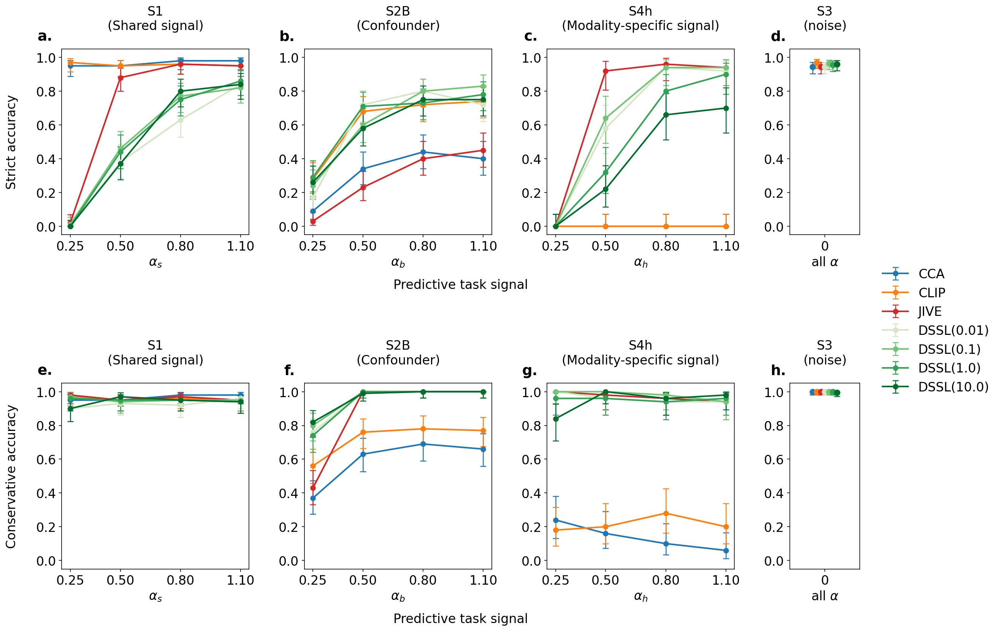

Saved fig_main_baseline_alpha_curves


In [4]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,    # base — tick labels, legend, fig.text
    'axes.titlesize':   16,    # panel titles (S1, S2B, ...)
    'axes.labelsize':   16,    # x/y axis labels
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18   # bold a. b. c. ... labels (slightly larger than base)

SCENARIO_TITLES = {
    'scenario_1': 'S1\n(Shared signal)\n',
    'scenario_2': 'S2B\n(Confounder)\n',
    'scenario_4': 'S4h\n(Modality-specific signal)\n',
}
ALPHA_XLABELS = {
    'alpha_s': '$\\alpha_s$',
    'alpha_b': '$\\alpha_b$',
    'alpha_h': '$\\alpha_h$',
}
ROW_YLABELS = {
    False: 'Strict accuracy\n',
    True:  'Conservative accuracy\n',
}

fig = plt.figure(figsize=(20, 11))
gs2 = GridSpec(2, 4, figure=fig, width_ratios=[4,4,4,1.5], hspace=0.8, wspace=0.35)
axes2 = [[fig.add_subplot(gs2[r,c]) for c in range(4)] for r in range(2)]

_rows_bac = []
for row_i, (is_conservative, row_label) in enumerate([(False, 'Strict'), (True, 'Conservative')]):
    for col_i, (gt, alpha_col, prefix, mod_filter) in enumerate(ALPHA_SCENARIOS):
        ax = axes2[row_i][col_i]
        base = df_baseline[
            df_baseline['alpha_config_id'].str.startswith(prefix) &
            (df_baseline['n_eval'] == 1000) & (df_baseline['ground_truth'] == gt)
        ]
        if mod_filter: base = base[base['modality'] == mod_filter]
        for model in MODEL_ORDER:
            sub = base[base['model_label'] == model]
            rates, ci_lo, ci_hi = [], [], []
            for a in ALPHA_VALS:
                s = sub[sub[alpha_col] == a]; n = len(s)
                if is_conservative:
                    k = int(((s['predicted_scenario']==gt)|(s['predicted_scenario']=='indeterminate')).sum())
                else:
                    k = int((s['predicted_scenario']==gt).sum())
                lo, hi = clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
                rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
                _rows_bac.append({'scenario': gt, 'alpha_col': alpha_col, 'alpha_val': a,
                                  'model': model, 'row_type': 'conservative' if is_conservative else 'strict',
                                  'rate': k/n if n>0 else float('nan'), 'ci_lower': lo, 'ci_upper': hi})
            rates = np.array(rates)
            ax.errorbar(ALPHA_VALS, rates,
                        yerr=[np.maximum(0,rates-np.array(ci_lo)), np.maximum(0,np.array(ci_hi)-rates)],
                        fmt='o-', color=COLORS[model], lw=2, markersize=6,
                        capsize=4, capthick=1.2, elinewidth=1.2, label=model)
        ax.set_xticks(ALPHA_VALS); ax.set_ylim(-0.05, 1.05)
        ax.grid(False)
        ax.set_title(SCENARIO_TITLES[gt])
        if col_i==0: ax.set_ylabel(ROW_YLABELS[is_conservative])
        ax.set_xlabel(ALPHA_XLABELS[alpha_col])

    ax = axes2[row_i][3]
    base_s3 = df_baseline[
        df_baseline['alpha_config_id'].str.startswith('s3') &
        (df_baseline['n_eval']==1000) & (df_baseline['ground_truth']=='scenario_3')
    ]
    for m_i, model in enumerate(MODEL_ORDER):
        sub = base_s3[base_s3['model_label']==model]; n = len(sub)
        if n==0: continue
        if is_conservative:
            k = int(((sub['predicted_scenario']=='scenario_3')|(sub['predicted_scenario']=='indeterminate')).sum())
        else:
            k = int((sub['predicted_scenario']=='scenario_3').sum())
        rate = k/n; lo, hi = clopper_pearson(k,n)
        x_jitter = (m_i - (len(MODEL_ORDER)-1)/2) * 0.04
        ax.errorbar(x_jitter, rate,
                    yerr=[[np.maximum(0,rate-lo)], [np.maximum(0,hi-rate)]],
                    fmt='o', color=COLORS[model], markersize=7,
                    capsize=4, capthick=1.2, elinewidth=1.2)
        _rows_bac.append({'scenario': 'scenario_3', 'alpha_col': 'none', 'alpha_val': 0.0,
                          'model': model, 'row_type': 'conservative' if is_conservative else 'strict',
                          'rate': rate, 'ci_lower': lo, 'ci_upper': hi})
    ax.set_xlim(-0.35, 0.35); ax.set_xticks([0.0]); ax.set_xticklabels(['0'])
    ax.set_ylim(-0.05, 1.05)
    ax.grid(False)
    ax.set_xlabel('all $\\alpha$')
    ax.set_title('S3\n(noise)\n')

# Panel labels — use _PANEL_LABEL_SIZE from rcParams block above
for idx, ax in enumerate([axes2[r][c] for r in range(2) for c in range(4)]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

# Layout
fig.subplots_adjust(left=0.12, right=0.82, top=0.95, bottom=0.12, hspace=0.8, wspace=0.35)

# Shared x label centred under all 4 columns — uses plt.rcParams['font.size']
x0      = axes2[0][0].get_position().x0
x1      = axes2[0][3].get_position().x1
x_center = (x0 + x1) / 2

fig.text(x_center, axes2[0][0].get_position().y0 - 0.07, 'Predictive task signal',
         ha='center', va='top')
fig.text(x_center, axes2[1][0].get_position().y0 - 0.07, 'Predictive task signal',
         ha='center', va='top')

# Legend on far right, vertically centred
handles, labels = axes2[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', ncol=1,
           bbox_to_anchor=(0.83, 0.5), frameon=False)

plt.show()
save_fig(fig, 'fig_main_baseline_alpha_curves', pd.DataFrame(_rows_bac))


## Fig 3 — FSCR by model

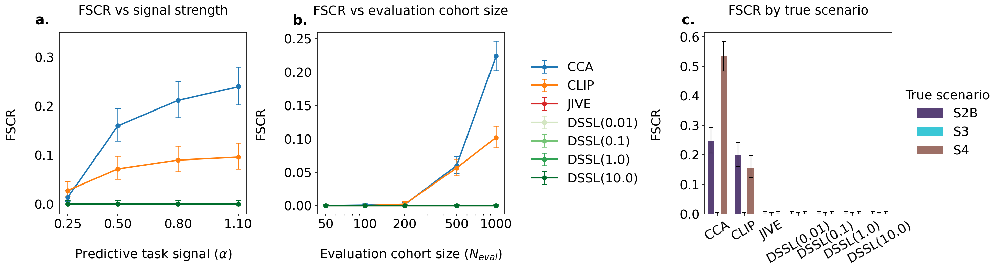

Saved fig_fscr_by_model


In [5]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        18,
    'axes.titlesize':   18,
    'axes.labelsize':   18,
    'xtick.labelsize':  18,
    'ytick.labelsize':  18,
    'legend.fontsize':  18,
})
_PANEL_LABEL_SIZE = 20

# SC_COLORS defined in Cell 2 (utilities)

df_fscr_base = df_pure[
    (df_pure['measurement_regime'] == 'baseline') &
    (~df_pure['is_proxy_run']) &
    (df_pure['ground_truth'] != 'scenario_1')
]

# 4-column GridSpec: [panel a | panel b | legend | panel c]
fig = plt.figure(figsize=(20, 5.5))
gs3 = GridSpec(1, 4, figure=fig, width_ratios=[4, 4, 3, 4], wspace=0.4)
ax_a   = fig.add_subplot(gs3[0, 0])
ax_b   = fig.add_subplot(gs3[0, 1])
ax_leg = fig.add_subplot(gs3[0, 2])
ax_c   = fig.add_subplot(gs3[0, 3])
ax_leg.axis('off')

_rows_fscr = []

# Panel a — FSCR vs alpha
for model in MODEL_ORDER:
    rates, ci_lo, ci_hi = [], [], []
    for a in [0.25, 0.5, 0.8, 1.1]:
        sub = pd.concat([
            df_fscr_base[(df_fscr_base['model_label']==model) & (df_fscr_base['n_eval']==1000) &
                          df_fscr_base['alpha_config_id'].str.startswith('s2b') & (df_fscr_base['alpha_b']==a)],
            df_fscr_base[(df_fscr_base['model_label']==model) & (df_fscr_base['n_eval']==1000) &
                          df_fscr_base['alpha_config_id'].str.startswith('s3')],
            df_fscr_base[(df_fscr_base['model_label']==model) & (df_fscr_base['n_eval']==1000) &
                          df_fscr_base['alpha_config_id'].str.startswith('s4h') & (df_fscr_base['alpha_h']==a)],
            df_fscr_base[(df_fscr_base['model_label']==model) & (df_fscr_base['n_eval']==1000) &
                          df_fscr_base['alpha_config_id'].str.startswith('s4r') & (df_fscr_base['alpha_r']==a)],
        ])
        n = len(sub); k = int((sub['predicted_scenario']=='scenario_1').sum())
        lo, hi = clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
        rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
        _rows_fscr.append({'panel':'alpha','model':model,'alpha_val':a,'n_eval':1000,
                           'scenario':'pooled','fscr':k/n if n>0 else float('nan'),
                           'ci_lower':lo,'ci_upper':hi})
    rates = np.array(rates)
    ax_a.errorbar([0.25,0.5,0.8,1.1], rates,
                  yerr=[np.maximum(0,rates-np.array(ci_lo)), np.maximum(0,np.array(ci_hi)-rates)],
                  fmt='o-', color=COLORS[model], lw=2, markersize=6,
                  capsize=4, capthick=1.2, elinewidth=1.2, label=model)
ax_a.set_xticks([0.25,0.5,0.8,1.1])
ax_a.set_xlabel('\nPredictive task signal ($\\alpha$)')
ax_a.set_ylabel('FSCR\n')
ax_a.set_ylim(-0.02, 0.35)
ax_a.set_title('FSCR vs signal strength\n')
ax_a.grid(False)

# Panel b — FSCR vs N_eval
for model in MODEL_ORDER:
    rates, ci_lo, ci_hi = [], [], []
    for ne in [50, 100, 200, 500, 1000]:
        sub = df_fscr_base[(df_fscr_base['model_label']==model) & (df_fscr_base['n_eval']==ne)]
        n = len(sub); k = int((sub['predicted_scenario']=='scenario_1').sum())
        lo, hi = clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
        rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
        _rows_fscr.append({'panel':'n_eval','model':model,'alpha_val':float('nan'),'n_eval':ne,
                           'scenario':'pooled','fscr':k/n if n>0 else float('nan'),
                           'ci_lower':lo,'ci_upper':hi})
    _r = np.array(rates)
    ax_b.errorbar([50,100,200,500,1000], rates,
                  yerr=[np.maximum(0,_r-np.array(ci_lo)), np.maximum(0,np.array(ci_hi)-_r)],
                  fmt='o-', color=COLORS[model], lw=2, markersize=6,
                  capsize=4, capthick=1.2, elinewidth=1.2, label=model)
ax_b.set_xscale('log'); ax_b.set_xticks([50, 100, 200, 500, 1000]); ax_b.set_xticklabels([50, 100, 200, 500, 1000])
ax_b.set_xlabel('\nEvaluation cohort size ($N_{eval}$)')
ax_b.set_ylabel('FSCR\n')
ax_b.set_title('FSCR vs evaluation cohort size\n')
ax_b.grid(False)

# Model legend in the legend column
handles, labels = ax_a.get_legend_handles_labels()
ax_leg.legend(handles, labels, loc='center', frameon=False, ncol=1)

# Panel c — FSCR by true scenario
GT_ORDER_FSCR  = ['scenario_2', 'scenario_3', 'scenario_4']
GT_LABELS_FSCR = {'scenario_2': 'S2B', 'scenario_3': 'S3', 'scenario_4': 'S4'}
n_m = len(MODEL_ORDER); n_g = len(GT_ORDER_FSCR); bw = 0.25; gg = 0.30
xtick_pos, xtick_labels = [], []
for m_i, model in enumerate(MODEL_ORDER):
    gc = m_i * (n_g * bw + gg)
    for g_i, gt in enumerate(GT_ORDER_FSCR):
        sub = df_fscr_base[(df_fscr_base['model_label']==model) &
                           (df_fscr_base['n_eval']==1000) &
                           (df_fscr_base['ground_truth']==gt)]
        n = len(sub); k = int((sub['predicted_scenario']=='scenario_1').sum())
        rate = k/n if n>0 else float('nan')
        lo, hi = clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
        x = gc + g_i * bw
        ax_c.bar(x, rate, bw, color=SC_COLORS[gt], alpha=0.85,
                 label=GT_LABELS_FSCR[gt] if m_i==0 else '')
        ax_c.errorbar(x, rate, yerr=[[np.maximum(0,rate-lo)],[np.maximum(0,hi-rate)]],
                      fmt='none', color='black', capsize=3, lw=1)
        _rows_fscr.append({'panel':'by_scenario','model':model,'alpha_val':float('nan'),'n_eval':1000,
                           'scenario':gt,'fscr':rate,'ci_lower':lo,'ci_upper':hi})
    xtick_pos.append(gc + (n_g-1)*bw/2); xtick_labels.append(model)
ax_c.set_xlim(-bw, (n_m-1)*(n_g*bw+gg)+n_g*bw)
ax_c.set_xticks(xtick_pos)
ax_c.set_xticklabels(xtick_labels, rotation=30, ha='center')
ax_c.set_ylabel('FSCR\n')
ax_c.set_title('FSCR by true scenario\n')
ax_c.legend(title='True scenario', loc='center left',
             bbox_to_anchor=(1.01, 0.5), frameon=False)
ax_c.grid(False)

# Panel labels
for idx, ax in enumerate([ax_a, ax_b, ax_c]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

fig.subplots_adjust(left=0.07, right=0.97, top=0.90, bottom=0.25)

# Shift panel c left without moving a/b/legend
pos_c = ax_c.get_position()
ax_c.set_position([pos_c.x0 - 0.08, pos_c.y0, pos_c.width, pos_c.height])
pos_b   = ax_b.get_position()
pos_leg = ax_leg.get_position()
ax_leg.set_position([pos_b.x1 + 0.01, pos_leg.y0, pos_leg.width, pos_leg.height])


plt.show()
save_fig(fig, 'fig_fscr_by_model', pd.DataFrame(_rows_fscr))


## Fig 22 — Proxy summary 2x3

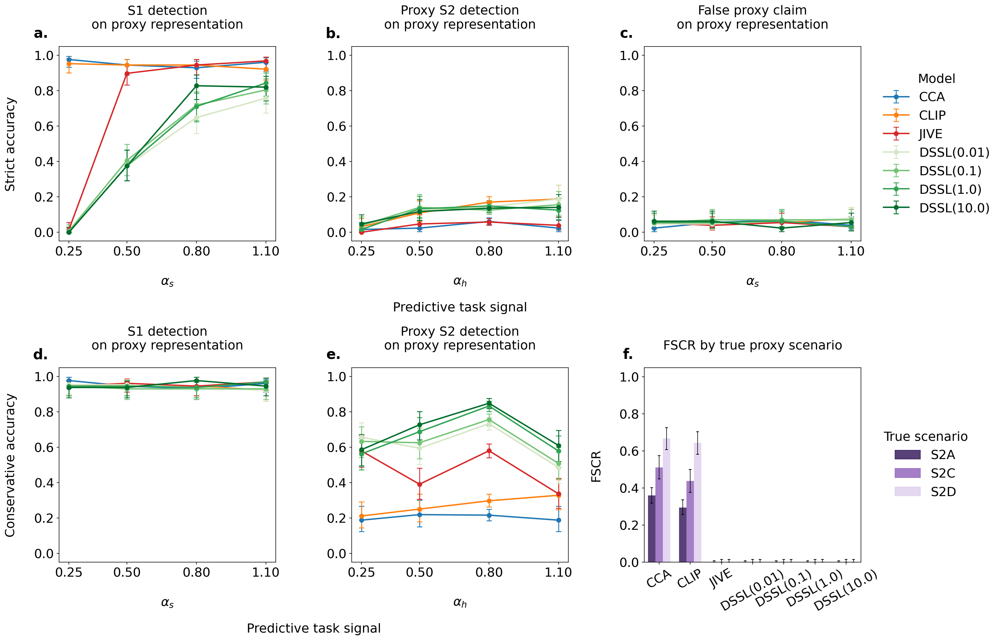

Saved fig_proxy_summary_2x3


In [6]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        18,
    'axes.titlesize':   18,
    'axes.labelsize':   18,
    'xtick.labelsize':  18,
    'ytick.labelsize':  18,
    'legend.fontsize':  18,
})
_PANEL_LABEL_SIZE = 20

# Update SCEN_TYPES_FSCR to use SC_COLORS
SCEN_TYPES_FSCR = [
    ('S2A', 's2a', SC_COLORS['scenario_2a']),
    ('S2C', 's2c', SC_COLORS['scenario_2c']),
    ('S2D', 's2d', SC_COLORS['scenario_2d']),
]

df_pbase = df[
    (df['is_proxy_run']) &
    (df['measurement_regime'] == 'baseline') &
    (df['n_eval'] == 1000)
]

COLS_PROXY = [
    ('S1 detection\non proxy representation',       'alpha_s', 's1',  'scenario_1'),
    ('Proxy S2 detection\non proxy representation',  'alpha_h', 's2',  'scenario_2'),
    ('False proxy claim\non proxy representation',   'alpha_s', 's1',  'scenario_2'),
]
ALPHA_VALS_PROXY = [0.25, 0.5, 0.8, 1.1]

ROW_YLABELS_4 = {
    0: 'Strict accuracy\n',
    1: 'Conservative accuracy\n',
}

fig, axes = plt.subplots(2, 3, figsize=(22, 12))

_rows_ps = []

# Top row + bottom-left two: alpha line plots
for col_i, (col_title, alpha_col, prefix, detect_gt) in enumerate(COLS_PROXY):
    base = df_pbase[df_pbase['alpha_config_id'].str.startswith(prefix)]
    for row_i in range(2):
        if row_i == 1 and col_i == 2:
            continue
        ax = axes[row_i, col_i]
        row_type = 'strict' if row_i == 0 else 'conservative'
        for model in MODEL_ORDER:
            sub_m = base[base['model_label'] == model]
            rates, ci_lo, ci_hi = [], [], []
            for a in ALPHA_VALS_PROXY:
                s = sub_m[sub_m[alpha_col] == a]; n = len(s)
                if row_i == 0:
                    k = int((s['predicted_scenario'] == detect_gt).sum())
                elif col_i < 2:
                    k = int(((s['predicted_scenario']==detect_gt)|
                              (s['predicted_scenario']=='indeterminate')).sum())
                else:
                    resolved = s[s['predicted_scenario'] != 'indeterminate']
                    n = len(resolved)
                    k = int((resolved['predicted_scenario'] == detect_gt).sum())
                lo, hi = clopper_pearson(k, n) if n>0 else (float('nan'), float('nan'))
                rates.append(k/n if n>0 else float('nan'))
                ci_lo.append(lo); ci_hi.append(hi)
                _rows_ps.append({'col_title': col_title, 'alpha_col': alpha_col, 'alpha_val': a,
                                 'detect_gt': detect_gt, 'model': model, 'row_type': row_type,
                                 'rate': k/n if n>0 else float('nan'), 'ci_lower': lo, 'ci_upper': hi})
            rates = np.array(rates)
            ax.errorbar(ALPHA_VALS_PROXY, rates,
                        yerr=[np.maximum(0,rates-np.array(ci_lo)),
                              np.maximum(0,np.array(ci_hi)-rates)],
                        fmt='o-', color=COLORS[model], lw=2, markersize=6,
                        capsize=4, capthick=1.2, elinewidth=1.2, label=model)
        ax.set_xticks(ALPHA_VALS_PROXY); ax.set_ylim(-0.05, 1.05)
        ax.grid(False)
        ax.set_title(col_title + '\n')
        if col_i == 0: ax.set_ylabel(ROW_YLABELS_4[row_i])
        ax.set_xlabel(f'\n$\\alpha_{{{alpha_col.split("_")[1]}}}$')

# Bottom-right: FSCR by true proxy scenario
ax_br = axes[1, 2]
n_m = len(MODEL_ORDER); n_s = len(SCEN_TYPES_FSCR)
bw = 0.25; gg = 0.30
xtick_pos_br, xtick_labels_br = [], []
for m_i, model in enumerate(MODEL_ORDER):
    gc = m_i * (n_s * bw + gg)
    for s_i, (slabel, sprefix, scol) in enumerate(SCEN_TYPES_FSCR):
        sub = df_pbase[df_pbase['alpha_config_id'].str.startswith(sprefix) &
                       (df_pbase['model_label'] == model)]
        n = len(sub); k = int((sub['predicted_scenario'] == 'scenario_1').sum())
        rate = k/n if n>0 else float('nan')
        lo, hi = clopper_pearson(k, n) if n>0 else (float('nan'), float('nan'))
        x = gc + s_i * bw
        ax_br.bar(x, rate, bw, color=scol, alpha=0.85, label=slabel if m_i==0 else '')
        ax_br.errorbar(x, rate, yerr=[[np.maximum(0,rate-lo)],[np.maximum(0,hi-rate)]],
                       fmt='none', color='black', capsize=2, lw=0.8)
        _rows_ps.append({'col_title': 'FSCR_by_scenario', 'alpha_col': 'none', 'alpha_val': float('nan'),
                         'detect_gt': 'scenario_1', 'model': model, 'row_type': slabel,
                         'rate': rate, 'ci_lower': lo, 'ci_upper': hi})
    xtick_pos_br.append(gc + (n_s-1)*bw/2); xtick_labels_br.append(model)
ax_br.set_xlim(-bw, (n_m-1)*(n_s*bw+gg)+n_s*bw)
ax_br.set_xticks(xtick_pos_br)
ax_br.set_xticklabels(xtick_labels_br, rotation=30, ha='center')
ax_br.set_ylabel('FSCR\n')
ax_br.set_title('FSCR by true proxy scenario\n')
ax_br.set_ylim(0, 1.05)
ax_br.grid(False)

# Panel labels
for idx, ax in enumerate([axes[r][c] for r in range(2) for c in range(3)]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

fig.subplots_adjust(left=0.10, right=0.82, top=0.95, bottom=0.10, hspace=0.65, wspace=0.35)

# "Predictive task signal" shared x labels
# Under top row (panels a, b, c)
x0_top = axes[0][0].get_position().x0
x1_top = axes[0][2].get_position().x1
y_top  = axes[0][0].get_position().y0 - 0.10
fig.text((x0_top + x1_top) / 2, y_top, 'Predictive task signal',
         ha='center', va='top', fontsize=18)

# Under bottom row panels d/e only (cols 0-1)
x0_bot = axes[1][0].get_position().x0
x1_bot = axes[1][1].get_position().x1
y_bot  = axes[1][0].get_position().y0 - 0.10
fig.text((x0_bot + x1_bot) / 2, y_bot, 'Predictive task signal',
         ha='center', va='top', fontsize=18)

# Compute row vertical centres after subplots_adjust
y_row0_mid = (axes[0][0].get_position().y0 + axes[0][0].get_position().y1) / 2
y_row1_mid = (axes[1][0].get_position().y0 + axes[1][0].get_position().y1) / 2

# Model legend — centred with top row
model_handles, model_labels = axes[0][0].get_legend_handles_labels()
fig.legend(model_handles, model_labels,
           loc='center left', bbox_to_anchor=(0.83, y_row0_mid),
           frameon=False, ncol=1, title='Model')

# True scenario legend — centred with bottom row
scen_handles = [plt.Rectangle((0,0),1,1, color=scol, alpha=0.85)
                for _, _, scol in SCEN_TYPES_FSCR]
scen_labels  = [slabel for slabel, _, _ in SCEN_TYPES_FSCR]
fig.legend(scen_handles, scen_labels,
           loc='center left', bbox_to_anchor=(0.83, y_row1_mid),
           frameon=False, ncol=1, title='True scenario')

plt.show()
save_fig(fig, 'fig_proxy_summary_2x3', pd.DataFrame(_rows_ps))

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 14,
    'axes.titlesize': 14, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14,
    'legend.fontsize': 14,
})

## Fig 7 — β sweep geometry

Sweep: beta_s
Sweep: beta_b
Sweep: beta_h
Sweep: beta_r


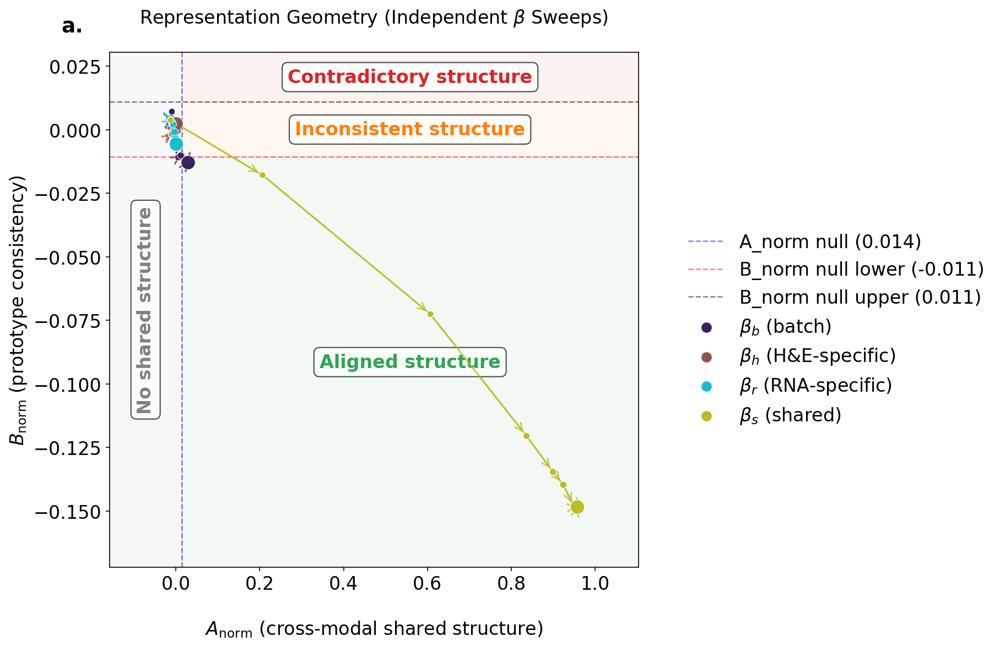

Saved fig_geometry_independent_sweeps


In [7]:
# This cell runs the independent beta sweeps (takes ~5-10 min first run)


_SEED02 = 42; _K02 = 50; _DH02 = _DR02 = 1024
_NA02 = 2500; _NAP02 = 500; _NB02 = _NC02 = 500; _NP02 = 200


def _bnorm_repeats(zh, zr, zh_a, k=2, n=5):
    vals = [compute_bnorm_null(zh, zr, compute_prototypes(zh_a, k=k, rng=np.random.default_rng(_SEED02+100+i)),
                  n_permutations=_NP02, rng=np.random.default_rng(_SEED02+200+i))['bnorm']
            for i in range(n)]
    return {'bnorm_mean': float(np.mean(vals)), 'bnorm_std': float(np.std(vals))}


def _run_indep_sweep(beta_name, beta_values):
    rows = []
    for val in beta_values:
        params = dict(beta_s=0.0, beta_h=0.0, beta_r=0.0, beta_b=0.0,
                      sigma_h=np.sqrt(0.75), sigma_r=np.sqrt(0.75))
        params[beta_name] = val
        cfg = SimulatorConfig(latent_dim=_K02, d_h=_DH02, d_r=_DR02,
                    n_a=_NA02, n_a_prime=_NAP02, n_b=_NB02, n_c=_NC02, seed=_SEED02, **params)
        data = simulate_run(cfg); mm = data['measurement_model']
        mask_ap = data['cohort'] == 'A_prime'
        zh = data['xh'][mask_ap] @ mm.A_s; zr = data['xr'][mask_ap] @ mm.B_s
        mask_a = data['cohort'] == 'A'; zh_a = data['xh'][mask_a] @ mm.A_s
        protos = compute_prototypes(zh_a, k=2, rng=np.random.default_rng(_SEED02))
        ar = compute_anorm_null(zh, zr, n_permutations=_NP02, rng=np.random.default_rng(_SEED02))
        br = compute_bnorm_null(zh, zr, protos, n_permutations=_NP02, rng=np.random.default_rng(_SEED02+1))
        bs = _bnorm_repeats(zh, zr, zh_a)
        rows.append({'beta_name': beta_name, 'beta_value': val,
                     'A_norm': ar['anorm'], 'B_norm': br['bnorm'],
                     'B_norm_mean': bs['bnorm_mean'], 'B_norm_std': bs['bnorm_std'],
                     'A_null_upper': ar['null_upper'], 'B_null_lower': br['null_lower'],
                     'B_null_upper': br['null_upper']})
    return pd.DataFrame(rows)


beta_vals_indep = np.array([0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 2, 4, 8, 16])
dfs_indep = []
for _b in ['beta_s', 'beta_b', 'beta_h', 'beta_r']:
    print(f'Sweep: {_b}')
    dfs_indep.append(_run_indep_sweep(_b, beta_vals_indep))
df_indep = pd.concat(dfs_indep, ignore_index=True)

A_thresh_indep = df_indep['A_null_upper'].max()
B_thresh_indep = df_indep['B_null_lower'].min()
B_thresh_upper_indep = df_indep['B_null_upper'].max()

NB02_COLORS = {'beta_s':'#bcbd22','beta_h':'#8c564b','beta_r':"#17becf",'beta_b':'#3b1f5e'}
NB02_STYLES = {'beta_s':'-','beta_h':'--','beta_r':':','beta_b':'-.'}
NB02_LABELS = {
    'beta_s': r'$\beta_s$ (shared)', 'beta_h': r'$\beta_h$ (H&E-specific)',
    'beta_r': r'$\beta_r$ (RNA-specific)', 'beta_b': r'$\beta_b$ (batch)',
}

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

# Fig 7: geometry
fig, ax = plt.subplots(figsize=(10, 8))
a_min, a_max = df_indep['A_norm'].min(), df_indep['A_norm'].max()
b_min, b_max = df_indep['B_norm'].min(), df_indep['B_norm'].max()
a_pad = (a_max-a_min)*0.15; b_pad = (b_max-b_min)*0.15
xlim = (a_min-a_pad, a_max+a_pad); ylim = (b_min-b_pad, b_max+b_pad)

ax.axvspan(xlim[0], A_thresh_indep, alpha=0.06, color='gray')
ax.text((xlim[0]+A_thresh_indep)/2,(ylim[0]+ylim[1])/2,'No shared structure',
        color='gray',fontweight='bold',ha='center',va='center',rotation=90,
        bbox=dict(boxstyle='round,pad=0.3',facecolor='white',alpha=0.7))
ax.add_patch(mpatches.Rectangle((A_thresh_indep,ylim[0]),xlim[1]-A_thresh_indep,B_thresh_indep-ylim[0],alpha=0.06,color='#31a354',zorder=0))
ax.text((A_thresh_indep+xlim[1])/2,(ylim[0]+B_thresh_indep)/2,'Aligned structure',
        color='#31a354',fontweight='bold',ha='center',va='center',
        bbox=dict(boxstyle='round,pad=0.3',facecolor='white',alpha=0.7))
ax.add_patch(mpatches.Rectangle((A_thresh_indep,B_thresh_indep),xlim[1]-A_thresh_indep,B_thresh_upper_indep-B_thresh_indep,alpha=0.06,color='#ff7f0e',zorder=0))
ax.text((A_thresh_indep+xlim[1])/2,(B_thresh_indep+B_thresh_upper_indep)/2,'Inconsistent structure',
        color='#ff7f0e',fontweight='bold',ha='center',va='center',
        bbox=dict(boxstyle='round,pad=0.3',facecolor='white',alpha=0.7))
ax.add_patch(mpatches.Rectangle((A_thresh_indep,B_thresh_upper_indep),xlim[1]-A_thresh_indep,ylim[1]-B_thresh_upper_indep,alpha=0.06,color='#d62728',zorder=0))
ax.text((A_thresh_indep+xlim[1])/2,(B_thresh_upper_indep+ylim[1])/2,'Contradictory structure',
        color='#d62728',fontweight='bold',ha='center',va='center',
        bbox=dict(boxstyle='round,pad=0.3',facecolor='white',alpha=0.7))

ax.axvline(A_thresh_indep,linestyle='--',color='blue',alpha=0.5,linewidth=1.2,label=f'A_norm null ({A_thresh_indep:.3f})')
ax.axhline(B_thresh_indep,linestyle='--',color='red',alpha=0.5,linewidth=1.2,label=f'B_norm null lower ({B_thresh_indep:.3f})')
ax.axhline(B_thresh_upper_indep,linestyle='--',color='black',alpha=0.5,linewidth=1.2,label=f'B_norm null upper ({B_thresh_upper_indep:.3f})')

_bmin, _bmax = beta_vals_indep.min(), beta_vals_indep.max()
for beta_name, group in df_indep.groupby('beta_name'):
    group = group.sort_values('beta_value')
    sizes = 30 + 120*(group['beta_value'].values-_bmin)/(_bmax-_bmin)
    ax.plot(group['A_norm'],group['B_norm'],linestyle=NB02_STYLES[beta_name],
            color=NB02_COLORS[beta_name],linewidth=1.5,alpha=0.7)
    ax.scatter(group['A_norm'],group['B_norm'],s=sizes,color=NB02_COLORS[beta_name],
               edgecolors='white',linewidths=0.5,zorder=5,label=NB02_LABELS[beta_name])
    for i in range(len(group)-1):
        x0,y0=group.iloc[i][['A_norm','B_norm']]
        x1,y1=group.iloc[i+1][['A_norm','B_norm']]
        if abs(x1-x0)>1e-6 or abs(y1-y0)>1e-6:
            ax.annotate('',xy=(x1,y1),xytext=(x0,y0),
                        arrowprops=dict(arrowstyle='->',color=NB02_COLORS[beta_name],lw=1.5,alpha=0.7,shrinkA=4,shrinkB=4))
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_xlabel('\n' + r'$A_{\mathrm{norm}}$ (cross-modal shared structure)')
ax.set_ylabel(r'$B_{\mathrm{norm}}$ (prototype consistency)')
ax.set_title(r'Representation Geometry (Independent $\beta$ Sweeps)' + '\n')
ax.grid(False)
fig.legend(loc='center left', bbox_to_anchor=(0.80, 0.5), frameon=False)
ax.text(-0.05, 1.03, 'a.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)
fig.subplots_adjust(left=0.12, right=0.76, top=0.92, bottom=0.14)
plt.show()
save_fig(fig, 'fig_geometry_independent_sweeps', df_indep)

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 8 — β sensitivity

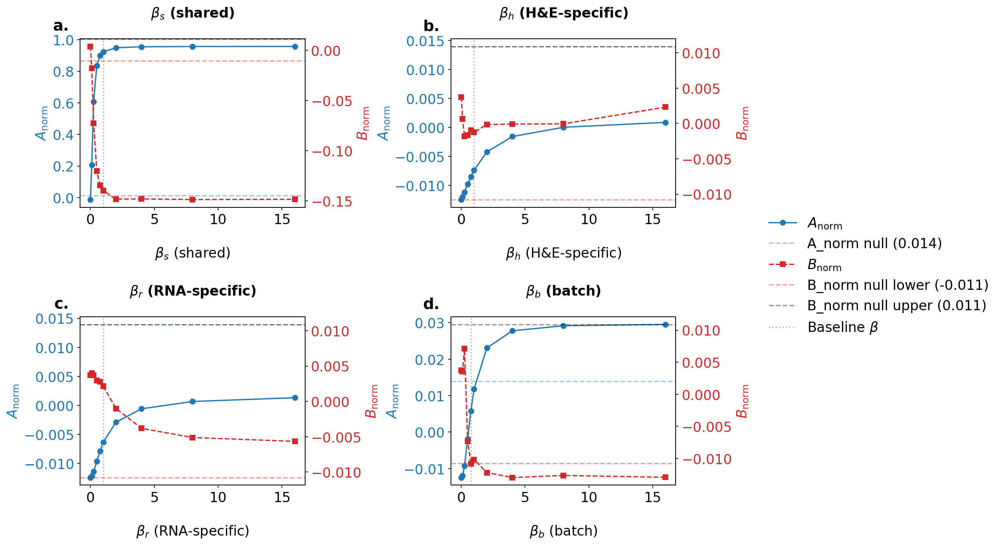

Saved fig_sensitivity_independent


In [8]:
plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()
_panel_labels = ['a.', 'b.', 'c.', 'd.']
_ax2s = []

_rows_sens = []
for idx, beta_name in enumerate(['beta_s', 'beta_h', 'beta_r', 'beta_b']):
    ax1 = axes[idx]
    group = df_indep[df_indep['beta_name'] == beta_name].sort_values('beta_value')
    color_a = '#1f77b4'
    ax1.plot(group['beta_value'], group['A_norm'], 'o-', color=color_a,
             label=r'$A_{\mathrm{norm}}$')
    ax1.set_xlabel('\n' + NB02_LABELS[beta_name])
    ax1.set_ylabel(r'$A_{\mathrm{norm}}$', color=color_a)
    ax1.tick_params(axis='y', labelcolor=color_a)
    ax1.axhline(A_thresh_indep, linestyle='--', color=color_a, alpha=0.4,
                label=f'A_norm null ({A_thresh_indep:.3f})')
    ax2 = ax1.twinx()
    _ax2s.append(ax2)
    color_b = '#d62728'
    ax2.plot(group['beta_value'], group['B_norm'], 's--', color=color_b,
             label=r'$B_{\mathrm{norm}}$')
    ax2.set_ylabel(r'$B_{\mathrm{norm}}$', color=color_b)
    ax2.tick_params(axis='y', labelcolor=color_b)
    ax2.axhline(B_thresh_indep, linestyle='--', color='red', alpha=0.4,
                label=f'B_norm null lower ({B_thresh_indep:.3f})')
    ax2.axhline(B_thresh_upper_indep, linestyle='--', color='black', alpha=0.4,
                label=f'B_norm null upper ({B_thresh_upper_indep:.3f})')
    _bv = 0.75 if beta_name == 'beta_b' else 1.0
    ax1.axvline(_bv, color='gray', linestyle=':', alpha=0.6,
                label=f'baseline (beta={_bv})')
    ax1.set_title(NB02_LABELS[beta_name] + '\n', fontweight='bold')
    ax1.grid(False)
    ax2.grid(False)
    ax1.text(-0.05, 1.03, _panel_labels[idx], fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
             va='bottom', ha='right', clip_on=False, transform=ax1.transAxes)
    for _, row in group.iterrows():
        _rows_sens.append({'beta_name': beta_name, 'beta_value': row['beta_value'],
                           'A_norm': row['A_norm'], 'B_norm': row['B_norm'],
                           'A_null_upper': row['A_null_upper'],
                           'B_null_lower': row['B_null_lower'],
                           'B_null_upper': row['B_null_upper']})

# Shared legend — all series + one universal baseline entry
_sh = []; _sl = []
for _a in list(axes) + _ax2s:
    for h, l in zip(*_a.get_legend_handles_labels()):
        if 'baseline' not in l and l not in _sl:
            _sh.append(h); _sl.append(l)
# Add single universal baseline handle
for _a in list(axes):
    for h, l in zip(*_a.get_legend_handles_labels()):
        if 'baseline' in l:
            _sh.append(h); _sl.append(r'Baseline $\beta$')
            break
    else:
        continue
    break
fig.legend(_sh, _sl, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
fig.subplots_adjust(left=0.09, right=0.9, top=0.93, bottom=0.12, hspace=0.65, wspace=0.65)
plt.show()
save_fig(fig, 'fig_sensitivity_independent', pd.DataFrame(_rows_sens))

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 9 — Delta_shared alpha sweep

alpha_s=0.00  delta=-0.2792
alpha_s=0.10  delta=-0.2851
alpha_s=0.20  delta=-0.2156
alpha_s=0.30  delta=-0.1761
alpha_s=0.40  delta=-0.0914
alpha_s=0.50  delta=+0.0074
alpha_s=0.60  delta=+0.0766
alpha_s=0.70  delta=+0.1784
alpha_s=0.80  delta=+0.2249
alpha_s=0.90  delta=+0.2669
alpha_s=1.00  delta=+0.2878


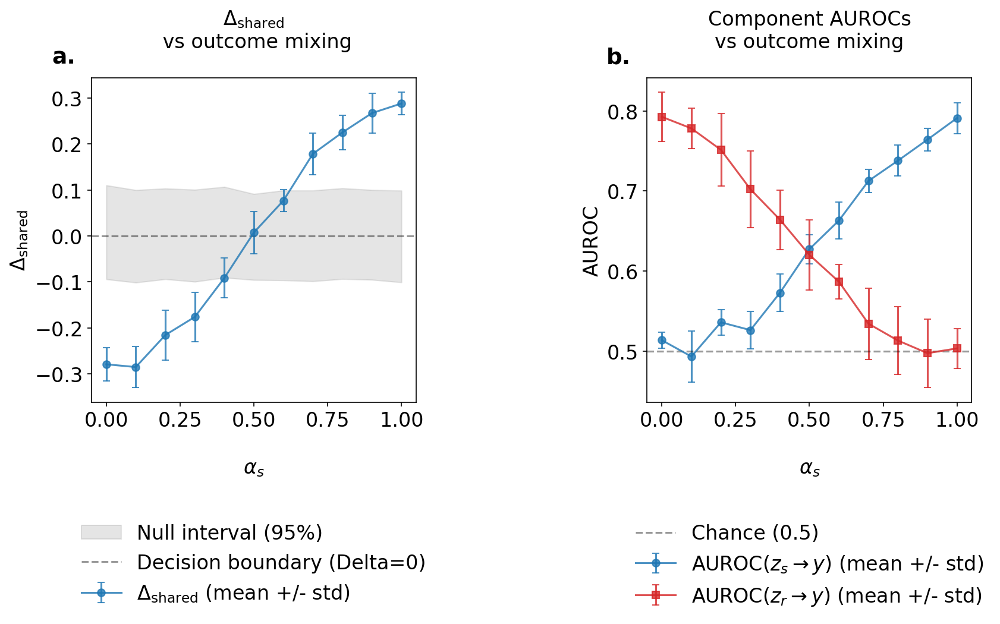

Saved fig_alpha_sweep_delta_shared


In [9]:
# NOTE: This cell runs the sweep (takes a few minutes)

_SEEDS04 = [42, 43, 44, 45, 46]
_K04 = 50; _DH04 = _DR04 = 1024
_NA04 = 2500; _NAP04 = 500; _NB04 = _NC04 = 500
_ALPHA_VALUES04 = np.linspace(0, 1, 11)

_alpha_records = []
for _alpha_s in _ALPHA_VALUES04:
    _alpha_r = 1.0 - _alpha_s
    _alpha_key = int(round(_alpha_s * 1000))
    _seed_deltas, _seed_ash, _seed_asr = [], [], []
    _splits = None
    for _seed in _SEEDS04:
        _cfg = SimulatorConfig(latent_dim=_K04, d_h=_DH04, d_r=_DR04,
                     n_a=_NA04, n_a_prime=_NAP04, n_b=_NB04, n_c=_NC04,
                     alpha_s=float(_alpha_s), alpha_r=float(_alpha_r),
                     alpha_h=0.0, alpha_b=0.0,
                     beta_s=1.0, beta_r=1.0, beta_h=0.0, beta_b=0.0,
                     eta=0.0, sigma_y=1.0, seed=_seed)
        _data = simulate_run(_cfg)
        _mask = _data['cohort'] == 'A_prime'
        _Zs = _data['z_s'][_mask]; _Zr = _data['z_r'][_mask]; _y = _data['y'][_mask]
        if _splits is None:
            _splits = make_cv_splits(len(_y), _y, n_folds=5, rng=np.random.default_rng(123+_alpha_key))
        _res = compute_delta_shared(_Zs, _Zr, _y, n_folds=5, n_permutations=0,
                    rng=np.random.default_rng(_seed+_alpha_key), splits=_splits)
        _seed_deltas.append(_res['delta_shared'])
        _seed_ash.append(_res['auroc_shared'])
        _seed_asr.append(_res['auroc_specific'])
    _null_lo, _null_hi = [], []
    for _seed in _SEEDS04:
        _cfg = SimulatorConfig(latent_dim=_K04, d_h=_DH04, d_r=_DR04,
                     n_a=_NA04, n_a_prime=_NAP04, n_b=_NB04, n_c=_NC04,
                     alpha_s=float(_alpha_s), alpha_r=float(_alpha_r),
                     alpha_h=0.0, alpha_b=0.0,
                     beta_s=1.0, beta_r=1.0, beta_h=0.0, beta_b=0.0,
                     eta=0.0, sigma_y=1.0, seed=_seed)
        _data = simulate_run(_cfg)
        _mask = _data['cohort'] == 'A_prime'
        _Zs = _data['z_s'][_mask]; _Zr = _data['z_r'][_mask]; _y = _data['y'][_mask]
        _ns = compute_delta_shared_null(_Zs, _Zr, _y, n_folds=5, n_permutations=200,
                     rng=np.random.default_rng(999+_seed+_alpha_key), splits=_splits)
        _null_lo.append(_ns['null_lower']); _null_hi.append(_ns['null_upper'])
    _alpha_records.append({
        'alpha_s': float(_alpha_s),
        'delta_mean': float(np.mean(_seed_deltas)), 'delta_std': float(np.std(_seed_deltas)),
        'auroc_shared_mean': float(np.mean(_seed_ash)), 'auroc_shared_std': float(np.std(_seed_ash)),
        'auroc_specific_mean': float(np.mean(_seed_asr)), 'auroc_specific_std': float(np.std(_seed_asr)),
        'null_lower': float(np.mean(_null_lo)), 'null_upper': float(np.mean(_null_hi)),
    })
    print(f'alpha_s={_alpha_s:.2f}  delta={_alpha_records[-1]["delta_mean"]:+.4f}')

df_alpha04 = pd.DataFrame(_alpha_records)

# Plot (nb04 cell 4)
plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

fig, (ax_delta, ax_auroc) = plt.subplots(1, 2, figsize=(12, 7))
ax_delta.fill_between(df_alpha04['alpha_s'], df_alpha04['null_lower'], df_alpha04['null_upper'],
                       color='gray', alpha=0.2, label='Null interval (95%)')
ax_delta.errorbar(df_alpha04['alpha_s'], df_alpha04['delta_mean'], yerr=df_alpha04['delta_std'],
                   fmt='o-', color='#1f77b4', linewidth=1.5, alpha=0.8, capsize=3,
                   label=r'$\Delta_{\mathrm{shared}}$ (mean +/- std)')
ax_delta.axhline(0, linestyle='--', color='black', alpha=0.4, label='Decision boundary (Delta=0)')
ax_delta.set_xlabel('\n' + r'$\alpha_s$')
ax_delta.set_ylabel(r'$\Delta_{\mathrm{shared}}$')
ax_delta.set_title(r'$\Delta_{\mathrm{shared}}$' + '\n vs outcome mixing\n')
ax_delta.grid(False)
ax_delta.set_box_aspect(1)
ax_delta.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=1, frameon=False)
ax_delta.text(-0.05, 1.03, 'a.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
              va='bottom', ha='right', clip_on=False, transform=ax_delta.transAxes)

ax_auroc.errorbar(df_alpha04['alpha_s'], df_alpha04['auroc_shared_mean'],
                   yerr=df_alpha04['auroc_shared_std'],
                   fmt='o-', color='#1f77b4', linewidth=1.5, alpha=0.8, capsize=3,
                   label=r'AUROC($z_s \to y$) (mean +/- std)')
ax_auroc.errorbar(df_alpha04['alpha_s'], df_alpha04['auroc_specific_mean'],
                   yerr=df_alpha04['auroc_specific_std'],
                   fmt='s-', color='#d62728', linewidth=1.5, alpha=0.8, capsize=3,
                   label=r'AUROC($z_r \to y$) (mean +/- std)')
ax_auroc.axhline(0.5, linestyle='--', color='black', alpha=0.4, label='Chance (0.5)')
ax_auroc.set_xlabel('\n' + r'$\alpha_s$')
ax_auroc.set_ylabel('AUROC')
ax_auroc.set_title('Component AUROCs\nvs outcome mixing\n')
ax_auroc.grid(False)
ax_auroc.set_box_aspect(1)
ax_auroc.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=1, frameon=False)
ax_auroc.text(-0.05, 1.03, 'b.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
              va='bottom', ha='right', clip_on=False, transform=ax_auroc.transAxes)

fig.subplots_adjust(left=0.08, right=0.97, top=0.88, bottom=0.36, wspace=0.4)
plt.show()
save_fig(fig, 'fig_alpha_sweep_delta_shared', df_alpha04)

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 10 — D_quantile trajectories (GT latents)

Loaded D_quantile sweep CSVs


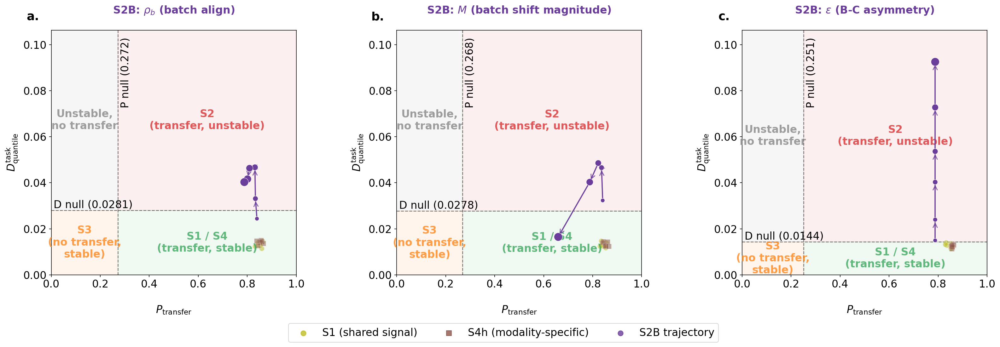

Saved fig_dquantile_vs_ptransfer_trajectories


In [10]:
df_ba  = pd.read_csv(D_QUANTILE_DIR / 'batch_align.csv')
df_bsm = pd.read_csv(D_QUANTILE_DIR / 'batch_shift_magnitude.csv')
df_eps = pd.read_csv(D_QUANTILE_DIR / 'epsilon.csv')
print('Loaded D_quantile sweep CSVs')

S1_COLOR14 = SC_COLORS['scenario_1']; S4_COLOR14 = SC_COLORS['scenario_4']; S2B_COLOR14 = SC_COLORS['scenario_2b']

PANELS14 = [
    (df_ba,  'batch_align',           'S2B', r'S2B: $\rho_b$ (batch align)',        S2B_COLOR14, 'o'),
    (df_bsm, 'batch_shift_magnitude', 'S2B', r'S2B: $M$ (batch shift magnitude)',   S2B_COLOR14, 'o'),
    (df_eps, 'epsilon',               'S2B', r'S2B: $\varepsilon$ (B-C asymmetry)', S2B_COLOR14, 'o'),
]

_all_y14 = pd.concat([
    df_ba[df_ba['scenario'].isin(['S1','S2B','S4h'])],
    df_bsm[df_bsm['scenario'].isin(['S1','S2B','S4h'])],
    df_eps[df_eps['scenario'].isin(['S1','S2B','S4h'])],
])['dq_mean'].dropna()
_yp14 = max((_all_y14.max()-_all_y14.min())*0.15, 0.005)
global_ylim14 = (max(_all_y14.min()-_yp14, 0.0), _all_y14.max()+_yp14)
xlim14 = (0.0, 1.0)
_jrng14 = np.random.default_rng(42)

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

fig, _axes14 = plt.subplots(1, 3, figsize=(22, 7))
axes14 = list(_axes14)
_panel_labels14 = ['a.', 'b.', 'c.']

for ax, (df14, param_col, scenario, title_label, color, marker), plabel in zip(axes14, PANELS14, _panel_labels14):
    sub = df14[df14['scenario']==scenario].sort_values(param_col).dropna(subset=['pt_mean','dq_mean'])
    x=sub['pt_mean'].values; y=sub['dq_mean'].values; vals=sub[param_col].values
    dq_null=sub['dq_null'].max(); pt_null=sub['pt_null'].max()
    ylim=global_ylim14; yr=ylim[1]-ylim[0]
    ax.set_xlim(xlim14); ax.set_ylim(ylim)
    ax.add_patch(mpatches.Rectangle((xlim14[0],ylim[0]),pt_null-xlim14[0],dq_null-ylim[0],color='#ff7f0e',alpha=0.07,zorder=0))
    ax.add_patch(mpatches.Rectangle((pt_null,ylim[0]),xlim14[1]-pt_null,dq_null-ylim[0],color='#31a354',alpha=0.07,zorder=0))
    ax.add_patch(mpatches.Rectangle((pt_null,dq_null),xlim14[1]-pt_null,ylim[1]-dq_null,color='#d62728',alpha=0.07,zorder=0))
    ax.add_patch(mpatches.Rectangle((xlim14[0],dq_null),pt_null-xlim14[0],ylim[1]-dq_null,color='gray',alpha=0.07,zorder=0))
    lkw=dict(fontweight='bold',ha='center',va='center',alpha=0.75)
    ax.text((pt_null+xlim14[1])/2,(ylim[0]+dq_null)/2,'S1 / S4\n(transfer, stable)',color='#31a354',**lkw)
    ax.text((pt_null+xlim14[1])/2,(dq_null+ylim[1])/2,'S2\n(transfer, unstable)',color='#d62728',**lkw)
    ax.text((xlim14[0]+pt_null)/2,(ylim[0]+dq_null)/2,'S3\n(no transfer,\nstable)',color='#ff7f0e',**lkw)
    ax.text((xlim14[0]+pt_null)/2,(dq_null+ylim[1])/2,'Unstable,\nno transfer',color='gray',**lkw)
    ax.axvline(pt_null,ls='--',lw=1.2,color='black',alpha=0.5)
    ax.axhline(dq_null,ls='--',lw=1.2,color='black',alpha=0.5)
    ax.text(pt_null+0.01,ylim[1]*0.97,f'P null ({pt_null:.3f})',rotation=90,va='top',ha='left')
    ax.text(0.01,dq_null,f'D null ({dq_null:.4f})',va='bottom',ha='left')
    s1_sub=df14[df14['scenario']=='S1'].dropna(subset=['pt_mean','dq_mean'])
    s4_sub=df14[df14['scenario']=='S4h'].dropna(subset=['pt_mean','dq_mean'])
    jx=0.018; jy=yr*0.018
    ax.scatter(s1_sub['pt_mean']+_jrng14.uniform(-jx,jx,len(s1_sub)),
               s1_sub['dq_mean']+_jrng14.uniform(-jy,jy,len(s1_sub)),
               s=60,color=S1_COLOR14,alpha=0.5,edgecolors='white',linewidths=0.4,zorder=2,marker='o')
    ax.scatter(s4_sub['pt_mean']+_jrng14.uniform(-jx,jx,len(s4_sub)),
               s4_sub['dq_mean']+_jrng14.uniform(-jy,jy,len(s4_sub)),
               s=60,color=S4_COLOR14,alpha=0.5,edgecolors='white',linewidths=0.4,zorder=2,marker='s')
    sz14=40+120*(vals-vals.min())/(vals.max()-vals.min()+1e-8)
    ax.plot(x,y,'-',color=color,lw=1.8,alpha=0.85,zorder=3)
    ax.scatter(x,y,s=sz14,marker=marker,color=color,edgecolors='white',linewidths=0.5,zorder=5)
    for i in range(len(x)-1):
        dx,dy=x[i+1]-x[i],y[i+1]-y[i]
        if abs(dx)>1e-6 or abs(dy)>1e-6:
            ax.annotate('',xy=(x[i+1],y[i+1]),xytext=(x[i],y[i]),
                        arrowprops=dict(arrowstyle='->',color=color,lw=1.4,alpha=0.8,shrinkA=4,shrinkB=4))
    ax.set_title(title_label + '\n', color=color, fontweight='bold')
    ax.set_xlabel('\n' + r'$P_{\mathrm{transfer}}$')
    ax.set_ylabel(r'$D_{\mathrm{quantile}}^{\mathrm{task}}$')
    ax.grid(False)
    ax.set_box_aspect(1)
    ax.text(-0.05, 1.03, plabel, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

leg14=[
    plt.scatter([],[],s=60,color=S1_COLOR14,alpha=0.8,marker='o',label='S1 (shared signal)'),
    plt.scatter([],[],s=60,color=S4_COLOR14,alpha=0.8,marker='s',label='S4h (modality-specific)'),
    plt.scatter([],[],s=60,color=S2B_COLOR14,alpha=0.8,marker='o',label='S2B trajectory'),
]
fig.legend(handles=leg14, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.04), frameon=True)
fig.subplots_adjust(left=0.06, right=0.97, top=0.92, bottom=0.18, wspace=0.35)
plt.show()

_df_traj = pd.concat([
    df_ba[df_ba['scenario']=='S2B'].assign(sweep_param='batch_align'),
    df_bsm[df_bsm['scenario']=='S2B'].assign(sweep_param='batch_shift_magnitude'),
    df_eps[df_eps['scenario']=='S2B'].assign(sweep_param='epsilon'),
], ignore_index=True)
save_fig(fig, 'fig_dquantile_vs_ptransfer_trajectories', _df_traj)

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 11 — D_quantile S2B discrimination

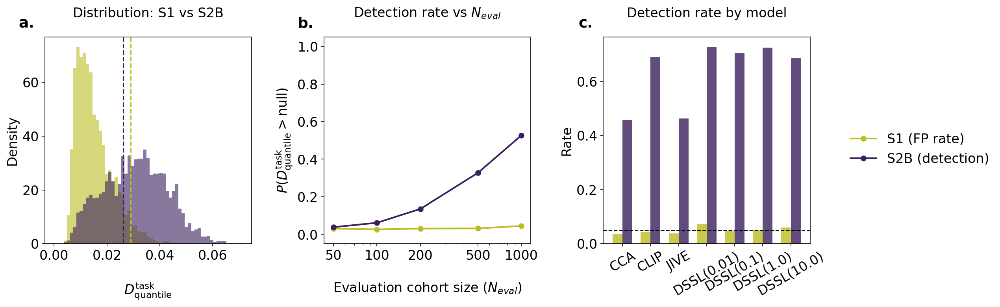

Saved fig_dquantile_discrimination


In [11]:
s1_dq  = df[(df['n_eval']==1000) & df['alpha_config_id'].str.startswith('s1')  & ~df['is_proxy_run'] & (df['measurement_regime']=='baseline')]['dquantile_task']
s2b_dq = df[(df['n_eval']==1000) & df['alpha_config_id'].str.startswith('s2b') & ~df['is_proxy_run'] & (df['measurement_regime']=='baseline')]['dquantile_task']
s1_null  = df[(df['n_eval']==1000) & df['alpha_config_id'].str.startswith('s1')  & ~df['is_proxy_run'] & (df['measurement_regime']=='baseline')]['dquantile_task_null_upper']
s2b_null = df[(df['n_eval']==1000) & df['alpha_config_id'].str.startswith('s2b') & ~df['is_proxy_run'] & (df['measurement_regime']=='baseline')]['dquantile_task_null_upper']

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

_rows_dq = []

ax = axes[0]
bins = np.linspace(0, max(s1_dq.max(), s2b_dq.max()), 60)
ax.hist(s1_dq, bins=bins, alpha=0.6, color=SC_COLORS['scenario_1'], label=f'S1 (n={len(s1_dq):,})', density=True)
ax.hist(s2b_dq, bins=bins, alpha=0.6, color=SC_COLORS['scenario_2'], label=f'S2B (n={len(s2b_dq):,})', density=True)
ax.axvline(s1_null.mean(), ls='--', color=SC_COLORS['scenario_1'], lw=1.5, label=f'S1 null upper ({s1_null.mean():.3f})')
ax.axvline(s2b_null.mean(), ls='--', color=SC_COLORS['scenario_2'], lw=1.5, label=f'S2B null upper ({s2b_null.mean():.3f})')
ax.set_xlabel('\n$D_{\\mathrm{quantile}}^{\\mathrm{task}}$')
ax.set_ylabel('Density')
ax.set_title('Distribution: S1 vs S2B\n')
ax.grid(False)
ax.text(-0.05, 1.03, 'a.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

ax = axes[1]
for label, prefix, color, is_proxy in [('S1 (FP rate)', 's1', SC_COLORS['scenario_1'], False),
                               ('S2B (detection)', 's2b', SC_COLORS['scenario_2'], False)]:
    rates, n_evals = [], [50, 100, 200, 500, 1000]
    for ne in n_evals:
        sub = df[(df['n_eval']==ne) & df['alpha_config_id'].str.startswith(prefix) & ~df['is_proxy_run']]
        rate = (sub['dquantile_task'] > sub['dquantile_task_null_upper']).mean()
        rates.append(rate)
        _rows_dq.append({'scenario_class': label, 'model': 'all', 'n_eval': ne, 'dq_fire_rate': rate})
    ax.plot(n_evals, rates, 'o-', color=color, lw=2, label=label)
ax.set_xlabel('\nEvaluation cohort size ($N_{eval}$)')
ax.set_ylabel('$P(D_{\\mathrm{quantile}}^{\\mathrm{task}} > \\mathrm{null})$')
ax.set_xscale('log'); ax.set_xticks([50,100,200,500,1000]); ax.set_xticklabels([50,100,200,500,1000])
ax.set_ylim(-0.05, 1.05)
ax.set_title('Detection rate vs $N_{eval}$\n')
ax.grid(False)
ax.text(-0.05, 1.03, 'b.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

ax = axes[2]
x = np.arange(len(MODEL_ORDER)); w = 0.35
s1_r, s2b_r = [], []
for model in MODEL_ORDER:
    ss1 = df[(df['n_eval']==1000) & df['alpha_config_id'].str.startswith('s1') & ~df['is_proxy_run'] & (df['measurement_regime']=='baseline') & (df['model_label']==model)]
    ss2 = df[(df['n_eval']==1000) & df['alpha_config_id'].str.startswith('s2b') & ~df['is_proxy_run'] & (df['measurement_regime']=='baseline') & (df['model_label']==model)]
    r1 = (ss1['dquantile_task'] > ss1['dquantile_task_null_upper']).mean()
    r2 = (ss2['dquantile_task'] > ss2['dquantile_task_null_upper']).mean()
    s1_r.append(r1); s2b_r.append(r2)
    _rows_dq.append({'scenario_class': 'S1', 'model': model, 'n_eval': 1000, 'dq_fire_rate': r1})
    _rows_dq.append({'scenario_class': 'S2B', 'model': model, 'n_eval': 1000, 'dq_fire_rate': r2})
ax.bar(x-w/2, s1_r, w, label='S1 (FP rate)', color=SC_COLORS['scenario_1'], alpha=0.8)
ax.bar(x+w/2, s2b_r, w, label='S2B (detection rate)', color=SC_COLORS['scenario_2'], alpha=0.8)
ax.axhline(0.05, ls='--', color='black', lw=1.2, label='5% threshold')
ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=30, ha='center')
ax.set_ylabel('Rate')
ax.set_title('Detection rate by model\n')
ax.grid(False)
ax.text(-0.05, 1.03, 'c.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

fig.legend(
    *axes[1].get_legend_handles_labels(),
    bbox_to_anchor=(0.91, 0.5), loc='center left', frameon=False,
)
fig.subplots_adjust(left=0.07, right=0.88, top=0.88, bottom=0.18, wspace=0.35)
plt.show()
save_fig(fig, 'fig_dquantile_discrimination', pd.DataFrame(_rows_dq))

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 12 — D_quantile S2 proxy discrimination

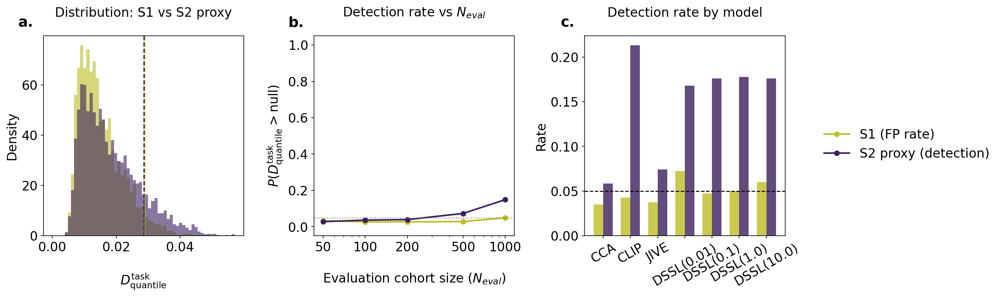

Saved fig_dquantile_discrimination_s2a


In [12]:
# Pre-filter once to avoid repeated str.startswith on 589K rows inside loops
_base_s1  = df[(df['measurement_regime']=='baseline') & ~df['is_proxy_run'] &
               df['alpha_config_id'].str.startswith('s1')].copy()
_base_s2p = df[(df['measurement_regime']=='baseline') &  df['is_proxy_run'] &
               df['alpha_config_id'].str.startswith('s2a')].copy()

_ne1000_s1  = _base_s1[_base_s1['n_eval']==1000]
_ne1000_s2p = _base_s2p[_base_s2p['n_eval']==1000]

s1_dq_p   = _ne1000_s1['dquantile_task']
s2a_dq    = _ne1000_s2p['dquantile_task']
s1_null_p = _ne1000_s1['dquantile_task_null_upper']
s2a_null  = _ne1000_s2p['dquantile_task_null_upper']

S2A_COLOR = SC_COLORS['scenario_2']

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

_rows_dq_s2a = []

# Panel a — distributions
ax = axes[0]
bins = np.linspace(0, max(s1_dq_p.max(), s2a_dq.max()), 60)
ax.hist(s1_dq_p, bins=bins, alpha=0.6, color=SC_COLORS['scenario_1'], label=f'S1 (n={len(s1_dq_p):,})', density=True)
ax.hist(s2a_dq, bins=bins, alpha=0.6, color=S2A_COLOR, label=f'S2 proxy (n={len(s2a_dq):,})', density=True)
ax.axvline(s1_null_p.mean(), ls='--', color=SC_COLORS['scenario_1'], lw=1.5, label=f'S1 null upper ({s1_null_p.mean():.3f})')
ax.axvline(s2a_null.mean(), ls='--', color=S2A_COLOR, lw=1.5, label=f'S2 proxy null upper ({s2a_null.mean():.3f})')
ax.set_xlabel('\n$D_{\\mathrm{quantile}}^{\\mathrm{task}}$')
ax.set_ylabel('Density')
ax.set_title('Distribution: S1 vs S2 proxy\n')
ax.grid(False)
ax.text(-0.05, 1.03, 'a.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

# Panel b — detection rate vs N_eval
ax = axes[1]
for label, base_df, color in [
    ('S1 (FP rate)',         _base_s1,  SC_COLORS['scenario_1']),
    ('S2 proxy (detection)', _base_s2p, S2A_COLOR),
]:
    rates, n_evals = [], [50, 100, 200, 500, 1000]
    for ne in n_evals:
        sub = base_df[base_df['n_eval']==ne]
        rate = (sub['dquantile_task'] > sub['dquantile_task_null_upper']).mean()
        rates.append(rate)
        _rows_dq_s2a.append({'scenario_class': label, 'model': 'all', 'n_eval': ne, 'dq_fire_rate': rate})
    ax.plot(n_evals, rates, 'o-', color=color, lw=2, label=label)
ax.axhline(0.05, ls=':', color='grey', lw=1.2)
ax.set_xlabel('\nEvaluation cohort size ($N_{eval}$)')
ax.set_ylabel('$P(D_{\\mathrm{quantile}}^{\\mathrm{task}} > \\mathrm{null})$')
ax.set_xscale('log'); ax.set_xticks([50,100,200,500,1000]); ax.set_xticklabels([50,100,200,500,1000])
ax.set_ylim(-0.05, 1.05)
ax.set_title('Detection rate vs $N_{eval}$\n')
ax.grid(False)
ax.text(-0.05, 1.03, 'b.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

# Panel c — fire rate by model (pre-filtered, just index by model_label)
ax = axes[2]
x = np.arange(len(MODEL_ORDER)); w = 0.35
s1_rp, s2a_r = [], []
for model in MODEL_ORDER:
    r1 = (_ne1000_s1[_ne1000_s1['model_label']==model].eval(
           'dquantile_task > dquantile_task_null_upper')).mean()
    r2 = (_ne1000_s2p[_ne1000_s2p['model_label']==model].eval(
           'dquantile_task > dquantile_task_null_upper')).mean()
    s1_rp.append(r1); s2a_r.append(r2)
    _rows_dq_s2a.append({'scenario_class': 'S1',       'model': model, 'n_eval': 1000, 'dq_fire_rate': r1})
    _rows_dq_s2a.append({'scenario_class': 'S2_proxy', 'model': model, 'n_eval': 1000, 'dq_fire_rate': r2})
ax.bar(x-w/2, s1_rp, w, label='S1 (FP rate)',         color=SC_COLORS['scenario_1'], alpha=0.8)
ax.bar(x+w/2, s2a_r,  w, label='S2 proxy (detection)', color=S2A_COLOR, alpha=0.8)
ax.axhline(0.05, ls='--', color='black', lw=1.2, label='5% threshold')
ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=30, ha='center')
ax.set_ylabel('Rate')
ax.set_title('Detection rate by model\n')
ax.grid(False)
ax.text(-0.05, 1.03, 'c.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

fig.legend(
    *axes[1].get_legend_handles_labels(),
    bbox_to_anchor=(0.91, 0.5), loc='center left', frameon=False,
)
fig.subplots_adjust(left=0.07, right=0.88, top=0.88, bottom=0.18, wspace=0.35)
plt.show()
save_fig(fig, 'fig_dquantile_discrimination_s2a', pd.DataFrame(_rows_dq_s2a))

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 13 — P_transfer detection sensitivity

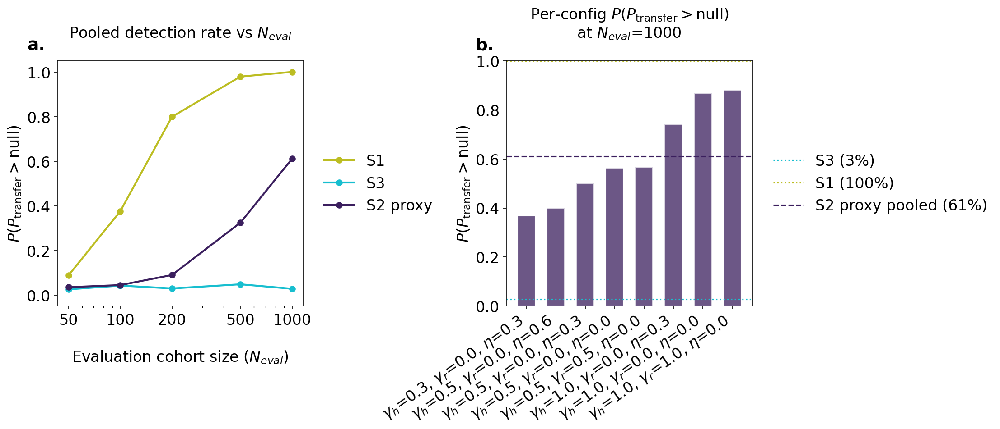

Saved fig_anorm_vs_ptransfer_diagnostic


In [13]:
SC_DEFS = [
    ('S1',       SC_COLORS['scenario_1'], 'o', lambda d: ~d['is_proxy_run'] & d['alpha_config_id'].str.startswith('s1')),
    ('S3',       SC_COLORS['scenario_3'], 's', lambda d: ~d['is_proxy_run'] & d['alpha_config_id'].str.startswith('s3')),
    ('S2 proxy', SC_COLORS['scenario_2'], '^', lambda d:  d['is_proxy_run'] & d['alpha_config_id'].str.startswith('s2a')),
]
BASE_MASK = df['measurement_regime'] == 'baseline'
N_EVALS_LINE = [50, 100, 200, 500, 1000]
df['pt_fires'] = df['p_transfer'] > df['transfer_null_upper']

def _parse_proxy(run_id):
    p = run_id.split('_')
    return float(p[1][1:]), float(p[2][1:]), float(p[3][1:])

proxy_base = df[BASE_MASK & df['is_proxy_run'] & df['alpha_config_id'].str.startswith('s2a')].copy()
proxy_base[['gamma_h','gamma_r','eta']] = proxy_base['run_id'].apply(lambda r: pd.Series(_parse_proxy(r)))
proxy_base['proxy_cfg'] = proxy_base.apply(lambda r: f'$\\gamma_h$={r.gamma_h:.1f}, $\\gamma_r$={r.gamma_r:.1f}, $\\eta$={r.eta:.1f}', axis=1)

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

_rows_pt = []

ax = axes[0]
for sc_label, color, marker, mask_fn in SC_DEFS:
    rates = []
    for ne in N_EVALS_LINE:
        rate = (df[BASE_MASK & (df['n_eval']==ne) & mask_fn(df)]['pt_fires']).mean()
        rates.append(rate)
        _rows_pt.append({'panel': 'pooled', 'scenario': sc_label, 'n_eval': ne,
                         'proxy_cfg': 'all', 'pt_fire_rate': rate})
    ax.plot(N_EVALS_LINE, rates, 'o-', color=color, lw=2, markersize=6, label=sc_label)

s2_1000 = (df[BASE_MASK & (df['n_eval']==1000) & df['is_proxy_run'] & df['alpha_config_id'].str.startswith('s2a')]['pt_fires']).mean()
ax.set_xlabel('\nEvaluation cohort size ($N_{eval}$)')
ax.set_ylabel(r'$P(P_{\mathrm{transfer}} > \mathrm{null})$')
ax.set_xscale('log'); ax.set_xticks([50,100,200,500,1000]); ax.set_xticklabels([50,100,200,500,1000])
ax.set_ylim(-0.05, 1.05)
ax.set_title('Pooled detection rate vs $N_{eval}$\n')
ax.legend(loc='center left', bbox_to_anchor=(1.03, 0.5), frameon=False)
ax.grid(False)
ax.set_box_aspect(1)
ax.text(-0.05, 1.03, 'a.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

ax = axes[1]
cfg_rates = (proxy_base[proxy_base['n_eval']==1000]
             .groupby('proxy_cfg')
             .apply(lambda x: (x['p_transfer'] > x['transfer_null_upper']).mean(), include_groups=False)
             .sort_values())
ax.bar(range(len(cfg_rates)), cfg_rates.values, color=SC_COLORS['scenario_2'], alpha=0.75, edgecolor='white', width=0.6)
ax.set_xticks(range(len(cfg_rates))); ax.set_xticklabels(cfg_rates.index, rotation=35, ha='right')
s3_rate = (df[BASE_MASK & (df['n_eval']==1000) & ~df['is_proxy_run'] & df['alpha_config_id'].str.startswith('s3')]['pt_fires']).mean()
s1_rate_pt = (df[BASE_MASK & (df['n_eval']==1000) & ~df['is_proxy_run'] & df['alpha_config_id'].str.startswith('s1')]['pt_fires']).mean()
ax.axhline(s3_rate, ls=':', color=SC_COLORS['scenario_3'], lw=1.5, label=f'S3 ({s3_rate:.0%})')
ax.axhline(s1_rate_pt, ls=':', color=SC_COLORS['scenario_1'], lw=1.5, label=f'S1 ({s1_rate_pt:.0%})')
ax.axhline(s2_1000, ls='--', color=SC_COLORS['scenario_2'], lw=1.5, label=f'S2 proxy pooled ({s2_1000:.0%})')
ax.set_ylabel(r'$P(P_{\mathrm{transfer}} > \mathrm{null})$')
ax.set_title('Per-config $P(P_{\mathrm{transfer}} > \mathrm{null})$\nat $N_{eval}$=1000\n')
ax.set_ylim(0, 1.0)
ax.legend(loc='center left', bbox_to_anchor=(1.03, 0.5), frameon=False)
ax.grid(False)
ax.set_box_aspect(1)
ax.text(-0.05, 1.03, 'b.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

for cfg, rate in cfg_rates.items():
    _rows_pt.append({'panel': 'per_config', 'scenario': 'S2_proxy', 'n_eval': 1000,
                     'proxy_cfg': cfg, 'pt_fire_rate': rate})

fig.subplots_adjust(left=0.07, right=0.88, top=0.88, bottom=0.22, wspace=0.2)
plt.show()
save_fig(fig, 'fig_anorm_vs_ptransfer_diagnostic', pd.DataFrame(_rows_pt))

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 14 — Saturation curves (all regimes)

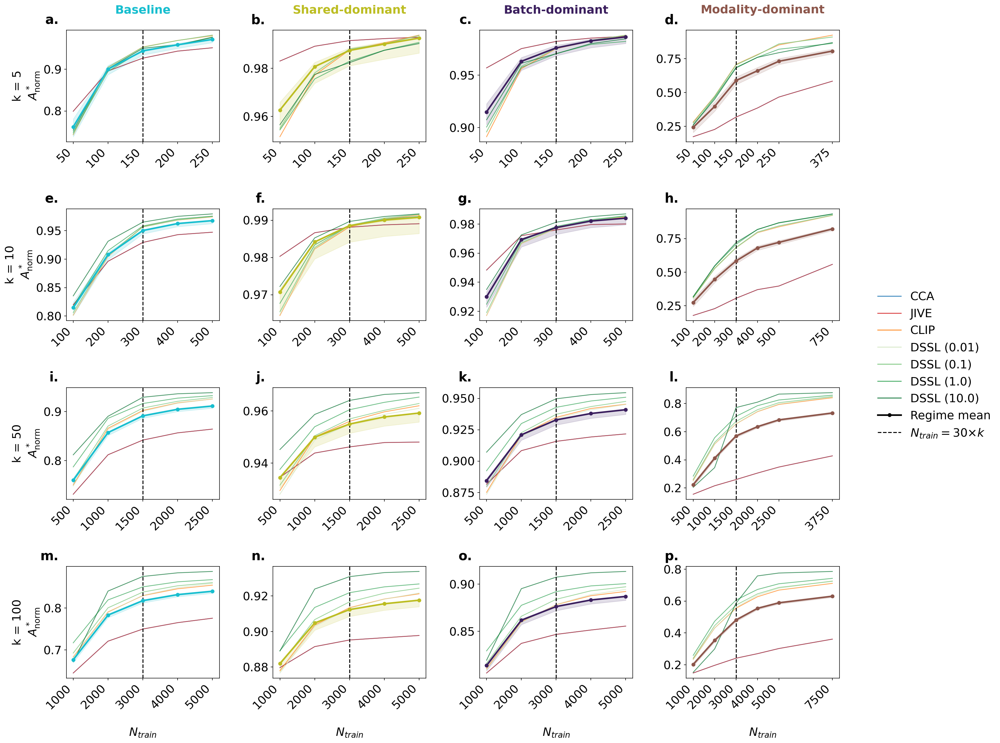

Saved fig_regimes_all_k_saturation


In [14]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        18,
    'axes.titlesize':   18,
    'axes.labelsize':   18,
    'xtick.labelsize':  18,
    'ytick.labelsize':  18,
    'legend.fontsize':  18,
})
_PANEL_LABEL_SIZE = 20

def _mfj(name):
    if name.startswith('cca'):   return 'CCA'
    if name.startswith('jive'):  return 'JIVE'
    if name.startswith('clip'):  return 'CLIP'
    if '10.0' in name:           return 'DSSL (10.0)'
    if 'l1.0' in name:           return 'DSSL (1.0)'
    if 'l0.1' in name:           return 'DSSL (0.1)'
    if 'l0.01' in name:          return 'DSSL (0.01)'
    return name

NB11_FAM = ['CCA', 'JIVE', 'CLIP', 'DSSL (0.01)', 'DSSL (0.1)', 'DSSL (1.0)', 'DSSL (10.0)']

# Map NB11 family names (with space) to shared COLORS palette (without space)
NB11_COL = {
    'CCA':          COLORS['CCA'],
    'JIVE':         COLORS['JIVE'],
    'CLIP':         COLORS['CLIP'],
    'DSSL (0.01)':  COLORS['DSSL(0.01)'],
    'DSSL (0.1)':   COLORS['DSSL(0.1)'],
    'DSSL (1.0)':   COLORS['DSSL(1.0)'],
    'DSSL (10.0)':  COLORS['DSSL(10.0)'],
}

_PRE_STEP_A_DIR = DATA_DIR / 'pre_step_a'
NB11_REG_PATHS = {
    'Baseline':          _PRE_STEP_A_DIR / 'pre_step_a_jive.json',
    'Shared-dominant':   _PRE_STEP_A_DIR / 'pre_step_a_shared_dominant_v2.json',
    'Batch-dominant':    _PRE_STEP_A_DIR / 'pre_step_a_batch_dominant_v2.json',
    'Modality-dominant': _PRE_STEP_A_DIR / 'pre_step_a_modality_dominant.json',
}
NB11_REG_COL = {
    'Baseline':          REGIME_COLORS['baseline'],
    'Shared-dominant':   REGIME_COLORS['shared_dominant'],
    'Batch-dominant':    REGIME_COLORS['batch_dominant'],
    'Modality-dominant': REGIME_COLORS['modality_dominant'],
}

nb11_dfs = {}
for label, path in NB11_REG_PATHS.items():
    try:
        d = pd.DataFrame(json.load(open(path)))
        d['family'] = d['model'].apply(_mfj)
        nb11_dfs[label] = d
    except FileNotFoundError:
        print(f'{label}: PENDING')

k_vals_plot = [5, 10, 50, 100]
reg_lbls    = list(nb11_dfs.keys())
n_rows, n_cols = len(k_vals_plot), len(reg_lbls)

# Square-ish panels: each ~4 inches wide × 3.5 inches tall
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 16), sharey=False)

_rows_sat = []
for row_i, k in enumerate(k_vals_plot):
    for col_i, (label, df_r) in enumerate(nb11_dfs.items()):
        ax = axes[row_i, col_i]
        sub_k = df_r[df_r['k'] == k]
        if len(sub_k) == 0: ax.set_visible(False); continue
        mults_r = sorted(sub_k['n_train_mult'].unique())
        ns      = [m * k for m in mults_r]
        color   = NB11_REG_COL[label]

        for fam in NB11_FAM:
            sub = sub_k[sub_k['family'] == fam]
            if len(sub) == 0: continue
            m_vals = sub.groupby('n_train_mult')['anorm_star'].mean().reindex(mults_r)
            ax.plot(ns, m_vals.values, '-', color=NB11_COL[fam], lw=1.2, alpha=0.7)

        means = sub_k.groupby('n_train_mult')['anorm_star'].mean().reindex(mults_r)
        ci_lo = sub_k.groupby('n_train_mult')['ci_lower'].mean().reindex(mults_r)
        ci_hi = sub_k.groupby('n_train_mult')['ci_upper'].mean().reindex(mults_r)
        ax.plot(ns, means.values, 'o-', color=color, lw=2.5, markersize=5, zorder=5)
        ax.fill_between(ns, ci_lo.values, ci_hi.values, alpha=0.15, color=color)
        ax.axvline(30 * k, color='black', ls='--', lw=1.5)
        ax.grid(False)

        ax.set_xticks(ns)
        ax.set_xticklabels([str(n) for n in ns], rotation=45, ha='right')
        if row_i == 0:
            ax.set_title(f'{label}\n', fontweight='bold', color=color)
        if col_i == 0:
            ax.set_ylabel(f'k = {k}\n$A_{{\\mathrm{{norm}}}}^*$')
        if row_i == n_rows - 1:
            ax.set_xlabel('\n$N_{train}$')

        for mult, mv, lo, hi in zip(mults_r, means.values, ci_lo.values, ci_hi.values):
            _rows_sat.append({'regime': label, 'k': k, 'n_train_mult': mult,
                              'anorm_star_mean': mv, 'ci_lower': lo, 'ci_upper': hi})

# Panel labels
for idx, ax in enumerate([axes[r][c] for r in range(n_rows) for c in range(n_cols)]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

# Legend on right, centred
h_models = [plt.Line2D([0],[0], color=NB11_COL[f], lw=1.5, alpha=0.8, label=f) for f in NB11_FAM]
h_mean   = plt.Line2D([0],[0], color='black', lw=2.5, marker='o', markersize=5, label='Regime mean')
h_ntr    = plt.Line2D([0],[0], color='black', lw=1.5, ls='--', label='$N_{train}=30{\\times}k$')
fig.legend(handles=h_models + [h_mean, h_ntr],
           loc='center left', ncol=1, bbox_to_anchor=(0.93, 0.5), frameon=False)

fig.subplots_adjust(left=0.07, right=0.90, top=0.95, bottom=0.08, hspace=0.60, wspace=0.35)

plt.show()
save_fig(fig, 'fig_regimes_all_k_saturation', pd.DataFrame(_rows_sat))

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,
                     'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 15 — Shared-dominant alpha curves

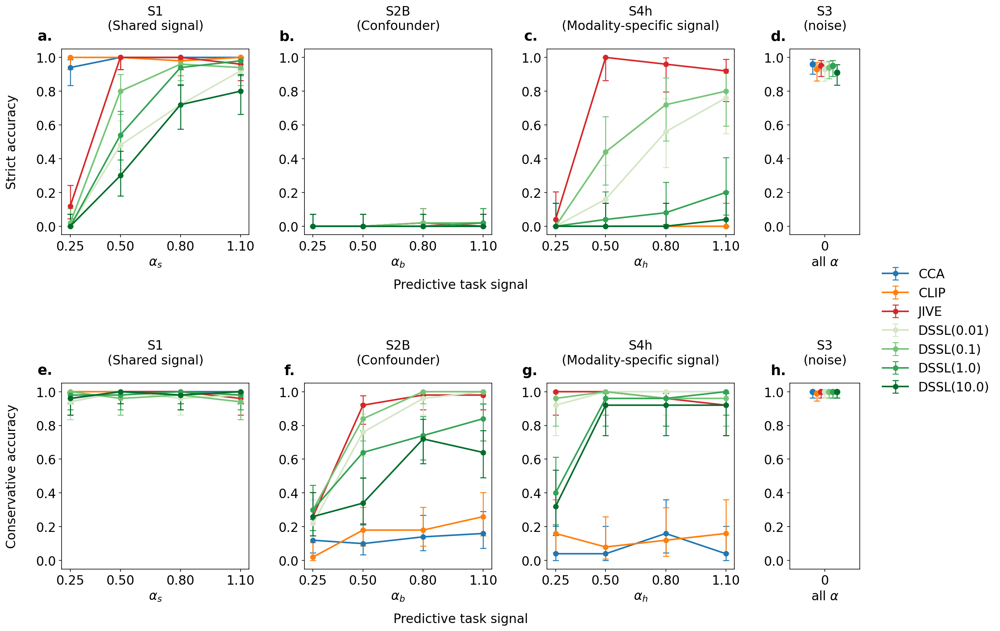

Saved fig_main_shared_dominant_alpha_curves


In [15]:
make_regime_alpha_fig('shared_dominant', 'fig_main_shared_dominant_alpha_curves')

## Fig 16 — Batch-dominant alpha curves

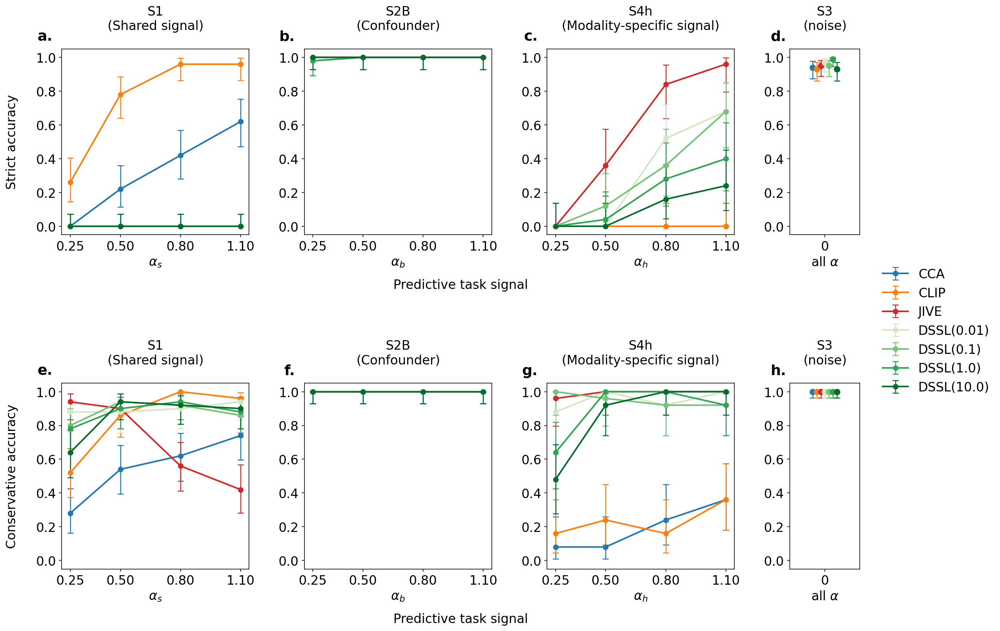

Saved fig_main_batch_dominant_alpha_curves


In [16]:
make_regime_alpha_fig('batch_dominant', 'fig_main_batch_dominant_alpha_curves')

## Fig 17 — Modality-dominant alpha curves

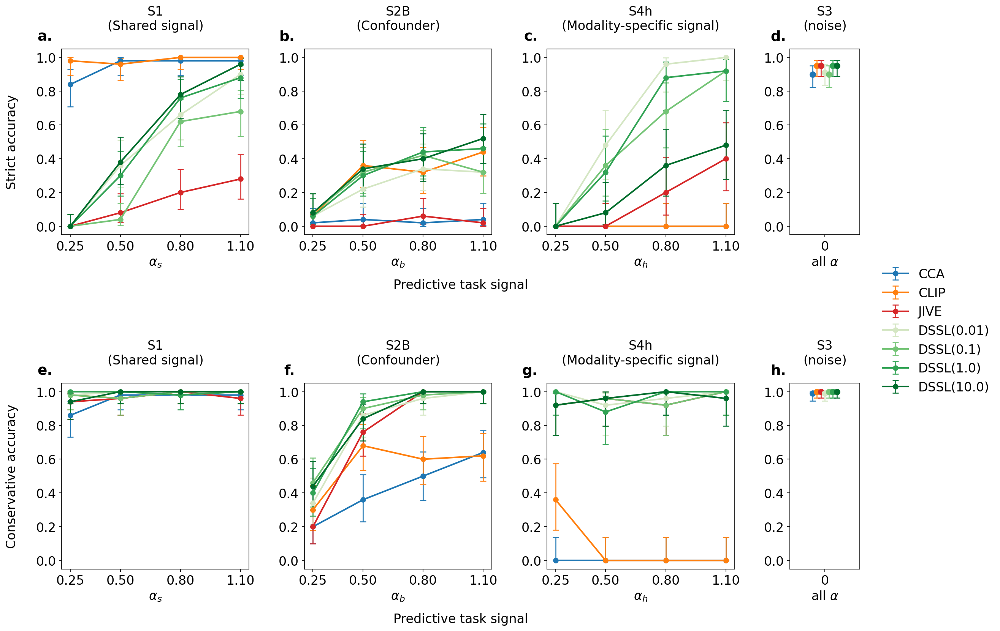

Saved fig_main_modality_dominant_alpha_curves


In [17]:
make_regime_alpha_fig('modality_dominant', 'fig_main_modality_dominant_alpha_curves')

## Fig 18 — Detection rate vs N_eval

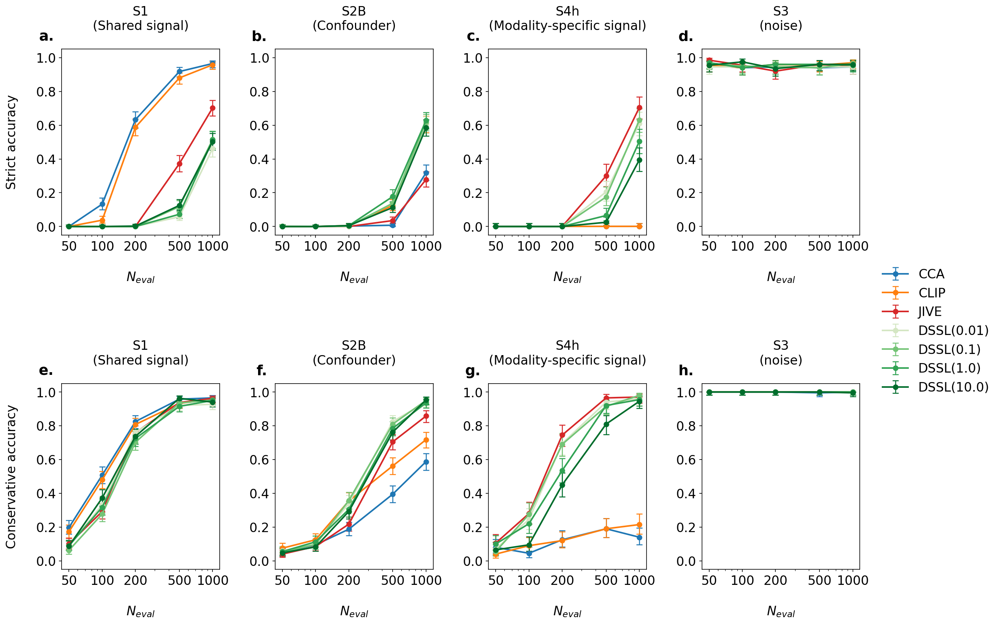

Saved fig_main_baseline_alpha_curves_neval


In [18]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

_TITLES = {
    'scenario_1': 'S1\n(Shared signal)\n',
    'scenario_2': 'S2B\n(Confounder)\n',
    'scenario_4': 'S4h\n(Modality-specific signal)\n',
}
_YLABELS = {False: 'Strict accuracy\n', True: 'Conservative accuracy\n'}
_N_EVALS = [50, 100, 200, 500, 1000]

fig = plt.figure(figsize=(20, 11))
gs_ne = GridSpec(2, 4, figure=fig, width_ratios=[4,4,4,4], hspace=0.8, wspace=0.35)
axes_ne = [[fig.add_subplot(gs_ne[r,c]) for c in range(4)] for r in range(2)]

_rows_neval = []
for row_i, (is_consv, _) in enumerate([(False, 'Strict'), (True, 'Conservative')]):
    for col_i, (gt, ac, pfx, mf) in enumerate(ALPHA_SCENARIOS):
        ax = axes_ne[row_i][col_i]
        base = df_baseline[df_baseline['alpha_config_id'].str.startswith(pfx) & (df_baseline['ground_truth']==gt)]
        if mf: base = base[base['modality']==mf]
        for model in MODEL_ORDER:
            sub = base[base['model_label']==model]
            rates, ci_lo, ci_hi = [], [], []
            for ne in _N_EVALS:
                s = sub[sub['n_eval']==ne]; n = len(s)
                k = int(((s['predicted_scenario']==gt)|(s['predicted_scenario']=='indeterminate')).sum()) if is_consv \
                    else int((s['predicted_scenario']==gt).sum())
                lo, hi = clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
                rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
                _rows_neval.append({'scenario': gt, 'model': model, 'n_eval': ne,
                                    'row_type': 'conservative' if is_consv else 'strict',
                                    'rate': k/n if n>0 else float('nan'), 'ci_lower': lo, 'ci_upper': hi})
            rates = np.array(rates)
            ax.errorbar(_N_EVALS, rates,
                        yerr=[np.maximum(0,rates-np.array(ci_lo)), np.maximum(0,np.array(ci_hi)-rates)],
                        fmt='o-', color=COLORS[model], lw=2, markersize=6,
                        capsize=4, capthick=1.2, elinewidth=1.2, label=model)
        ax.set_xscale('log'); ax.set_xticks(_N_EVALS); ax.set_xticklabels(_N_EVALS)
        ax.set_ylim(-0.05, 1.05); ax.grid(False)
        ax.set_title(_TITLES[gt])
        if col_i == 0: ax.set_ylabel(_YLABELS[is_consv])
        ax.set_xlabel('\n$N_{eval}$')

    ax = axes_ne[row_i][3]
    bs3 = df_baseline[df_baseline['alpha_config_id'].str.startswith('s3') & (df_baseline['ground_truth']=='scenario_3')]
    for model in MODEL_ORDER:
        sub = bs3[bs3['model_label']==model]; rates, ci_lo, ci_hi = [], [], []
        for ne in _N_EVALS:
            s = sub[sub['n_eval']==ne]; n = len(s)
            k = int(((s['predicted_scenario']=='scenario_3')|(s['predicted_scenario']=='indeterminate')).sum()) if is_consv \
                else int((s['predicted_scenario']=='scenario_3').sum())
            lo, hi = clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
            rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
            _rows_neval.append({'scenario': 'scenario_3', 'model': model, 'n_eval': ne,
                                'row_type': 'conservative' if is_consv else 'strict',
                                'rate': k/n if n>0 else float('nan'), 'ci_lower': lo, 'ci_upper': hi})
        rates = np.array(rates)
        ax.errorbar(_N_EVALS, rates,
                    yerr=[np.maximum(0,rates-np.array(ci_lo)), np.maximum(0,np.array(ci_hi)-rates)],
                    fmt='o-', color=COLORS[model], lw=2, markersize=6,
                    capsize=4, capthick=1.2, elinewidth=1.2)
    ax.set_xscale('log'); ax.set_xticks(_N_EVALS); ax.set_xticklabels(_N_EVALS)
    ax.set_ylim(-0.05, 1.05); ax.grid(False)
    ax.set_xlabel('\n$N_{eval}$')
    ax.set_title('S3\n(noise)\n')

# Panel labels
for idx, ax in enumerate([axes_ne[r][c] for r in range(2) for c in range(4)]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

fig.subplots_adjust(left=0.12, right=0.82, top=0.95, bottom=0.12, hspace=0.8, wspace=0.35)

handles, labels = axes_ne[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', ncol=1, bbox_to_anchor=(0.83, 0.5), frameon=False)

plt.show()
save_fig(fig, 'fig_main_baseline_alpha_curves_neval', pd.DataFrame(_rows_neval))

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 14,
    'axes.titlesize': 14, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
})


## Fig 19 — FSCR shared-dominant

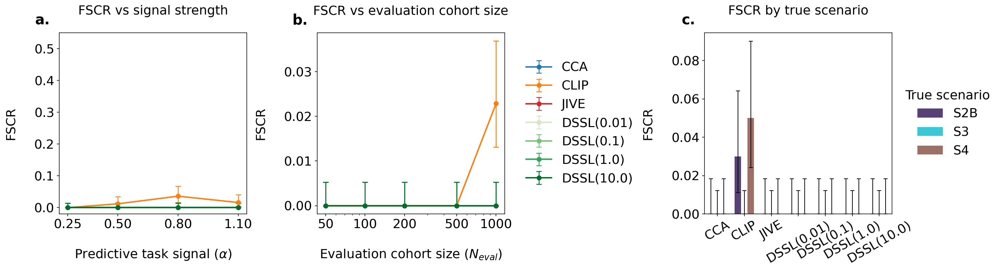

Saved fig_fscr_shared_dominant


In [19]:
make_regime_fscr_fig('shared_dominant', 'fig_fscr_shared_dominant')

## Fig 20 — FSCR batch-dominant

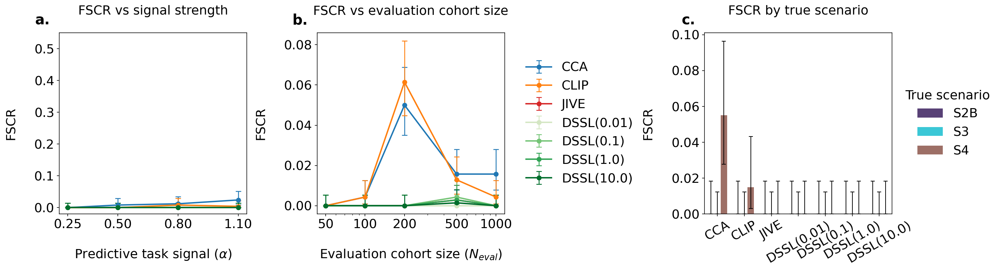

Saved fig_fscr_batch_dominant


In [20]:
make_regime_fscr_fig('batch_dominant', 'fig_fscr_batch_dominant')

## Fig 21 — FSCR modality-dominant

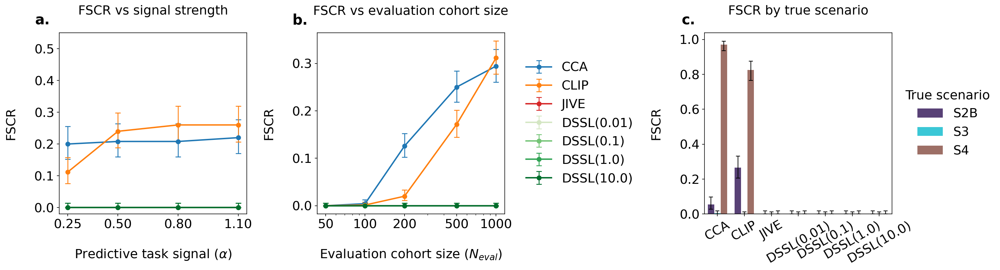

Saved fig_fscr_modality_dominant


In [21]:
make_regime_fscr_fig('modality_dominant', 'fig_fscr_modality_dominant')

## Fig 23 — Proxy S1 detection by condition

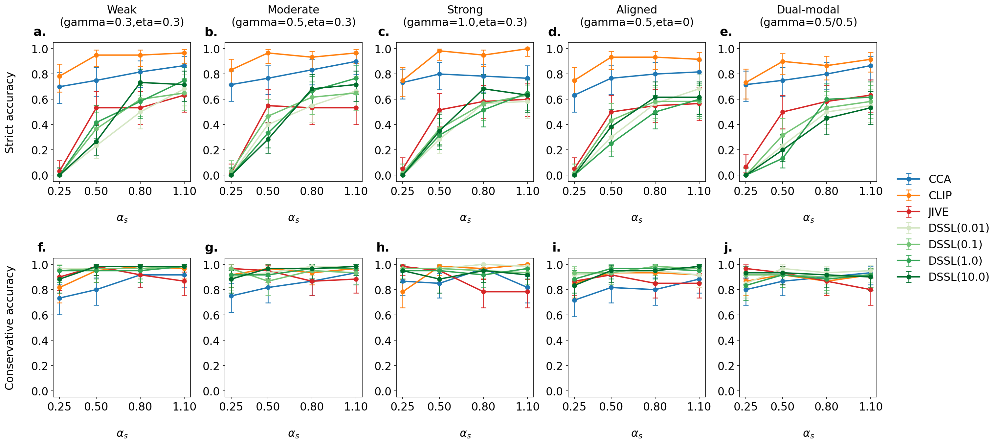

Saved fig_proxy_s1_detection_by_condition


In [22]:
make_proxy_alpha_fig(
    detect_gt='scenario_1', alpha_col='alpha_s', alpha_prefix='s1', s2a_mode=False,
    suptitle='',
    fname='fig_proxy_s1_detection_by_condition',
)


## Fig 24 — Proxy S2A detection by condition

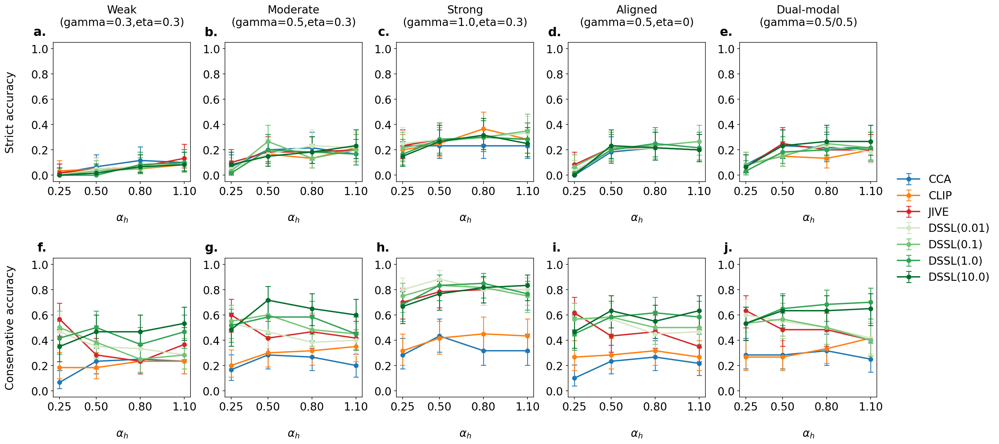

Saved fig_proxy_s2a_detection_by_condition


In [23]:
make_proxy_alpha_fig(
    detect_gt='scenario_2', alpha_col='alpha_h', alpha_prefix='s2a', s2a_mode=True,
    suptitle='',
    fname='fig_proxy_s2a_detection_by_condition',
)


## Fig 25 — Mixed resolution + indet sensitivity

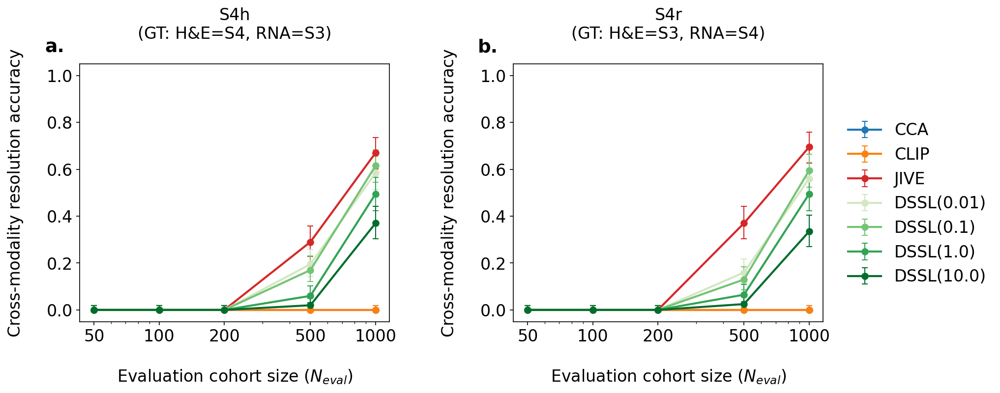

Saved fig_mixed_resolution_and_indet_sensitivity


In [24]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

S4_EXPECTED = {'s4h': {'h':'scenario_4','r':'scenario_3'}, 's4r': {'h':'scenario_3','r':'scenario_4'}}
S4_LABELS   = {'s4h':'S4h\n(GT: H&E=S4, RNA=S3)\n', 's4r':'S4r\n(GT: H&E=S3, RNA=S4)\n'}

df_base_s4 = df_pure[(df_pure['measurement_regime']=='baseline') & (~df_pure['is_proxy_run'])]

fig = plt.figure(figsize=(14, 5))
gs23 = GridSpec(1, 2, figure=fig, wspace=0.4)
ax_s4h = fig.add_subplot(gs23[0, 0])
ax_s4r = fig.add_subplot(gs23[0, 1])

rows_s4 = []
for ax, prefix in zip([ax_s4h, ax_s4r], ['s4h', 's4r']):
    exp = S4_EXPECTED[prefix]
    sub_type = df_base_s4[df_base_s4['alpha_config_id'].str.startswith(prefix)]
    for model in MODEL_ORDER:
        sub_m = sub_type[sub_type['model_label']==model]
        rates, ci_lo, ci_hi = [], [], []
        for ne in [50,100,200,500,1000]:
            sub_ne = sub_m[sub_m['n_eval']==ne]
            nt=0; nc=0
            for (rid,cid),grp in sub_ne.groupby(['run_id','alpha_config_id']):
                if len(grp)!=2: continue
                nt+=1; nc+=int(all(row['predicted_scenario']==exp[row['modality']] for _,row in grp.iterrows()))
            rate=nc/nt if nt>0 else float('nan')
            lo,hi=clopper_pearson(nc,nt) if nt>0 else (float('nan'),float('nan'))
            rates.append(rate); ci_lo.append(lo); ci_hi.append(hi)
            rows_s4.append({'config_type':prefix,'model':model,'n_eval':ne,
                             'bilateral_acc':rate,'ci_lower':lo,'ci_upper':hi,'n_pairs':nt})
        rates=np.array(rates)
        ax.errorbar([50,100,200,500,1000],rates,
                    yerr=[np.maximum(0,rates-np.array(ci_lo)),np.maximum(0,np.array(ci_hi)-rates)],
                    fmt='o-',color=COLORS[model],lw=2,markersize=6,capsize=3,capthick=1,elinewidth=1,label=model)
    ax.set_xscale('log'); ax.set_xticks([50, 100, 200, 500, 1000]); ax.set_xticklabels([50, 100, 200, 500, 1000])
    ax.set_xlabel('\nEvaluation cohort size ($N_{eval}$)')
    ax.set_ylabel('Cross-modality resolution accuracy\n')
    ax.set_title(S4_LABELS[prefix]); ax.set_ylim(-0.05,1.05); ax.grid(False)

# Panel labels
for idx, ax in enumerate([ax_s4h, ax_s4r]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

fig.subplots_adjust(left=0.10, right=0.82, top=0.88, bottom=0.18, wspace=0.5)

handles, labels = ax_s4h.get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', ncol=1, bbox_to_anchor=(0.83, 0.5), frameon=False)

plt.show()
save_fig(fig, 'fig_mixed_resolution_and_indet_sensitivity', pd.DataFrame(rows_s4))

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 14,
    'axes.titlesize': 14, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
})


## Fig 26 — Per-modality mixed accuracy

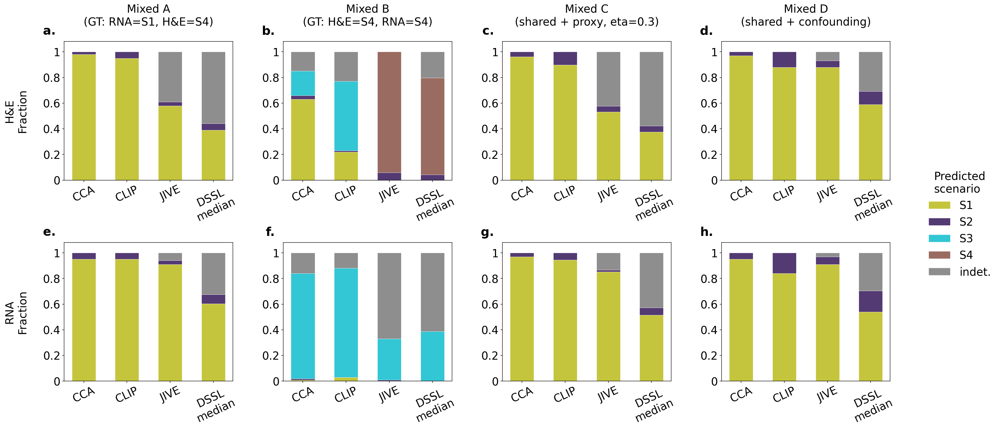

Saved fig_mixed_per_modality


In [25]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        20,
    'axes.titlesize':   20,
    'axes.labelsize':   20,
    'xtick.labelsize':  20,
    'ytick.labelsize':  20,
    'legend.fontsize':  20,
})
_PANEL_LABEL_SIZE = 22

fig, axes = plt.subplots(2, 4, figsize=(24, 11), sharey=False)

bar_w_mm = 0.55
_rows_mpm = []
for col_i, mtype in enumerate(['mixed_a', 'mixed_b', 'mixed_c', 'mixed_d']):
    if mtype == 'mixed_c':
        sub_type = df[(df['alpha_config_id'].str.startswith('mixed_c')) &
                      (df['is_proxy_run']==True) &
                      (df['measurement_regime']=='baseline') &
                      (df['n_eval']==1000)]
    else:
        sub_type = df_base[df_base['alpha_config_id'].str.startswith(mtype)]

    for row_i, (mod, mod_label) in enumerate([('h', 'H&E'), ('r', 'RNA')]):
        ax = axes[row_i, col_i]
        sub_mod = sub_type[sub_type['modality'] == mod]
        for m_i, model in enumerate(PLOT_MODELS):
            if model == 'DSSL-median':
                sub_m = sub_mod[sub_mod['model_label'].isin(DSSL_MODELS)]
            else:
                sub_m = sub_mod[sub_mod['model_label'] == model]
            n = len(sub_m)
            if n == 0: continue
            bottom = 0.0
            for scen in SCEN_ORDER_M:
                frac = int((sub_m['predicted_scenario']==scen).sum()) / n
                if frac < 1e-6: continue
                ax.bar(m_i, frac, bar_w_mm, bottom=bottom,
                       color=SC_COLORS.get(scen, SCEN_COLORS_M.get(scen, '#888')),
                       alpha=0.88, edgecolor='white', linewidth=0.5)
                bottom += frac
                _rows_mpm.append({'regime': 'baseline', 'scenario_type': mtype,
                                  'modality': mod, 'model': model,
                                  'predicted_scenario': scen, 'fraction': frac})

        ax.set_xticks(range(len(PLOT_MODELS)))
        ax.set_xticklabels([m.replace('DSSL-', 'DSSL\n') for m in PLOT_MODELS],
                           rotation=25, ha='center')
        # Y-axis ticks on every panel
        ax.set_ylim(0, 1.08)
        ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        ax.set_yticklabels(['0', '0.2', '0.4', '0.6', '0.8', '1'])
        ax.grid(False)
        if row_i == 0:
            ax.set_title(COL_TITLES_M[mtype] + '\n')
        if col_i == 0:
            ax.set_ylabel(f'{mod_label}\nFraction\n')

# Panel labels
for idx, ax in enumerate([axes[r][c] for r in range(2) for c in range(4)]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

# Legend on right, centred with rows
legend_handles = [
    Patch(facecolor=SC_COLORS.get(s, SCEN_COLORS_M.get(s, '#888')),
            alpha=0.88, label=SCEN_LABELS_M[s], edgecolor='white')
    for s in SCEN_ORDER_M
]
fig.legend(handles=legend_handles, loc='center left', ncol=1,
           bbox_to_anchor=(0.96, 0.5), frameon=False, title='Predicted\nscenario')

fig.subplots_adjust(left=0.06, right=0.93, top=0.92, bottom=0.14, hspace=0.45, wspace=0.3)

plt.show()
save_fig(fig, 'fig_mixed_per_modality', pd.DataFrame(_rows_mpm))

plt.rcParams.update({'font.family':'serif','font.size':14,'axes.titlesize':14,
                     'axes.labelsize':14,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14})


## Fig 27 — Transition indeterminate sensitivity

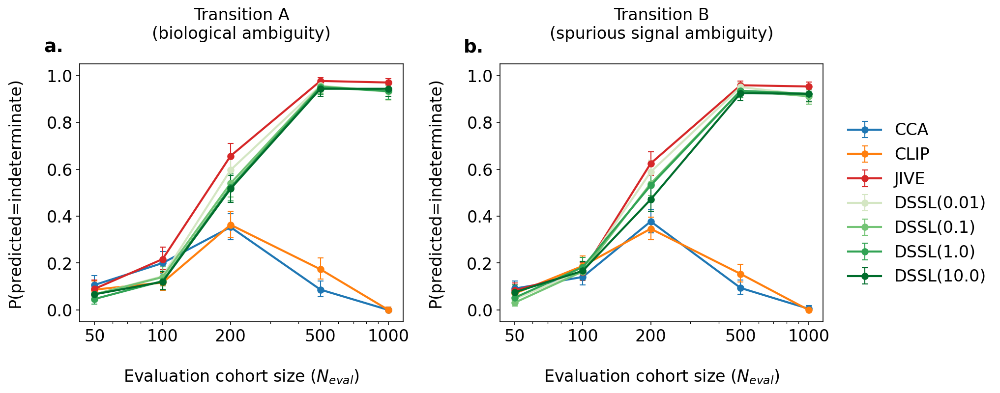

Saved fig_transition_indet_sensitivity


In [26]:

plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'font.size':        16,
    'axes.titlesize':   16,
    'axes.labelsize':   16,
    'xtick.labelsize':  16,
    'ytick.labelsize':  16,
    'legend.fontsize':  16,
})
_PANEL_LABEL_SIZE = 18

df_trans_a = df[df['alpha_config_id'].str.startswith('trans_a') & (~df['is_proxy_run']) & (df['measurement_regime']=='baseline')]
df_trans_b = df[df['alpha_config_id'].str.startswith('trans_b') & (df['is_proxy_run']) & (df['measurement_regime']=='baseline')]

fig = plt.figure(figsize=(14, 5))
gs25 = GridSpec(1, 2, figure=fig, wspace=0.3)
ax_a = fig.add_subplot(gs25[0, 0])
ax_b = fig.add_subplot(gs25[0, 1])

_rows_indet = []

for ax, df_trans, title, trans_type in [
    (ax_a, df_trans_a, 'Transition A\n(biological ambiguity)\n', 'A'),
    (ax_b, df_trans_b, 'Transition B\n(spurious signal ambiguity)\n', 'B'),
]:
    for model in MODEL_ORDER:
        sub_m=df_trans[df_trans['model_label']==model]; rates,ci_lo,ci_hi=[],[],[]
        for ne in [50,100,200,500,1000]:
            s=sub_m[sub_m['n_eval']==ne]; n=len(s)
            k=int((s['predicted_scenario']=='indeterminate').sum())
            lo,hi=clopper_pearson(k,n) if n>0 else (float('nan'),float('nan'))
            rates.append(k/n if n>0 else float('nan')); ci_lo.append(lo); ci_hi.append(hi)
            _rows_indet.append({'transition_type': trans_type, 'n_eval': ne, 'model': model,
                                'indet_rate': k/n if n>0 else float('nan'),
                                'ci_lower': lo, 'ci_upper': hi})
        rates=np.array(rates)
        ax.errorbar([50,100,200,500,1000],rates,
                    yerr=[np.maximum(0,rates-np.array(ci_lo)),np.maximum(0,np.array(ci_hi)-rates)],
                    fmt='o-',color=COLORS[model],lw=2,markersize=6,capsize=3,capthick=1,elinewidth=1,label=model)
    ax.set_xscale('log'); ax.set_xticks([50, 100, 200, 500, 1000]); ax.set_xticklabels([50, 100, 200, 500, 1000])
    ax.set_xlabel('\nEvaluation cohort size ($N_{eval}$)')
    ax.set_ylabel('P(predicted=indeterminate)\n')
    ax.set_title(title); ax.set_ylim(-0.05,1.05); ax.grid(False)

# Panel labels
for idx, ax in enumerate([ax_a, ax_b]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

fig.subplots_adjust(left=0.10, right=0.82, top=0.88, bottom=0.18, wspace=0.3)

handles, labels = ax_a.get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', ncol=1, bbox_to_anchor=(0.83, 0.5), frameon=False)

plt.show()
save_fig(fig, 'fig_transition_indet_sensitivity', pd.DataFrame(_rows_indet))

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 14,
    'axes.titlesize': 14, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
})


## TCGA Validation Figures

Figures 4, 27, 28, 29. Results loaded from `data/tcga/` (see README for data setup).

In [27]:
# TCGA setup — data paths, constants, loaders

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 16,
    'axes.titlesize': 16, 'axes.labelsize': 16,
    'legend.fontsize': 16, 'xtick.labelsize': 16, 'ytick.labelsize': 16,
})
_PANEL_LABEL_SIZE = 18

TCGA_FIGURES_DIR = Path('../../figures/tcga')
TCGA_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig_tcga(fig, name, df_csv=None):
    fig.savefig(TCGA_FIGURES_DIR / f'{name}.pdf', bbox_inches='tight')
    if df_csv is not None:
        df_csv.to_csv(TCGA_FIGURES_DIR / f'{name}.csv', index=False)
    print(f'Saved {name}')

def clopper_pearson_tcga(k, n, alpha=0.05):
    if n == 0: return float('nan'), float('nan')
    lo = beta_dist.ppf(alpha/2, k, n-k+1) if k > 0 else 0.0
    hi = beta_dist.ppf(1-alpha/2, k+1, n-k) if k < n else 1.0
    return float(lo), float(hi)

# Canonical model/scenario config
_TCGA_MODEL_LABELS = {
    'cca_K50': 'CCA', 'jive_K50': 'JIVE', 'clip_K50': 'CLIP',
    'dssl_l0.01_b0.01_K50': 'DSSL(0.01)', 'dssl_l0.1_b0.1_K50': 'DSSL(0.1)',
    'dssl_l1.0_b1.0_K50': 'DSSL(1.0)', 'dssl_l10.0_b10.0_K50': 'DSSL(10.0)',
}
MODEL_ORDER_TCGA = ['CCA', 'CLIP', 'JIVE', 'DSSL(0.01)', 'DSSL(0.1)', 'DSSL(1.0)', 'DSSL(10.0)']
COLORS_TCGA = {
    'CCA': '#1f77b4', 'CLIP': '#ff7f0e', 'JIVE': '#d62728',
    'DSSL(0.01)': '#d4e6c3', 'DSSL(0.1)': '#74c476',
    'DSSL(1.0)': '#31a354', 'DSSL(10.0)': '#006d2c',
}
SCENARIO_COLORS_TCGA = {
    'scenario_1': '#bcbd22', 'scenario_2': '#6a3d9a',
    'scenario_3': '#17becf', 'scenario_4': '#8c564b', 'indeterminate': '#7f7f7f',
}
_TASK_GT = {'s1': 'scenario_1', 's4': 'scenario_4', 's2b': 'scenario_2', 's3': 'scenario_3'}

# Data paths
OUT_DIR_V3    = DATA_DIR / 'tcga'
TITAN_V4_DIR  = OUT_DIR_V3 / 'results'
MIX_DIR       = TITAN_V4_DIR
ALPHAS        = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

MODEL_FILTER    = 'clip_K50'
MODEL_DISPLAY   = 'CLIP'
MODALITY_FILTER = 'h'

# Load pooled + extreme-C results
def _load_pooled_tcga(d):
    recs = []
    for f in sorted(Path(d).glob('pooled_random_split*.json')):
        for r in json.load(open(f)):
            r['split_type_file'] = 'pooled_random'
            recs.append(r)
    df = pd.DataFrame(recs)
    df['model_label'] = df['model'].map(_TCGA_MODEL_LABELS).fillna(df['model'])
    df['ground_truth'] = df['task_type'].map(_TASK_GT)
    return df

def _load_ec_tcga(d, prefix):
    recs = []
    for f in sorted(Path(d).glob(f'{prefix}*.json')):
        recs.extend(json.load(open(f)))
    if not recs: return pd.DataFrame()
    df = pd.DataFrame(recs)
    df['model_label'] = df['model'].map(_TCGA_MODEL_LABELS).fillna(df['model'])
    return df

df_titan_pooled = _load_pooled_tcga(TITAN_V4_DIR)
df_cca_all_ec   = _load_ec_tcga(TITAN_V4_DIR, 'cca_all_extreme_c_split')

models_present = [m for m in MODEL_ORDER_TCGA if m in df_titan_pooled['model_label'].unique()]

# Alpha-mixture loading helpers
def _mix_filter(recs):
    if MODEL_FILTER is None: return recs
    return [r for r in recs if r.get('model')==MODEL_FILTER and r.get('modality')==MODALITY_FILTER]

def _load_probe_e_rates(lt, scenario):
    rates, ses = [], []
    for alpha in ALPHAS:
        if lt == 'tp53_probe_e':
            pat = str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_{MODEL_FILTER}_split*.json')
            recs = []
            for f in glob.glob(pat): recs.extend(json.load(open(f)))
        else:
            recs = []
            for f in glob.glob(str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_split*.json')):
                recs.extend(json.load(open(f)))
            recs = _mix_filter(recs)
        if not recs: rates.append(float('nan')); ses.append(float('nan')); continue
        seeds = {}
        for r in recs:
            s = r.get('seed', r.get('split_id', 0))
            seeds.setdefault(s, []).append(r['predicted_scenario'] == scenario)
        sr = [np.mean(v) for v in seeds.values()]
        rates.append(float(np.mean(sr)))
        ses.append(float(np.std(sr)/np.sqrt(len(sr))) if len(sr)>1 else 0.0)
    return np.array(rates), np.array(ses)

def _load_probe_e_auroc(lt, field):
    means, ses = [], []
    for alpha in ALPHAS:
        if lt == 'tp53_probe_e':
            pat = str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_{MODEL_FILTER}_split*.json')
            recs = []
            for f in glob.glob(pat): recs.extend(json.load(open(f)))
        else:
            recs = []
            for f in glob.glob(str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_split*.json')):
                recs.extend(json.load(open(f)))
            recs = _mix_filter(recs)
        vals = [r[field] for r in recs if r.get(field) is not None]
        if not vals: means.append(float('nan')); ses.append(float('nan')); continue
        means.append(float(np.mean(vals)))
        ses.append(float(np.std(vals)/np.sqrt(len(vals))) if len(vals)>1 else 0.0)
    return np.array(means), np.array(ses)

_filter = _mix_filter  # alias used by probe-E figure cell
print('TCGA setup complete.')
print(f'  Pooled records: {len(df_titan_pooled):,}')
print(f'  Models: {models_present}')


TCGA setup complete.
  Pooled records: 114,100
  Models: ['CCA', 'CLIP', 'JIVE', 'DSSL(0.01)', 'DSSL(0.1)', 'DSSL(1.0)', 'DSSL(10.0)']


In [28]:
# Within-type AUROC collapse for Fig 4 panel c  (~15 min, cached to CSV)
# Computes pan-cancer vs within-cancer-type AUROC for TMB / TP53 / Age (CLIP H&E).

_cache_path = OUT_DIR_V3 / 'alpha_mixture_collapse_cache.csv'

if _cache_path.exists():
    _df_cache = pd.read_csv(_cache_path, float_precision='round_trip')
    _collapse_data = {r.label: (r.pan_mean, r.pan_se, r.within_mean, r.within_se)
                      for r in _df_cache.itertuples()}
    print(f'Loaded _collapse_data from cache: {list(_collapse_data.keys())}')
else:
    print('Cache not found — computing (~15 min)...')
    # Patient metadata + labels (patient-level data, not in data.tar.xz)
    _meta    = pd.read_csv(OUT_DIR_V3 / 'patient_meta.csv')
    _spl     = json.load(open(OUT_DIR_V3 / 'pooled_random_splits.json'))
    _train   = set(_spl[0]['cohort_a'])
    _ho      = _meta[~_meta['row_idx'].isin(_train)].copy().reset_index(drop=True)
    _tmb_df  = pd.read_csv(DATA_DIR / 'tcga/tcga_tmb.csv').set_index('patient_id')
    _muts    = pd.read_csv(DATA_DIR / 'tcga/tcga_driver_mutations.csv').set_index('patient_id')
    _clin    = pd.read_csv(DATA_DIR / 'tcga/CLINICAL.csv', low_memory=False)
    _id_col  = next(c for c in _clin.columns if 'patient' in c.lower() and 'id' in c.lower())
    _clin['pk'] = _clin[_id_col].apply(lambda x: '-'.join(str(x).split('-')[:3]) if isinstance(x,str) else x)
    _ci      = _clin.drop_duplicates('pk').set_index('pk')
    _age_col = next((c for c in _ci.columns if c.upper()=='CLIN_AGE'), None)
    _ho['log_tmb']     = np.log1p(_ho['patient_id'].map(_tmb_df['tmb_per_mb']).astype(float))
    _ho['tp53']        = _ho['patient_id'].map(_muts['TP53'])
    _ho['age']         = pd.to_numeric(_ho['patient_id'].map(_ci[_age_col]), errors='coerce') if _age_col else np.nan
    _ho['cancer_type'] = _ho['patient_id'].map(_ci['CLIN_PROJECT_ID'])
    _Zh_clip = np.load(OUT_DIR_V3 / 'representations/clip_K50/full_latents.npz')['Zh']
    _all_splits_50 = json.load(open(OUT_DIR_V3 / 'pooled_random_splits.json'))
    _ho_rows = _ho['row_idx'].values
    _ct_ho   = _ho['cancer_type'].values
    _ho['_tmb_bin'] = (_ho['log_tmb'] >= _ho['log_tmb'].median()).astype(np.int8)
    _ho['_age_bin'] = (_ho['age']     >= _ho['age'].median()).astype(np.int8)

    PANEL_C_LABELS_DEF = [
        ('TMB',  '_tmb_bin', '#e6550d'),
        ('TP53', 'tp53',     '#756bb1'),
        ('Age',  '_age_bin', '#31a354'),
    ]

    _collapse_data = {}
    for lname, col, color in PANEL_C_LABELS_DEF:
        y_ho  = _ho[col].values.astype(float)
        valid = y_ho >= 0
        yv    = y_ho[valid].astype(np.int8)
        Zv    = _Zh_clip[_ho_rows[valid]]
        ct_v  = _ct_ho[valid]
        valid_rows = _ho_rows[valid]
        pan_aurocs, within_pooled = [], []
        for spl in _all_splits_50:
            ap_ridx = np.array(spl['cohort_aprime'])
            b_ridx  = np.array(spl['cohort_b'])
            ap_v    = np.isin(valid_rows, ap_ridx)
            b_v     = np.isin(valid_rows, b_ridx)
            if yv[ap_v].sum() < 5 or (ap_v.sum() - yv[ap_v].sum()) < 5: continue
            sc    = StandardScaler().fit(Zv[ap_v])
            probe = LogisticRegression(C=0.1, max_iter=500, solver='liblinear', random_state=42)
            probe.fit(sc.transform(Zv[ap_v]), yv[ap_v])
            if b_v.sum() > 0 and len(np.unique(yv[b_v])) > 1:
                pan_aurocs.append(float(roc_auc_score(yv[b_v], probe.predict_proba(sc.transform(Zv[b_v]))[:,1])))
            eval_mask = ~ap_v
            scores_eval = probe.predict_proba(sc.transform(Zv[eval_mask]))[:,1]
            y_eval = yv[eval_mask]; ct_eval = ct_v[eval_mask]
            total_pairs = concordant_w = 0.0
            for ct in np.unique(ct_eval):
                m = ct_eval == ct
                if m.sum() < 4: continue
                y_ct = y_eval[m]; s_ct = scores_eval[m]
                n_pos = int(y_ct.sum()); n_neg = len(y_ct) - n_pos
                if n_pos < 1 or n_neg < 1: continue
                n_pairs = n_pos * n_neg
                concordant_w += roc_auc_score(y_ct, s_ct) * n_pairs
                total_pairs  += n_pairs
            if total_pairs > 0:
                within_pooled.append(concordant_w / total_pairs)
        pan_m = float(np.mean(pan_aurocs)); pan_se = float(np.std(pan_aurocs)/np.sqrt(len(pan_aurocs)))
        wit_m = float(np.mean(within_pooled)); wit_se = float(np.std(within_pooled)/np.sqrt(len(within_pooled)))
        _collapse_data[lname] = (pan_m, pan_se, wit_m, wit_se)
        print(f"  {lname}: pan={pan_m:.3f} within={wit_m:.3f} Δ={pan_m-wit_m:.3f}")
    pd.DataFrame([(k, *v) for k, v in _collapse_data.items()],
                 columns=['label', 'pan_mean', 'pan_se', 'within_mean', 'within_se']).to_csv(_cache_path, index=False)
    print(f'Saved cache → {_cache_path}')

PANEL_C_LABELS = [('TMB','_tmb_bin','#e6550d'),('TP53','tp53','#756bb1'),('Age','_age_bin','#31a354')]
MIX_LABELS = [('TMB','tmb',0.44,'#e6550d'),('TP53','tp53',0.34,'#756bb1'),('Age','age',0.27,'#31a354')]


Loaded _collapse_data from cache: ['TMB', 'TP53', 'Age']


### Figure 4 — Alpha-mixture curve with probe-score E (CLIP, H&E)

alpha* (probe-score E): TMB=0.25, TP53=0.10, Age=0.25 -> mean=0.200
TP53 probe-E S2 rates: {'0.0': np.float64(0.04), '0.1': np.float64(0.12), '0.2': np.float64(0.46), '0.3': np.float64(0.82), '0.4': np.float64(0.96), '0.5': np.float64(1.0), '0.6': np.float64(1.0), '0.7': np.float64(1.0), '0.8': np.float64(0.98), '0.9': np.float64(0.96), '1.0': np.float64(0.86)}
Saved fig_tcga_titan_alpha_mixture_curve_probe_e


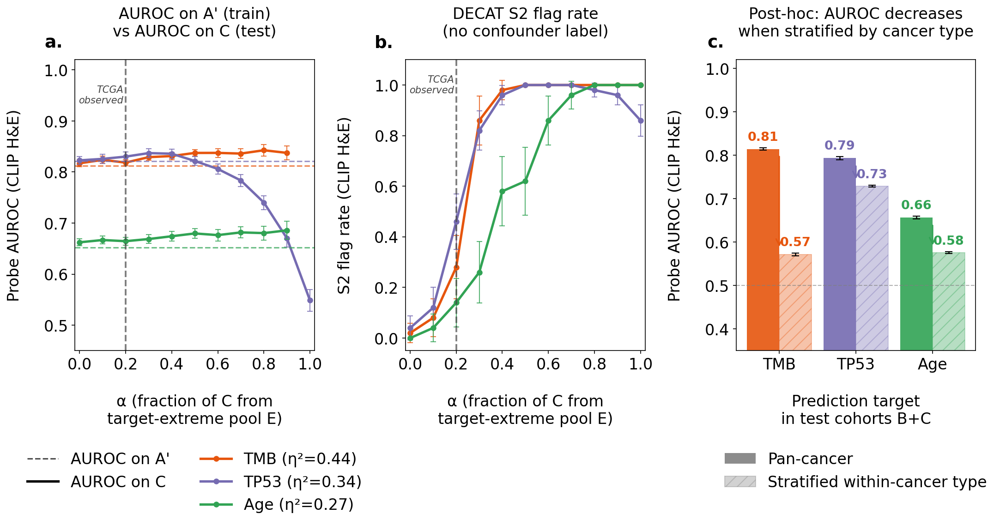

In [29]:
# Fig 4 — Alpha-mixture curve (CLIP, H&E, probe-score E)
#
#
#
# Panel c (within-type collapse) is E-independent — reuses _collapse_data.

# Load probe-score E data for TP53; reuse TMB/Age from previous cell
def _load_probe_e_rates(lt, scenario):
    """Load scenario rates; for tp53_probe_e use per-model filename."""
    rates, ses = [], []
    for alpha in ALPHAS:
        if lt == 'tp53_probe_e':
            pattern = str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_{MODEL_FILTER}_split*.json')
            recs = []
            for f in glob.glob(pattern):
                recs.extend(json.load(open(f)))
        else:
            recs = []
            for f in glob.glob(str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_split*.json')):
                recs.extend(json.load(open(f)))
            recs = _filter(recs)
        if not recs:
            rates.append(float('nan')); ses.append(float('nan')); continue
        seeds = {}
        for r in recs:
            s = r.get('seed', r.get('split_id', 0))
            seeds.setdefault(s, []).append(r['predicted_scenario'] == scenario)
        seed_rates = [np.mean(v) for v in seeds.values()]
        rates.append(float(np.mean(seed_rates)))
        ses.append(float(np.std(seed_rates)/np.sqrt(len(seed_rates))) if len(seed_rates)>1 else 0.0)
    return np.array(rates), np.array(ses)

def _load_probe_e_auroc(lt, field):
    """Load AUROC field; for tp53_probe_e use per-model filename."""
    means, ses = [], []
    for alpha in ALPHAS:
        if lt == 'tp53_probe_e':
            pattern = str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_{MODEL_FILTER}_split*.json')
            recs = []
            for f in glob.glob(pattern):
                recs.extend(json.load(open(f)))
        else:
            recs = []
            for f in glob.glob(str(MIX_DIR / f'{lt}_v3_mix_a{int(alpha*100):03d}_split*.json')):
                recs.extend(json.load(open(f)))
            recs = _filter(recs)
        vals = [r[field] for r in recs if r.get(field) is not None]
        if not vals:
            means.append(float('nan')); ses.append(float('nan')); continue
        means.append(float(np.mean(vals)))
        ses.append(float(np.std(vals)/np.sqrt(len(vals))) if len(vals)>1 else 0.0)
    return np.array(means), np.array(ses)

MIX_LABELS_PROBE_E = [
    ('TMB',  'tmb',         0.44, '#e6550d'),
    ('TP53', 'tp53_probe_e', 0.34, '#756bb1'),
    ('Age',  'age',         0.27, '#31a354'),
]

# alpha* for probe-score E: TP53 probe-E is top-10% → natural fraction ≈ 0.10
_alpha_star_tp53_probe_e = 0.10
_alpha_star_probe_e = float(np.mean([0.25, _alpha_star_tp53_probe_e, 0.25]))
print(f'alpha* (probe-score E): TMB=0.25, TP53={_alpha_star_tp53_probe_e:.2f}, Age=0.25 -> mean={_alpha_star_probe_e:.3f}')

# Quick data check
_tp53_pe_s2, _ = _load_probe_e_rates('tp53_probe_e', 'scenario_2')
_keys = [f'{a:.1f}' for a in ALPHAS]
print('TP53 probe-E S2 rates:', dict(zip(_keys, _tp53_pe_s2.round(2))))

# Build figure
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
_rows_probe_e = []

# Panel a
ax = axes[0]
for lname, lt, eta2, col in MIX_LABELS_PROBE_E:
    ap_m, _   = _load_probe_e_auroc(lt, 'auroc_ap')
    c_m, c_se = _load_probe_e_auroc(lt, 'auroc_c')
    ax.axhline(float(np.nanmean(ap_m)), color=col, lw=1.5, ls='--', alpha=0.7)
    valid = ~np.isnan(c_m)
    if valid.any():
        ax.plot(np.array(ALPHAS)[valid], c_m[valid], color=col, lw=2.5, ls='-',
                marker='o', markersize=5, label=f'{lname} (η²={eta2})')
        ax.errorbar(np.array(ALPHAS)[valid], c_m[valid], yerr=c_se[valid]*1.96,
                    fmt='none', color=col, capsize=3, capthick=1.0, elinewidth=1.0, alpha=0.8)
ax.set_xlim(-0.02, 1.02); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel('\nα (fraction of C from\ntarget-extreme pool E)')
ax.set_ylabel(f'Probe AUROC ({MODEL_DISPLAY} H&E)\n')
ax.set_ylim(0.45, 1.02); ax.grid(False)
ax.axvline(_alpha_star_probe_e, color='#444', lw=1.8, ls='--', alpha=0.7)
ax.text(_alpha_star_probe_e - 0.01, 0.97, 'TCGA\nobserved', fontsize=10,
        color='#444', va='top', ha='right', style='italic')
ax.set_title("AUROC on A' (train)\nvs AUROC on C (test)\n")
ax.text(-0.05, 1.03, 'a.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

# Panel b
ax = axes[1]
for lname, lt, eta2, col in MIX_LABELS_PROBE_E:
    s2_rates, s2_ses = _load_probe_e_rates(lt, 'scenario_2')
    if np.all(np.isnan(s2_rates)): continue
    ax.plot(ALPHAS, s2_rates, color=col, lw=2.5, ls='-',
            marker='o', markersize=5, label=f'{lname} (η²={eta2})')
    ax.errorbar(ALPHAS, s2_rates, yerr=s2_ses*1.96,
                fmt='none', color=col, capsize=3, capthick=1.0, elinewidth=1.0, alpha=0.8)
    for a, r2, se2 in zip(ALPHAS, s2_rates, s2_ses):
        if not np.isnan(r2):
            _rows_probe_e.append({'label': lname, 'eta2': eta2, 'alpha': a,
                                   's2_rate': float(r2), 's2_se': float(se2)})
ax.set_xlim(-0.02, 1.02); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel('\nα (fraction of C from\ntarget-extreme pool E)')
ax.set_ylabel('S2 flag rate (CLIP H&E)\n')
ax.set_ylim(-0.05, 1.10); ax.grid(False)
ax.axvline(_alpha_star_probe_e, color='#444', lw=1.8, ls='--', alpha=0.7)
ax.text(_alpha_star_probe_e - 0.01, 1.04, 'TCGA\nobserved', fontsize=10,
        color='#444', va='top', ha='right', style='italic')
ax.set_title('DECAT S2 flag rate\n(no confounder label)\n')
ax.text(-0.05, 1.03, 'b.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

# Panel c: reuse within-type collapse (E-independent)
ax = axes[2]
x  = np.arange(len(PANEL_C_LABELS))
bw = 0.42
for i, (lname, col_key, color) in enumerate(PANEL_C_LABELS):
    if lname not in _collapse_data: continue
    pan_m, pan_se, wit_m, wit_se = _collapse_data[lname]
    ax.bar(i - bw/2, pan_m, bw, color=color, alpha=0.90,
           label='Natural composition (B+C)' if i == 0 else '')
    ax.bar(i + bw/2, wit_m, bw, color=color, alpha=0.35,
           hatch='//', edgecolor=color, linewidth=0.8,
           label='Stratified within-type' if i == 0 else '')
    ax.errorbar(i - bw/2, pan_m, yerr=pan_se*1.96, fmt='none', color='black', capsize=4, lw=1.2)
    ax.errorbar(i + bw/2, wit_m, yerr=wit_se*1.96, fmt='none', color='black', capsize=4, lw=1.2)
    ax.text(i - bw/2, pan_m + pan_se*1.96 + 0.010, f'{pan_m:.2f}',
            ha='center', va='bottom', fontsize=13, fontweight='bold', color=color)
    ax.text(i + bw/2, wit_m + wit_se*1.96 + 0.010, f'{wit_m:.2f}',
            ha='center', va='bottom', fontsize=13, fontweight='bold', color=color)
    ax.annotate('', xy=(i, wit_m + wit_se*1.96 + 0.01),
                xytext=(i, pan_m - pan_se*1.96 - 0.01),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.5))
ax.axhline(0.5, color='gray', lw=1.0, ls='--', alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels([f'{l}' for l,_,e,c in MIX_LABELS], fontsize=16)
ax.set_ylabel(f'Probe AUROC ({MODEL_DISPLAY} H&E)\n')
ax.set_ylim(0.35, 1.02); ax.grid(False)
ax.set_xlabel('\nPrediction target\nin test cohorts B+C')
ax.set_title('Post-hoc: AUROC decreases\nwhen stratified by cancer type\n')
ax.legend(handles=[
    mpatches.Patch(facecolor='gray', alpha=0.90, label='Pan-cancer'),
    mpatches.Patch(facecolor='gray', alpha=0.35, hatch='//', edgecolor='gray',
                   label='Stratified within-cancer type'),
], frameon=False, fontsize=16, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=1)
ax.text(-0.05, 1.03, 'c.', fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
        va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

_label_handles = [plt.Line2D([0],[0], color=c, lw=2.5, ls='-', marker='o', markersize=5,
                               label=f'{l} (η²={e})') for l,_,e,c in MIX_LABELS_PROBE_E]
_line_a = plt.Line2D([0],[0], color='k', lw=1.5, ls='--', alpha=0.7, label="AUROC on A'")
_line_c = plt.Line2D([0],[0], color='k', lw=2.5, ls='-',             label='AUROC on C')
_blank  = plt.Line2D([0],[0], color='none', label=' ')
axes[0].legend(handles=[_line_a, _line_c, _blank,
                         _label_handles[0], _label_handles[1], _label_handles[2]],
               frameon=False, fontsize=16,
               loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=2)

fig.subplots_adjust(left=0.07, right=0.72, top=0.88, bottom=0.18, wspace=0.38)
save_fig_tcga(fig, 'fig_tcga_titan_alpha_mixture_curve_probe_e', pd.DataFrame(_rows_probe_e))
plt.show()


### Figure 28 — DECAT detection rates (TCGA TITAN)

Saved fig_tcga_titan_detection_curves


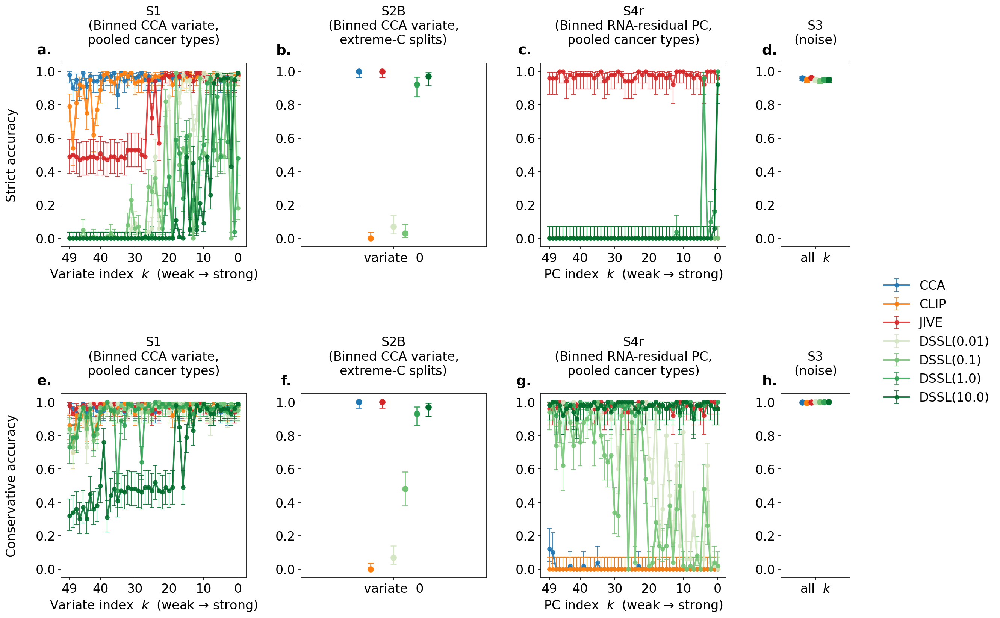

In [30]:
# Fig 28 — Detection rate vs task index (designed labels)
#
# Panels a/e: S1  — CCA canonical variates, pooled splits (both modalities)
# Panels b/f: S2B — CCA variate 0, extreme-C splits → S2 (single dot per model)
# Panels c/g: S4r — RNA-specific PCs, pooled splits (RNA modality only)
# Panels d/h: S3  — random labels, pooled splits (single dot per model)
#
# S1 and S4r x-axes run 49→0 (left=weakest signal, right=strongest),
# mirroring fig_main_baseline_alpha_curves where signal strength increases left→right.
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 16,
    'axes.titlesize': 16, 'axes.labelsize': 16,
    'legend.fontsize': 16, 'xtick.labelsize': 16, 'ytick.labelsize': 16,
})

models_present = [m for m in MODEL_ORDER if m in df_titan_pooled['model_label'].unique()]

df_s2b_ec_v0 = df_cca_all_ec[(df_cca_all_ec['task_type'] == 's2b') &
                               (df_cca_all_ec['task_idx'] == 0)]

SCENARIO_TITLES = {
    's1':  'S1\n(Binned CCA variate,\npooled cancer types)\n',
    's2b': 'S2B\n(Binned CCA variate,\nextreme-C splits)\n',
    's4':  'S4r\n(Binned RNA-residual PC,\npooled cancer types)\n',
    's3':  'S3\n(noise)\n',
}
ROW_YLABELS   = {False: 'Strict accuracy\n', True: 'Conservative accuracy\n'}
TASK_GT_LOCAL = {'s1': 'scenario_1', 's4': 'scenario_4', 's3': 'scenario_3'}

fig = plt.figure(figsize=(20, 11))
gs  = GridSpec(2, 4, figure=fig, width_ratios=[4, 4, 4, 1.5], hspace=0.8, wspace=0.35)
axes = [[fig.add_subplot(gs[r, c]) for c in range(4)] for r in range(2)]
_rows = []

for row_i, is_conservative in enumerate([False, True]):
    for col_i, tt in enumerate(['s1', 's2b', 's4', 's3']):
        ax = axes[row_i][col_i]

        if tt in ('s1', 's4'):
            if tt == 's4':
                src = df_titan_pooled[(df_titan_pooled['task_type'] == tt) &
                                      (df_titan_pooled['modality'] == 'r')]
            else:
                src = df_titan_pooled[df_titan_pooled['task_type'] == tt]
            gt     = TASK_GT_LOCAL[tt]
            k_vals = sorted(src['task_idx'].unique())
            for model in models_present:
                sub_m = src[src['model_label'] == model]
                rates, ci_lo, ci_hi = [], [], []
                for k in k_vals:
                    sub_k = sub_m[sub_m['task_idx'] == k]; n = len(sub_k)
                    kk = int(((sub_k['predicted_scenario']==gt)|
                              (sub_k['predicted_scenario']=='indeterminate')).sum()
                             if is_conservative else (sub_k['predicted_scenario']==gt).sum())
                    lo, hi = clopper_pearson_tcga(kk, n)
                    rates.append(kk/n if n>0 else float('nan'))
                    ci_lo.append(lo); ci_hi.append(hi)
                    _rows.append({'task_type': tt, 'task_idx': k, 'model': model,
                                  'source': 'pooled', 'modality': 'r' if tt=='s4' else 'both',
                                  'row_type': 'conservative' if is_conservative else 'strict',
                                  'rate': kk/n if n>0 else float('nan'), 'ci_lower': lo, 'ci_upper': hi})
                rates = np.array(rates)
                ax.errorbar(k_vals, rates,
                            yerr=[np.maximum(0,rates-np.array(ci_lo)), np.maximum(0,np.array(ci_hi)-rates)],
                            fmt='o-', color=COLORS_TCGA[model], lw=2, markersize=5,
                            capsize=3, capthick=1.0, elinewidth=1.0, label=model, alpha=0.85)
            ax.set_xticks([0, 10, 20, 30, 40, 49])
            ax.invert_xaxis()   # 49→0: weak signal on left, strong on right
            xlabel = ('Variate index  $k$  (weak → strong)'
                      if tt == 's1' else 'PC index  $k$  (weak → strong)')
            ax.set_xlabel(xlabel)

        elif tt == 's2b':
            gt_e = 'scenario_2'
            for m_i, model in enumerate(models_present):
                sub_m = df_s2b_ec_v0[df_s2b_ec_v0['model_label'] == model]
                n     = len(sub_m)
                kk    = int(((sub_m['predicted_scenario']==gt_e)|
                             (sub_m['predicted_scenario']=='indeterminate')).sum()
                            if is_conservative else (sub_m['predicted_scenario']==gt_e).sum())
                rate  = kk / n if n > 0 else float('nan')
                lo, hi = clopper_pearson_tcga(kk, n)
                jitter = (m_i - (len(models_present) - 1) / 2) * 0.05
                ax.errorbar(jitter, rate, yerr=[[np.maximum(0, rate-lo)], [np.maximum(0, hi-rate)]],
                            fmt='o', color=COLORS_TCGA[model], markersize=7,
                            capsize=4, capthick=1.2, elinewidth=1.2)
                _rows.append({'task_type': tt, 'task_idx': 0, 'model': model, 'source': 'cca_extreme_c',
                              'modality': 'both', 'row_type': 'conservative' if is_conservative else 'strict',
                              'rate': rate, 'ci_lower': lo, 'ci_upper': hi})
            ax.set_xlim(-0.4, 0.4); ax.set_xticks([0]); ax.set_xticklabels(['variate  0'])

        else:  # S3
            src = df_titan_pooled[df_titan_pooled['task_type'] == tt]
            for m_i, model in enumerate(models_present):
                sub_m = src[src['model_label']==model]; n = len(sub_m)
                kk = int(((sub_m['predicted_scenario']=='scenario_3')|
                          (sub_m['predicted_scenario']=='indeterminate')).sum()
                         if is_conservative else (sub_m['predicted_scenario']=='scenario_3').sum())
                rate = kk/n if n>0 else float('nan')
                lo, hi = clopper_pearson_tcga(kk, n)
                jitter = (m_i-(len(models_present)-1)/2)*0.05
                ax.errorbar(jitter, rate, yerr=[[np.maximum(0,rate-lo)],[np.maximum(0,hi-rate)]],
                            fmt='o', color=COLORS_TCGA[model], markersize=7, capsize=4, capthick=1.2, elinewidth=1.2)
                _rows.append({'task_type': tt, 'task_idx': 0, 'model': model, 'source': 'pooled',
                              'modality': 'both', 'row_type': 'conservative' if is_conservative else 'strict',
                              'rate': rate, 'ci_lower': lo, 'ci_upper': hi})
            ax.set_xlim(-0.4, 0.4); ax.set_xticks([0]); ax.set_xticklabels(['all  $k$'])

        ax.set_ylim(-0.05, 1.05)
        ax.grid(False)
        ax.set_title(SCENARIO_TITLES[tt])
        if col_i == 0:
            ax.set_ylabel(ROW_YLABELS[is_conservative])

# Panel labels
for idx, ax in enumerate([axes[r][c] for r in range(2) for c in range(4)]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

# Legend outside the grid, vertically centred
handles, lbls = axes[0][0].get_legend_handles_labels()
fig.legend(handles, lbls, loc='center left', bbox_to_anchor=(0.84, 0.5),
           frameon=False, ncol=1)

fig.subplots_adjust(left=0.12, right=0.82, top=0.95, bottom=0.12, hspace=0.8, wspace=0.35)

save_fig_tcga(fig, 'fig_tcga_titan_detection_curves', pd.DataFrame(_rows))
plt.show()

### Figure 29 — FSCR (TCGA TITAN)

Saved fig_tcga_titan_fscr


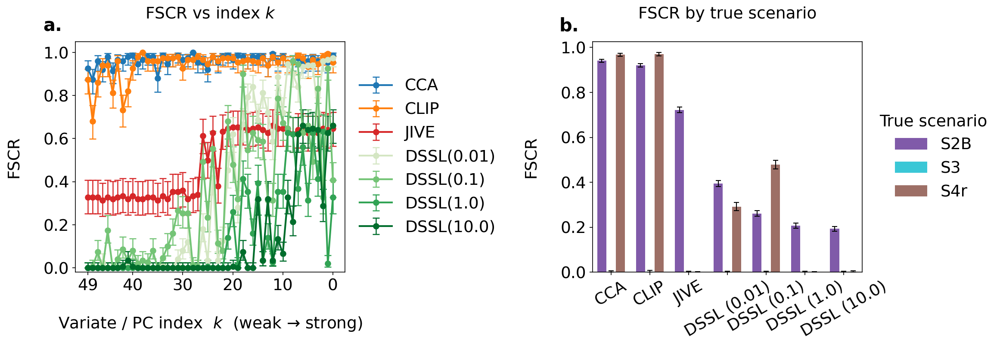

In [31]:
# Fig 29 — FSCR  (TCGA TITAN) — analog of synthetic Fig 3
#
# Panel a: FSCR vs variate/PC index k=0-49, pooled across S2B + S4r (RNA-only).
#          X-axis runs 49→0 (left=weakest signal, right=strongest).
# Panel b: FSCR decomposed by true scenario (S2B, S3, S4r) — full non-S1 pool.
#
# Layout: figsize=(14,5.5) with manual axis positioning gives panels with the
# same near-square proportions (~4.2 × 3.6 in) as fig_fscr_by_model.
# Colors from SCENARIO_COLORS (cell 1).

plt.rcParams.update({
    'font.family':     'DejaVu Sans',
    'font.size':       18,
    'axes.titlesize':  18,
    'axes.labelsize':  18,
    'legend.fontsize': 18,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
})
_PANEL_LABEL_SIZE = 20

GT_LABELS_FSCR = {'scenario_2': 'S2B', 'scenario_3': 'S3', 'scenario_4': 'S4r'}
GT_ORDER_FSCR  = ['scenario_2', 'scenario_3', 'scenario_4']

df_s4r    = df_titan_pooled[(df_titan_pooled['task_type'] == 's4') &
                             (df_titan_pooled['modality'] == 'r')].copy()
df_s4r['ground_truth'] = 'scenario_4'
df_s2b_s3 = df_titan_pooled[df_titan_pooled['task_type'].isin(['s2b', 's3'])].copy()
df_nons1  = pd.concat([df_s4r, df_s2b_s3], ignore_index=True)
df_nons1  = df_nons1[df_nons1['ground_truth'] != 'scenario_1']

df_panel_a = df_nons1[(df_nons1['ground_truth'] != 'scenario_3') &
                       (df_nons1['task_idx'] <= 49)]

fig = plt.figure(figsize=(14, 5.5))
gs3 = GridSpec(1, 3, figure=fig, width_ratios=[4, 3, 4], wspace=0)
ax_a   = fig.add_subplot(gs3[0, 0])
ax_leg = fig.add_subplot(gs3[0, 1])
ax_b   = fig.add_subplot(gs3[0, 2])
ax_leg.axis('off')

_rows_fscr = []

# Panel a
k_vals = sorted(df_panel_a['task_idx'].unique())

for model in models_present:
    rates, ci_lo, ci_hi = [], [], []
    for k in k_vals:
        sub = df_panel_a[(df_panel_a['model_label'] == model) & (df_panel_a['task_idx'] == k)]
        n   = len(sub)
        kk  = int((sub['predicted_scenario'] == 'scenario_1').sum())
        lo, hi = clopper_pearson_tcga(kk, n)
        rates.append(kk / n if n > 0 else float('nan'))
        ci_lo.append(lo); ci_hi.append(hi)
        _rows_fscr.append({'panel': 'variate', 'model': model, 'task_idx': k,
                           'n': n, 'fscr': kk / n if n > 0 else float('nan'),
                           'ci_lower': lo, 'ci_upper': hi, 'dataset': 'TITAN'})
    rates = np.array(rates)
    ax_a.errorbar(k_vals, rates,
                  yerr=[np.maximum(0, rates - np.array(ci_lo)),
                        np.maximum(0, np.array(ci_hi) - rates)],
                  fmt='o-', color=COLORS_TCGA[model], lw=2, markersize=6,
                  capsize=4, capthick=1.2, elinewidth=1.2, label=model)

ax_a.set_xticks([0, 10, 20, 30, 40, 49])
ax_a.invert_xaxis()
ax_a.set_xlabel('\nVariate / PC index  $k$  (weak → strong)')
ax_a.set_ylabel('FSCR\n')
ax_a.set_ylim(-0.02, 1.05)
ax_a.set_title('FSCR vs index $k$\n')
ax_a.grid(False)

handles, labels = ax_a.get_legend_handles_labels()
ax_leg.legend(handles, labels, loc='center left', frameon=False, ncol=1)

# Panel b
n_m  = len(models_present)
n_g  = len(GT_ORDER_FSCR)
bw   = 0.25
gg   = 0.30
xtick_pos, xtick_labels = [], []

for m_i, model in enumerate(models_present):
    gc = m_i * (n_g * bw + gg)
    for g_i, gt in enumerate(GT_ORDER_FSCR):
        sub  = df_nons1[(df_nons1['model_label'] == model) &
                        (df_nons1['ground_truth'] == gt)]
        n    = len(sub)
        k    = int((sub['predicted_scenario'] == 'scenario_1').sum())
        rate = k / n if n > 0 else float('nan')
        lo, hi = clopper_pearson_tcga(k, n)
        x = gc + g_i * bw
        ax_b.bar(x, rate, bw, color=SCENARIO_COLORS_TCGA[gt], alpha=0.85,
                 label=GT_LABELS_FSCR[gt] if m_i == 0 else '')
        ax_b.errorbar(x, rate,
                      yerr=[[np.maximum(0, rate - lo)], [np.maximum(0, hi - rate)]],
                      fmt='none', color='black', capsize=3, lw=1)
        _rows_fscr.append({'panel': 'by_scenario', 'model': model,
                           'ground_truth': gt, 'gt_label': GT_LABELS_FSCR[gt],
                           'n': n, 'k': k, 'fscr': rate,
                           'ci_lower': lo, 'ci_upper': hi, 'dataset': 'TITAN'})
    xtick_pos.append(gc + (n_g - 1) * bw / 2)
    xtick_labels.append(model)

ax_b.set_xlim(-bw, (n_m - 1) * (n_g * bw + gg) + n_g * bw)
ax_b.set_xticks(xtick_pos)
ax_b.set_xticklabels(
    [m.replace('DSSL(', 'DSSL (') for m in xtick_labels],
    rotation=30, ha='center')
ax_b.set_ylabel('FSCR\n')
ax_b.set_title('FSCR by true scenario\n')
ax_b.legend(title='True scenario', loc='center left',
            bbox_to_anchor=(1.01, 0.5), frameon=False)
ax_b.grid(False)

for idx, ax in enumerate([ax_a, ax_b]):
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[idx]}.',
            transform=ax.transAxes, fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False)

# Manual layout: snap axes together, matching manuscript panel proportions
fig.subplots_adjust(left=0.10, right=0.92, top=0.90, bottom=0.25)
_avail = 0.92 - 0.10          # 0.82 of figure width
_pw    = _avail * 4 / 11      # data panel (ratio 4 of total [4,3,4]=11)
_lw    = _avail * 3 / 11      # legend column
_h     = ax_a.get_position().height
_y0    = ax_a.get_position().y0
_x0    = 0.10

ax_a.set_position(  [_x0,            _y0, _pw, _h])
ax_leg.set_position([_x0 + _pw,      _y0, _lw, _h])
ax_b.set_position(  [_x0 + _pw + _lw + 0.05, _y0, _pw, _h])

save_fig_tcga(fig, 'fig_tcga_titan_fscr', pd.DataFrame(_rows_fscr))
plt.show()

### Figure 30 — Power curve (TCGA TITAN)

Saved fig_tcga_titan_power_curve


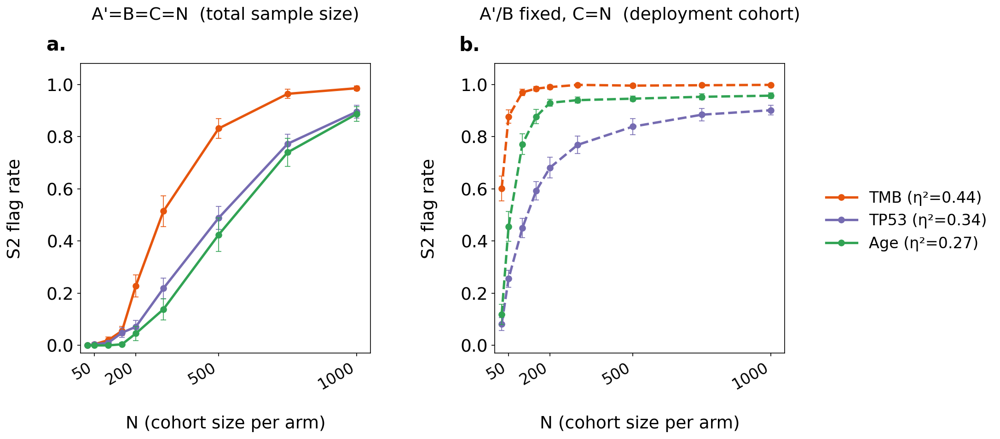


Practical N recommendations (S2 detection rate):
 Label     η²   80% equal_N   95% equal_N   80% vary_C   95% vary_C
--------------------------------------------------------------
   TMB   0.44           500           750           50          100
  TP53   0.34          1000         >1000          500        >1000
   Age   0.27          1000         >1000          150          750


In [32]:
# Fig 30 — Power curve: S2 detection rate vs cohort size N

POWER_DIR = OUT_DIR_V3 / 'results'
N_VALS    = [25, 50, 100, 150, 200, 300, 500, 750, 1000]
TICK_VALS = [50, 200, 500, 1000]  # subset to avoid overlap

POWER_LABELS = [
    ('TMB',  'tmb',  0.44, '#e6550d'),
    ('TP53', 'tp53',     0.34, '#756bb1'),
    ('Age',  'age',  0.27, '#31a354'),
]

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 18,
    'axes.titlesize': 18, 'axes.labelsize': 18,
    'legend.fontsize': 16, 'xtick.labelsize': 16, 'ytick.labelsize': 18,
})

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
_rows_pc = []

DESIGN_STYLES = {
    'equal_N': ('-',  'A\'=B=C=N  (total sample size)'),
    'vary_C':  ('--', 'A\'/B fixed, C=N  (deployment cohort)'),
}

for ax_i, (design, (ls, design_label)) in enumerate(DESIGN_STYLES.items()):
    ax = axes[ax_i]
    for lname, lt, eta2, col in POWER_LABELS:
        rates, ses = [], []
        for n in N_VALS:
            recs = []
            for f in glob.glob(str(POWER_DIR / f'{lt}_power_{design}_N{n}_split*.json')):
                recs.extend(json.load(open(f)))
            if not recs:
                rates.append(float('nan')); ses.append(float('nan')); continue
            # Per-seed mean then SE
            seeds = {}
            for r in recs:
                s = r.get('seed', r.get('split_id', 0))
                seeds.setdefault(s, []).append(r['predicted_scenario']=='scenario_2')
            sr = [np.mean(v) for v in seeds.values()]
            rates.append(float(np.mean(sr)))
            ses.append(float(np.std(sr)/np.sqrt(len(sr))) if len(sr)>1 else 0.)
            _rows_pc.append({'label': lname, 'eta2': eta2, 'design': design,
                             'n': n, 'rate': rates[-1], 'se': ses[-1]})

        rates, ses = np.array(rates), np.array(ses)
        ax.plot(N_VALS, rates, color=col, lw=2.5, ls=ls, marker='o', markersize=6,
                label=f'{lname} (η²={eta2})')
        ax.errorbar(N_VALS, rates, yerr=ses*1.96,
                    fmt='none', color=col, capsize=3, capthick=1.0, elinewidth=1.0, alpha=0.8)

    ax.set_xlabel('\nN (cohort size per arm)')
    ax.set_ylabel('S2 flag rate\n')
    ax.set_ylim(-0.03, 1.08)
    ax.set_xlim(0, 1050)
    ax.set_xticks(TICK_VALS)
    ax.set_xticklabels([str(n) for n in TICK_VALS], rotation=30, ha='right')
    ax.set_title(f'{design_label}\n\n')
    ax.grid(False)
    ax.text(-0.05, 1.03, f'{string.ascii_lowercase[ax_i]}.',
            fontweight='bold', fontsize=_PANEL_LABEL_SIZE,
            va='bottom', ha='right', clip_on=False, transform=ax.transAxes)

# Square panels via manual positioning
fig.subplots_adjust(left=0.07, right=0.90, top=0.88, bottom=0.18)
_avail_h = (0.88 - 0.18)          # 0.70 of figure height
_pw      = _avail_h * 6 / 20      # panel width = panel height in fig fraction
_gap     = 0.09
_x0      = 0.09
_y0      = 0.18
axes[0].set_position([_x0,              _y0, _pw, _avail_h])
axes[1].set_position([_x0 + _pw + _gap, _y0, _pw, _avail_h])
# Shared legend: label colors — placed to the right of both panels
_handles = [plt.Line2D([0],[0], color=c, lw=2.5, marker='o', markersize=6, label=f'{l} (η²={e})')
            for l,_,e,c in POWER_LABELS]
fig.legend(handles=_handles, loc='center left',
           bbox_to_anchor=(_x0 + _pw + _gap + _pw + 0.02, 0.5),
           frameon=False, ncol=1)
save_fig_tcga(fig, 'fig_tcga_titan_power_curve', pd.DataFrame(_rows_pc))
plt.show()

# Practical recommendations table
print("\nPractical N recommendations (S2 detection rate):")
print(f"{'Label':>6}  {'η²':>5}  {'80% equal_N':>12}  {'95% equal_N':>12}  "
      f"{'80% vary_C':>11}  {'95% vary_C':>11}")
print("-"*62)
for lname, lt, eta2, col in POWER_LABELS:
    for design, thresh_label in [('equal_N','equal'), ('vary_C','vary')]:
        rates_by_n = {}
        for n in N_VALS:
            recs = []
            for f in glob.glob(str(POWER_DIR / f'{lt}_power_{design}_N{n}_split*.json')):
                recs.extend(json.load(open(f)))
            if recs:
                rates_by_n[n] = sum(r['predicted_scenario']=='scenario_2' for r in recs)/len(recs)
    # Find minimum N for 80% and 95%
    def min_n(design, thresh):
        for n in N_VALS:
            recs = []
            for f in glob.glob(str(POWER_DIR / f'{lt}_power_{design}_N{n}_split*.json')):
                recs.extend(json.load(open(f)))
            if recs and sum(r['predicted_scenario']=='scenario_2' for r in recs)/len(recs) >= thresh:
                return n
        return '>1000'
    print(f"{lname:>6}  {eta2:>5.2f}  {str(min_n('equal_N',0.80)):>12}  "
          f"{str(min_n('equal_N',0.95)):>12}  {str(min_n('vary_C',0.80)):>11}  "
          f"{str(min_n('vary_C',0.95)):>11}")

### Figure 5 — Driver gene FM comparison (S2 AUC vs within-type collapse Δ)

In [33]:
from scipy import stats

FM_COLORS = {
    'titan':        '#1f77b4',
    'conch':        '#ff7f0e',
    'uni':          '#2ca02c',
    'hoptimus0':    '#9467bd',
    'openmidnight': '#8c564b',
}
FM_PRETTY = {
    'titan':        'TITAN',
    'conch':        'CONCH',
    'uni':          'UNI',
    'hoptimus0':    'H-Optimus-0',
    'openmidnight': 'OpenMidnight',
}
FM_ORD   = ['conch', 'titan', 'hoptimus0', 'openmidnight', 'uni']
DG_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Within-type AUROC collapse
col = pd.DataFrame(json.load(open(OUT_DIR_V3 / 'driver_gene_collapse_records.json')))
col = col.rename(columns={'collapse': 'delta'})

# Probe-score E records — merge all available result files
_pattern = str(OUT_DIR_V3 / 'driver_gene_alpha_mixture_probe_e*.json')
_all_recs = []
for _p in sorted(glob.glob(_pattern)):
    _all_recs += json.load(open(_p))

mix = (pd.DataFrame(_all_recs)
         .drop_duplicates(subset=['label', 'fm', 'alpha', 'split_id'], keep='last')
         .reset_index(drop=True))

# KRAS probe-score E sweep (unimodal baseline)
kras = mix[mix['label'] == 'KRAS'].copy()

print(f'Collapse genes:  {sorted(col["gene"].unique())}')
print(f'Mix genes:       {sorted(mix["label"].unique())} ({mix["label"].nunique()} / 16 complete)')
print(f'KRAS sweep rows: {len(kras)}')


Collapse genes:  ['APC', 'ARID1A', 'BRAF', 'CDH1', 'CTNNB1', 'FBXW7', 'GATA3', 'IDH1', 'KRAS', 'MAP3K1', 'NF1', 'PIK3CA', 'PTEN', 'RB1', 'TP53', 'VHL']
Mix genes:       ['APC', 'ARID1A', 'BRAF', 'CDH1', 'CTNNB1', 'FBXW7', 'GATA3', 'IDH1', 'KRAS', 'MAP3K1', 'NF1', 'PIK3CA', 'PTEN', 'RB1', 'TP53', 'VHL'] (16 / 16 complete)
KRAS sweep rows: 1500


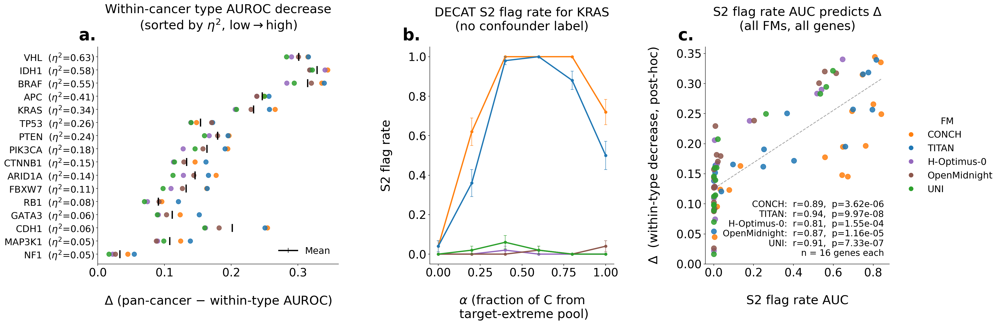

In [34]:
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 24,
    'axes.titlesize': 24, 'axes.labelsize': 24,
    'xtick.labelsize': 22, 'ytick.labelsize': 22,
})
_PANEL_LABEL_SIZE = 32

def s2_auc(sub, alphas=DG_ALPHAS):
    rates = [sub[sub['alpha'] == a]['verdict'].eq('S2').mean() for a in alphas]
    return float(np.trapezoid(rates, alphas))

auc_rows = [
    {'gene': gene, 'fm': fm, 's2_auc': s2_auc(grp)}
    for (gene, fm), grp in mix.groupby(['label', 'fm'])
]
df_auc     = pd.DataFrame(auc_rows)
df_scatter = df_auc.merge(col[['gene', 'fm', 'delta', 'eta2']], on=['gene', 'fm'])

gene_order = (col.groupby('gene')['eta2'].first()
                 .sort_values(ascending=True).index.tolist())
eta2_map   = col.groupby('gene')['eta2'].first().to_dict()

fig = plt.figure(figsize=(28, 8))
gs  = fig.add_gridspec(1, 3, width_ratios=[1.7, 1.3, 1.3])
ax_a = fig.add_subplot(gs[0])
ax_b = fig.add_subplot(gs[1])
ax_c = fig.add_subplot(gs[2])

ys = np.arange(len(gene_order))
for fm in FM_ORD:
    sub = col[col['fm'] == fm].set_index('gene')
    xs  = [sub.loc[g, 'delta'] if g in sub.index else np.nan for g in gene_order]
    ax_a.scatter(xs, ys, color=FM_COLORS[fm], s=80, alpha=0.85, zorder=3)

means = [col[col['gene'] == g]['delta'].mean() for g in gene_order]
ax_a.scatter(means, ys, color='black', marker='|', s=250, zorder=4, linewidths=2.5)

ax_a.set_yticks(ys)
ax_a.set_yticklabels(
    [f'{g}  ($\\eta^2$={eta2_map[g]:.2f})' for g in gene_order],
    fontsize=18
)
ax_a.axvline(0, color='gray', lw=1.0, ls='--', alpha=0.6)
ax_a.set_xlabel('\n$\\Delta$ (pan-cancer $-$ within-type AUROC)')
ax_a.set_title('Within-cancer type AUROC decrease\n(sorted by $\\eta^2$, low$\\rightarrow$high)\n')
ax_a.legend(
    handles=[plt.Line2D([0],[0], marker='|', color='black', markersize=10,
                         lw=2.5, label='Mean')],
    fontsize=18, frameon=False, loc='lower right'
)
ax_a.spines[['top', 'right']].set_visible(False)
ax_a.text(-0.08, 1.03, 'a.', fontweight='bold',
          fontsize=_PANEL_LABEL_SIZE, transform=ax_a.transAxes)

for fm in FM_ORD:
    sub  = kras[kras['fm'] == fm]
    rates, errs = [], []
    for a in DG_ALPHAS:
        seeds = sub[sub['alpha'] == a].groupby('split_id')['verdict'].apply(lambda x: x.eq('S2').mean())
        rates.append(float(seeds.mean()))
        errs.append(float(seeds.sem()) if len(seeds) > 1 else 0.0)
    rates, errs = np.array(rates), np.array(errs)
    ax_b.plot(DG_ALPHAS, rates, '-o', color=FM_COLORS[fm], lw=2.5, ms=5)
    ax_b.errorbar(DG_ALPHAS, rates, yerr=errs, fmt='none',
                  color=FM_COLORS[fm], capsize=3, capthick=1.0, elinewidth=1.0, alpha=0.8)
ax_b.set_xlabel('\n$\\alpha$ (fraction of C from\n target-extreme pool)')
ax_b.set_ylabel('S2 flag rate\n')
ax_b.set_title('DECAT S2 flag rate for KRAS\n(no confounder label)\n')
ax_b.set_xlim(-0.05, 1.05)
ax_b.set_ylim(-0.05, 1.05)
ax_b.spines[['top', 'right']].set_visible(False)
ax_b.text(-0.15, 1.03, 'b.', fontweight='bold',
          fontsize=_PANEL_LABEL_SIZE, transform=ax_b.transAxes)

for fm in FM_ORD:
    sub = df_scatter[df_scatter['fm'] == fm]
    ax_c.scatter(sub['s2_auc'], sub['delta'],
                 color=FM_COLORS[fm], s=100, alpha=0.85, zorder=3)

x_all = df_scatter['s2_auc'].values
y_all = df_scatter['delta'].values
m, b  = np.polyfit(x_all, y_all, 1)
xs_fit = np.linspace(x_all.min(), x_all.max(), 100)
ax_c.plot(xs_fit, m * xs_fit + b, '--', color='gray', lw=1.5, alpha=0.7, zorder=1)

n_genes = df_scatter['gene'].nunique()
_fm_stats = []
for _fm in FM_ORD:
    _sub = df_scatter[df_scatter['fm'] == _fm]
    _r, _p = stats.spearmanr(_sub['s2_auc'], _sub['delta'])
    _fm_stats.append((_fm, _r, _p))
_anno = '\n'.join([f'{FM_PRETTY[fm]}:  r={r:.2f},  p={p:.2e}' for fm,r,p in _fm_stats])
_anno += f'\nn = {n_genes} genes each'
ax_c.text(0.97, 0.03, _anno, transform=ax_c.transAxes, fontsize=17,
          va='bottom', ha='right')
ax_c.set_xlabel('\nS2 flag rate AUC')
ax_c.set_ylabel('$\\Delta$  (within-type decrease, post-hoc)\n')
ax_c.set_title('S2 flag rate AUC predicts $\\Delta$\n(all FMs, all genes)\n')
ax_c.spines[['top', 'right']].set_visible(False)
ax_c.text(-0.15, 1.03, 'c.', fontweight='bold',
          fontsize=_PANEL_LABEL_SIZE, transform=ax_c.transAxes)

fm_handles = [
    plt.Line2D([0],[0], marker='o', color='w',
               markerfacecolor=FM_COLORS[fm], markersize=10, label=FM_PRETTY[fm])
    for fm in FM_ORD
]
ax_c.legend(handles=fm_handles, loc='center left', fontsize=18,
             frameon=False, title='FM', title_fontsize=18,
             bbox_to_anchor=(1.02, 0.5))

fig.subplots_adjust(left=0.12, right=0.88, top=0.88, bottom=0.15, wspace=0.45)

out = Path('../../figures/tcga') / 'fig_tcga_driver_gene_balanced_s2_vs_delta.pdf'
fig.savefig(out, bbox_inches='tight', dpi=150)
fig.savefig(str(out).replace('.pdf', '.png'), bbox_inches='tight', dpi=150)
plt.show()